# Polymer Property Prediction — Exploratory Data Analysis

## Purpose

Understand the polymer dataset before cleaning, feature engineering
and predictive modelling.

## Research question

What information does the dataset contain, how reliable is it,
and which polymer properties can we model using the available labels?

## Data files

- train.csv
- test.csv
- sample_submission.csv
- dataset1.csv
- dataset2.csv
- dataset3.csv
- dataset4.csv

## Questions to investigate

1. What does one row represent?
2. How were the property values generated?
3. What are the units and simulation conditions?
4. Which targets are available for each structure?
5. Are structures duplicated within or across files?
6. Can we process the polymer SMILES consistently?
7. Are the supplementary datasets comparable to the main dataset?

## Analysis principles

- Preserve the original files.
- Do not impute missing target values.
- Investigate unusual values before removing them.
- Record sample sizes for every comparison.
- Separate observations, hypotheses and decisions.
- Keep the final evaluation set separate from model development.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("pandas version:", pd.__version__)
print("Working directory:", Path.cwd())

Python executable: c:\Users\EMS-User\capstone_virtual_lab_mohamed_suhmi\.venv\Scripts\python.exe
Python version: 3.13.14
pandas version: 3.0.5
Working directory: c:\Users\EMS-User\capstone_virtual_lab_mohamed_suhmi\notebooks


Checking the data folder. Our notebook operates within the `notebooks` subfolder. Therefore, we first move up one level to the project folder.

Pseudocode:

1- Determine the current working directory. (Aktuellen Arbeitsordner ermitteln.)

2- Identify the parent project folder. (Übergeordneten Projektordner bestimmen.)

3- Construct the path to the `data` folder. (Den Pfad zum Ordner data bilden.)

4- Check if this folder exists. (Prüfen, ob dieser Ordner existiert.)

5- List existing CSV files. (Vorhandene CSV-Dateien auflisten.)

In [2]:
# Locate the project and data directories
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Data directory exists:", DATA_DIR.is_dir())

# List CSV files, including files in subdirectories
csv_files = sorted(DATA_DIR.rglob("*.csv"))

print("Number of CSV files:", len(csv_files))

for file_path in csv_files:
    print(file_path.relative_to(PROJECT_ROOT))
    

Project root: c:\Users\EMS-User\capstone_virtual_lab_mohamed_suhmi
Data directory: c:\Users\EMS-User\capstone_virtual_lab_mohamed_suhmi\data
Data directory exists: True
Number of CSV files: 7
data\raw\sample_submission.csv
data\raw\test.csv
data\raw\train.csv
data\raw\train_supplement\dataset1.csv
data\raw\train_supplement\dataset2.csv
data\raw\train_supplement\dataset3.csv
data\raw\train_supplement\dataset4.csv


## 2. Dataset inventory

Before analysing individual datasets, we inspect all seven CSV files.

For each file, we record:
- its relative path;
- the number of rows and columns;
- the column names.

This provides an overview of the available data and its structure.

| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `datasets = {}` | Ein leeres Dictionary speichert die eingelesenen Tabellen. | An empty dictionary stores the loaded tables. |
| `inventory_rows = []` | Eine leere Liste sammelt die Angaben für unsere Übersicht. | An empty list collects the information for our overview. |
| `for file_path in csv_files:` | Bearbeitet jede der sieben gefundenen Dateien. | Processes each of the seven files found. |
| `.relative_to(DATA_DIR)` | Kürzt den Pfad auf den Teil innerhalb von `data`. | Makes the path relative to the `data` directory. |
| `.as_posix()` | Verwendet `/` im Pfad, damit die Bezeichnungen unter Windows und Linux gleich aussehen. | Uses `/` in the path so that the labels look the same on Windows and Linux. |
| `pd.read_csv(file_path)` | Liest die CSV-Datei als pandas-DataFrame ein. | Reads the CSV file into a pandas DataFrame. |
| `datasets[relative_path] = df` | Speichert die Tabelle unter ihrem Dateipfad für spätere Analysen. | Stores the table under its file path for later analysis. |
| `df.shape[0]` | Anzahl der Zeilen. | Number of rows. |
| `df.shape[1]` | Anzahl der Spalten. | Number of columns. |
| `", ".join(df.columns)` | Verbindet die Spaltennamen zu einem lesbaren Text. | Joins the column names into a readable string. |
| `inventory_rows.append({...})` | Fügt die Angaben einer Datei zur Übersicht hinzu. | Adds the information for one file to the overview. |
| `pd.DataFrame(inventory_rows)` | Wandelt die gesammelten Angaben in eine Tabelle um. | Converts the collected information into a table. |

In [3]:
# Load the CSV files and collect their basic structure
datasets = {}
inventory_rows = []

for file_path in csv_files:
    relative_path = file_path.relative_to(DATA_DIR).as_posix()
    df = pd.read_csv(file_path)

    datasets[relative_path] = df

    inventory_rows.append({
        "file": relative_path,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "column_names": ", ".join(df.columns),
    })

# Display the dataset inventory
inventory = pd.DataFrame(inventory_rows)
display(inventory)

,file,rows,columns,column_names
0,raw/sample_submission.csv,3,6,"id, Tg, FFV, Tc, Density, Rg"
1,raw/test.csv,3,2,"id, SMILES"
2,raw/train.csv,7973,7,"id, SMILES, Tg, FFV, Tc, Density, Rg"
3,raw/train_supplement/dataset1.csv,874,2,"SMILES, TC_mean"
4,raw/train_supplement/dataset2.csv,7208,1,SMILES
5,raw/train_supplement/dataset3.csv,46,2,"SMILES, Tg"
6,raw/train_supplement/dataset4.csv,862,2,"SMILES, FFV"


## 3. Initial inspection of the training dataset

We inspect the first five rows, column data types and non-null counts.

Questions:
- Which columns contain identifiers, structures and prediction targets?
- Which data types did pandas infer?
- Which columns contain missing values?

At this stage, we do not modify or remove any observations.

## 3. Erste Untersuchung des Trainingsdatensatzes

Wir untersuchen die ersten fünf Zeilen, die Datentypen der Spalten sowie die Anzahl der Nicht-Null-Werte.

Fragen:
- Welche Spalten enthalten Identifikatoren, Strukturen und Zielvariablen?
- Welche Datentypen hat pandas abgeleitet?
- Welche Spalten enthalten fehlende Werte?

In dieser Phase verändern oder entfernen wir keine Beobachtungen.

In [4]:
# Select the training dataset already loaded into memory (Wähle den bereits in den Arbeitsspeicher geladenen Trainingsdatensatz aus)
train = datasets["raw/train.csv"]

# Display the first five rows
display(train.head())

# Inspect column data types and non-null counts
train.info()

,id,SMILES,Tg,FFV,Tc,Density,Rg
0,87817,*CC(*)c1ccccc1C(=O)OCCCCCC,NaN,0.374645,0.205667,NaN,NaN
1,106919,*Nc1ccc([C@H](CCC)c2ccc(C3(c4ccc([C@@H](CCC)c5...,NaN,0.370410,NaN,NaN,NaN
2,388772,*Oc1ccc(S(=O)(=O)c2ccc(Oc3ccc(C4(c5ccc(Oc6ccc(...,NaN,0.378860,NaN,NaN,NaN
3,519416,*Nc1ccc(-c2c(-c3ccc(C)cc3)c(-c3ccc(C)cc3)c(N*)...,NaN,0.387324,NaN,NaN,NaN
4,539187,*Oc1ccc(OC(=O)c2cc(OCCCCCCCCCOCC3CCCN3c3ccc([N...,NaN,0.355470,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 7973 entries, 0 to 7972
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       7973 non-null   int64  
 1   SMILES   7973 non-null   str    
 2   Tg       511 non-null    float64
 3   FFV      7030 non-null   float64
 4   Tc       737 non-null    float64
 5   Density  613 non-null    float64
 6   Rg       614 non-null    float64
dtypes: float64(5), int64(1), str(1)
memory usage: 436.2 KB


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `datasets` | Dictionary mit den bereits eingelesenen Tabellen. | Dictionary containing the tables already loaded. |
| `["raw/train.csv"]` | Wählt die Tabelle mit diesem Schlüssel aus dem Dictionary aus. | Selects the table with this key from the dictionary. |
| `train = ...` | Macht diese Tabelle unter dem Variablennamen `train` verfügbar. | Makes this table available under the variable name `train`. |
| `train.head()` | Gibt standardmäßig die ersten fünf Zeilen zurück. | Returns the first five rows by default. |
| `display(...)` | Zeigt das Ergebnis als Tabelle im Notebook an. | Displays the result as a table in the notebook. |
| `train.info()` | Zeigt Spaltennamen, Datentypen, Anzahl vorhandener Werte und Speicherverbrauch. | Shows column names, data types, non-null counts and memory usage. |

## 4. Missing-value analysis

We calculate the number and percentage of missing values in each column.

Missing target values are not replaced with zero or imputed.
Rows with partially available targets are preserved because they may
still be useful for predicting individual properties.

Pseudocode:
1. Count the available values in each column.
2. Count the missing values in each column.
3. Calculate the percentage of missing values.
4. Display the results in a summary table.

In [5]:
# Summarise available and missing values for each column
missing_summary = pd.DataFrame({
    "available_count": train.notna().sum(),
    "missing_count": train.isna().sum(),
    "missing_percent": train.isna().mean() * 100,
})

# Round percentages for readability
missing_summary["missing_percent"] = (
    missing_summary["missing_percent"].round(2)
)

display(missing_summary)

,available_count,missing_count,missing_percent
id,7973,0,0.00
SMILES,7973,0,0.00
Tg,511,7462,93.59
FFV,7030,943,11.83
Tc,737,7236,90.76
Density,613,7360,92.31
Rg,614,7359,92.30


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `train.notna()` | Prüft jede Zelle: `True`, wenn ein Wert vorhanden ist. | Checks each cell: `True` if a value is available. |
| `train.isna()` | Prüft jede Zelle: `True`, wenn ein Wert fehlt. | Checks each cell: `True` if a value is missing. |
| `.sum()` | Zählt die `True`-Werte je Spalte. | Counts the `True` values in each column. |
| `.mean()` | Berechnet den Anteil der `True`-Werte je Spalte. | Calculates the proportion of `True` values in each column. |
| `* 100` | Wandelt den Anteil in Prozent um. | Converts the proportion into a percentage. |
| `pd.DataFrame({...})` | Erstellt eine Übersichtstabelle aus den Ergebnissen. | Creates a summary table from the results. |
| `.round(2)` | Rundet auf zwei Nachkommastellen. | Rounds to two decimal places. |
| `display(missing_summary)` | Zeigt die Übersicht im Notebook an. | Displays the summary in the notebook. |

## 5. Target availability per polymer

We count how many of the five target properties are available in each row.

This shows whether polymers have no labels, one label or multiple labels.
No observations are removed or modified.

Pseudocode:
1. Define the five target columns.
2. Check which target values are available.
3. Count the available targets in each row.
4. Count how many rows have 0, 1, 2, 3, 4 or 5 available targets.
5. Display counts and percentages.

In [6]:
# Define the five prediction targets
target_columns = ["Tg", "FFV", "Tc", "Density", "Rg"]

# Count available targets in each row
available_targets_per_row = train[target_columns].notna().sum(axis=1)

# Count rows for each possible number of available targets
target_count_summary = (
    available_targets_per_row
    .value_counts()
    .reindex(range(6), fill_value=0)
    .sort_index()
    .rename_axis("available_targets")
    .to_frame(name="row_count")
)

# Calculate the percentage of rows in each group
target_count_summary["row_percent"] = (
    target_count_summary["row_count"] / len(train) * 100
).round(2)

display(target_count_summary)

,row_count,row_percent
available_targets,,
0,0,0.00
1,7266,91.13
2,122,1.53
3,345,4.33
4,240,3.01
5,0,0.00


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `available_targets_per_row` | Series mit der Anzahl vorhandener Zielwerte je Zeile. | Series containing the number of available targets per row. |
| `.value_counts()` | Zählt, wie häufig jede Anzahl vorkommt. | Counts how often each number occurs. |
| `range(6)` | Erzeugt die Zahlen 0 bis 5; die Obergrenze 6 ist ausgeschlossen. | Generates the numbers 0 through 5; the upper limit 6 is excluded. |
| `.reindex(...)` | Stellt sicher, dass alle sechs möglichen Anzahlen im Ergebnis stehen. | Ensures that all six possible counts appear in the result. |
| `fill_value=0` | Setzt die Häufigkeit nicht vorkommender Gruppen auf 0. Es ersetzt keine fehlenden Zielwerte. | Sets the frequency of absent groups to 0. It does not replace missing target values. |
| `.sort_index()` | Sortiert die Gruppen nach ihrer Anzahl von 0 bis 5. | Sorts the groups by their count from 0 to 5. |
| `.rename_axis("available_targets")` | Gibt dem Index der Übersicht einen Namen. | Names the index of the summary. |
| `.to_frame(name="row_count")` | Wandelt die Series in eine Tabelle mit der Spalte `row_count` um. | Converts the Series into a table with a column named `row_count`. |
| `len(train)` | Gibt die gesamte Anzahl der Trainingszeilen zurück. | Returns the total number of training rows. |
| `/ len(train) * 100` | Berechnet den Anteil jeder Gruppe in Prozent. | Calculates each group's percentage of all rows. |
| `.round(2)` | Rundet auf zwei Nachkommastellen. | Rounds to two decimal places. |

## 6. Pairwise target availability

We count how many rows contain both target values for each pair
of properties.

The diagonal contains the available-value count for each target.
The off-diagonal entries contain the number of shared labelled rows.

These counts are necessary for interpreting later correlations.
They do not measure correlation themselves.

Pseudocode:
1. Select the five target columns.
2. Mark available values as 1 and missing values as 0.
3. Count rows where both properties are available for each pair.
4. Display the pairwise counts.

In [7]:
# Represent target availability as 1 (available) or 0 (missing)
target_availability = train[target_columns].notna().astype("int64")

# Count shared labelled rows for every pair of targets
pairwise_target_counts = target_availability.T.dot(target_availability)

display(pairwise_target_counts)

,Tg,FFV,Tc,Density,Rg
Tg,511,1,32,24,24
FFV,1,7030,300,270,270
Tc,32,300,737,531,535
Density,24,270,531,613,610
Rg,24,270,535,610,614


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `target_availability` | Variable für die Tabelle mit Verfügbarkeitsmarkierungen. | Variable containing the table of availability indicators. |
| `train[target_columns]` | Wählt die fünf Zielspalten aus. | Selects the five target columns. |
| `.notna()` | Markiert vorhandene Werte mit `True` und fehlende mit `False`. | Marks available values as `True` and missing values as `False`. |
| `.astype("int64")` | Wandelt Wahrheitswerte in Ganzzahlen um: `True` wird 1, `False` wird 0. | Converts Boolean values to integers: `True` becomes 1 and `False` becomes 0. |
| `"int64"` | Argument für den gewünschten Datentyp: Ganzzahlen mit 64 Bit. | Argument specifying the desired data type: 64-bit integers. |
| `.T` | Transponiert die Tabelle: Zeilen und Spalten tauschen ihre Rollen. Es ist ein Attribut und benötigt keine Aufrufklammern. | Transposes the table: rows and columns exchange roles. It is an attribute and requires no call parentheses. |
| `.dot(target_availability)` | Multipliziert die Tabellen als Matrizen. Hier ergibt das die Anzahl gemeinsam vorhandener Zielwerte für jedes Paar. | Performs matrix multiplication. Here, it produces the number of jointly available target values for each pair. |
| `pairwise_target_counts` | Variable für die resultierende Tabelle mit gemeinsamen Anzahlen. | Variable containing the resulting table of shared counts. |
| `display(...)` | Zeigt die Ergebnistabelle im Notebook an. | Displays the result table in the notebook. |


### Findings: pairwise target availability

- The diagonal matches the available-value counts for individual targets.
- Tg and FFV share only one labelled row, so their correlation cannot
  be calculated from this dataset.
- Tg shares only 24–32 labelled rows with the other targets.
  Any relationship analysis must account for these small sample sizes.
- Density and Rg share 610 labelled rows, indicating substantial overlap
  in target availability.
- Shared-label counts measure data availability, not correlation strength.
- The reasons for missing target values remain unknown.

### Ergebnisse: paarweise Zielgrößenverfügbarkeit

- Die Diagonale entspricht der Anzahl der verfügbaren Werte für die einzelnen Zielgrößen.
- Tg und FFV haben nur eine gemeinsame beschriftete Zeile, daher kann ihre Korrelation nicht
aus diesem Datensatz berechnet werden.
- Tg teilt nur 24–32 beschriftete Zeilen mit den anderen Zielen. 
Bei jeder Analyse von Zusammenhängen müssen diese geringen Stichprobenumfänge berücksichtigt werden.
- Dichte und Rg teilen sich 610 beschriftete Zeilen, was auf eine erhebliche Überschneidung hinweist.

in der Zielverfügbarkeit.
- Die Anzahl gemeinsamer Labels misst die Datenverfügbarkeit, nicht die Stärke der Korrelation.
- Die Gründe für das Fehlen von Werten für die Zielgrößen sind unbekannt.

In [8]:
# Count duplicate occurrences after the first occurrence
duplicate_summary = pd.DataFrame({
    "check": [
        "Duplicate IDs",
        "Duplicate full rows",
        "Duplicate exact SMILES strings",
    ],
    "duplicate_count": [
        train["id"].duplicated().sum(),
        train.duplicated().sum(),
        train["SMILES"].duplicated().sum(),
    ],
})

display(duplicate_summary)

,check,duplicate_count
0,Duplicate IDs,0
1,Duplicate full rows,0
2,Duplicate exact SMILES strings,0


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `train["id"]` | Wählt die ID-Spalte als Series aus. | Selects the ID column as a Series. |
| `train["SMILES"]` | Wählt die SMILES-Spalte als Series aus. | Selects the SMILES column as a Series. |
| `.duplicated()` | Markiert Wiederholungen nach dem ersten Vorkommen mit `True`. Standard: `keep="first"`. | Marks repeated occurrences after the first as `True`. Default: `keep="first"`. |
| `train.duplicated()` | Prüft auf Zeilen, die in allen Spalten identisch sind. | Checks for rows that are identical across all columns. |
| `.sum()` | Zählt die als `True` markierten Wiederholungen. | Counts the repetitions marked as `True`. |
| `"check"` | Name der Spalte mit den Prüfbezeichnungen. | Name of the column containing the check labels. |
| `"duplicate_count"` | Name der Spalte mit den gezählten Wiederholungen. | Name of the column containing the repetition counts. |
| `pd.DataFrame({...})` | Erstellt die Übersicht aus einem Dictionary mit zwei Listen. | Creates the summary from a dictionary containing two lists. |
| `duplicate_summary` | Variable für die Ergebnistabelle. | Variable containing the result table. |
| `display(duplicate_summary)` | Zeigt die Prüfergebnisse an. | Displays the check results. |

### Findings: duplicate checks

- No duplicate IDs were found in the training dataset.
- No duplicate full rows were found.
- No duplicate exact SMILES strings were found.
- These checks compare stored values and text.
  Chemical structure validity and equivalence have not yet been checked.
- No rows were removed.

In [9]:
# Select the SMILES column
smiles = train["SMILES"]

# Check missing values and whitespace
missing_smiles = smiles.isna()
blank_smiles = smiles.str.strip().eq("").fillna(False)
surrounding_whitespace = (
    smiles.ne(smiles.str.strip()).fillna(False)
)

# Display the results
smiles_text_summary = pd.DataFrame({
    "check": [
        "Missing SMILES",
        "Empty or whitespace-only SMILES",
        "SMILES with leading or trailing whitespace",
    ],
    "row_count": [
        missing_smiles.sum(),
        blank_smiles.sum(),
        surrounding_whitespace.sum(),
    ],
})

display(smiles_text_summary)

,check,row_count
0,Missing SMILES,0
1,Empty or whitespace-only SMILES,0
2,SMILES with leading or trailing whitespace,0


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `smiles` | Variable für die ausgewählte SMILES-Spalte. | Variable containing the selected SMILES column. |
| `.isna()` | Erkennt fehlende Werte. | Detects missing values. |
| `.str` | Zugriff auf Textmethoden einer pandas-Series. | Provides access to string methods of a pandas Series. |
| `.strip()` | Liefert Texte ohne Leerraum am Anfang oder Ende. Die Originalspalte bleibt unverändert. | Returns strings without leading or trailing whitespace. The original column remains unchanged. |
| `.eq("")` | Prüft, ob der Text nach dem Entfernen des äußeren Leerraums leer ist. | Checks whether the text is empty after removing surrounding whitespace. |
| `""` | Ein leerer String mit null Zeichen. | An empty string containing zero characters. |
| `.ne(...)` | Prüft auf Ungleichheit. Hier wird der Originaltext mit dem bereinigten Text verglichen. | Checks for inequality. Here, the original text is compared with the stripped text. |
| `.fillna(False)` | Behandelt fehlende Prüfergebnisse als `False`. Fehlende SMILES werden separat gezählt. | Treats missing check results as `False`. Missing SMILES are counted separately. |
| `.sum()` | Zählt die mit `True` markierten Zeilen. | Counts the rows marked as `True`. |
| `smiles_text_summary` | Variable für die Übersicht der Textprüfungen. | Variable containing the summary of text checks. |

### Findings: SMILES text quality

- All 7,973 training rows contain a SMILES entry.
- No empty or whitespace-only entries were found.
- No leading or trailing whitespace was found.
- No text cleaning was required for these checks.
- Chemical parsing and structure equivalence have not yet been checked.
- The original data remains unchanged.

In [10]:
# Check whether RDKit is available in the notebook environment
import rdkit
from rdkit import Chem

print("RDKit version:", rdkit.__version__)

RDKit version: 2026.09.1


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `import` | Python-Schlüsselwort zum Importieren eines Moduls oder Pakets. | Python keyword for importing a module or package. |
| `rdkit` | Das Paket, das wir für die folgenden chemischen Strukturprüfungen verwenden möchten. | The package we intend to use for the following chemical structure checks. |
| `from rdkit import Chem` | Importiert das Modul `Chem` aus RDKit. | Imports the `Chem` module from RDKit. |
| `Chem` | Name, unter dem das importierte Modul anschließend verfügbar ist. | Name under which the imported module becomes available. |
| `rdkit.__version__` | Attribut mit der installierten RDKit-Version. | Attribute containing the installed RDKit version. |
| `print(...)` | Funktion, die ihre Argumente als Text ausgibt. | Function that prints its arguments as text. |
| `"RDKit version:"` | Text zur Beschriftung der Ausgabe. | Text labelling the output. |
| `,` | Trennt die beiden an `print()` übergebenen Argumente. | Separates the two arguments passed to `print()`. |

## 8. SMILES parsing with RDKit

We check whether RDKit can parse each training SMILES string
into a molecular graph using its default settings.

Successful parsing does not prove that a structure represents
an experimentally verified polymer.

The original training columns remain unchanged.
Molecule objects and parsing results are stored separately.

Pseudocode:
1. Convert each SMILES string into an RDKit molecule object.
2. Mark unsuccessful conversions.
3. Count successful and unsuccessful conversions.
4. Display the summary and any failed entries.

In [11]:
# Parse each SMILES string into an RDKit molecule object
molecules = train["SMILES"].apply(Chem.MolFromSmiles)

# Identify unsuccessful conversions
failed_parsing = molecules.isna()

# Summarise the parsing results
parsing_summary = pd.DataFrame({
    "check": [
        "Total SMILES",
        "Successfully parsed",
        "Failed parsing",
    ],
    "row_count": [
        len(molecules),
        molecules.notna().sum(),
        failed_parsing.sum(),
    ],
})

display(parsing_summary)

# Display failed entries for investigation
display(train.loc[failed_parsing, ["id", "SMILES"]])

,check,row_count
0,Total SMILES,7973
1,Successfully parsed,7973
2,Failed parsing,0


,id,SMILES


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `molecules` | Selbst gewählter Variablenname für die Series mit Molekülobjekten. | Variable name for the Series containing molecule objects. |
| `train["SMILES"]` | Wählt die SMILES-Spalte aus. | Selects the SMILES column. |
| `.apply(...)` | Wendet die übergebene Funktion auf jeden Eintrag an. | Applies the supplied function to each entry. |
| `Chem.MolFromSmiles` | Funktion zum Einlesen eines SMILES-Textes als Molekülgraph. | Function for parsing a SMILES string into a molecular graph. |
| `None` | Python-Wert, der hier ein fehlendes Molekülobjekt nach gescheitertem Einlesen bezeichnet. | Python value indicating the absence of a molecule object after failed parsing. |
| `molecules.isna()` | Markiert fehlende Molekülobjekte mit `True`. | Marks missing molecule objects as `True`. |
| `failed_parsing` | Boolesche Series mit einer Markierung für jede fehlgeschlagene Konvertierung. | Boolean Series marking each failed conversion. |
| `len(molecules)` | Gibt die Anzahl der Einträge zurück. | Returns the number of entries. |
| `molecules.notna().sum()` | Zählt vorhandene Molekülobjekte. | Counts available molecule objects. |
| `failed_parsing.sum()` | Zählt fehlgeschlagene Konvertierungen. | Counts failed conversions. |
| `pd.DataFrame({...})` | Erstellt die Übersichtstabelle aus einem Dictionary. | Creates the summary table from a dictionary. |
| `train.loc[failed_parsing, ["id", "SMILES"]]` | Wählt fehlgeschlagene Zeilen und deren ID sowie SMILES aus. | Selects failed rows and their ID and SMILES columns. |
| `display(...)` | Zeigt das jeweilige Ergebnis im Notebook an. | Displays each result in the notebook. |

### Findings: RDKit parsing

- All 7,973 training SMILES were successfully parsed using
  RDKit 2026.09.1 with default settings.
- No failed conversions were found.
- Successful parsing confirms compatibility with this RDKit parser.
  It does not establish experimental validity or polymer uniqueness.
- No observations were removed.

In [12]:
# Count dummy atoms in each parsed molecular graph
def count_dummy_atoms(mol):
    if mol is None:
        return None

    return sum(
        atom.GetAtomicNum() == 0
        for atom in mol.GetAtoms()
    )


dummy_atom_counts = molecules.apply(count_dummy_atoms)

# Display how many structures have each dummy-atom count
dummy_atom_summary = (
    dummy_atom_counts
    .value_counts()
    .sort_index()
    .rename_axis("dummy_atom_count")
    .to_frame(name="row_count")
)

display(dummy_atom_summary)

,row_count
dummy_atom_count,
1,2
2,7955
3,8
4,8


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `def` | Definiert eine eigene Funktion. | Defines a custom function. |
| `count_dummy_atoms` | Selbst gewählter Funktionsname. | Custom function name. |
| `mol` | Parameter für ein einzelnes RDKit-Molekülobjekt. | Parameter representing one RDKit molecule object. |
| `:` | Beginnt einen eingerückten Codeblock. | Starts an indented code block. |
| `if mol is None:` | Prüft, ob kein Molekülobjekt vorhanden ist. | Checks whether the molecule object is absent. |
| `return None` | Beendet die Funktion und gibt einen fehlenden Ergebniswert zurück. | Exits the function and returns a missing result. |
| `mol.GetAtoms()` | Liefert die Atome des Molekülgraphen zum Durchlaufen. | Provides the atoms of the molecular graph for iteration. |
| `for atom in ...` | Betrachtet jedes Atom einzeln. | Iterates over the atoms individually. |
| `atom` | Lokale Variable für das gerade betrachtete Atom. | Local variable representing the current atom. |
| `atom.GetAtomicNum()` | Gibt die Ordnungszahl des Atoms zurück. | Returns the atom's atomic number. |
| `== 0` | Prüft auf Ordnungszahl 0, die hier Dummy-Atome kennzeichnet. | Checks for atomic number 0, identifying dummy atoms here. |
| `sum(...)` | Zählt die wahren Bedingungen: `True` zählt als 1. | Counts true conditions: `True` contributes 1. |
| `.apply(count_dummy_atoms)` | Führt unsere Funktion für jedes Molekül aus. | Applies our function to each molecule. |
| `.value_counts()` | Zählt, wie viele Strukturen jede Dummy-Atom-Anzahl haben. | Counts how many structures have each dummy-atom count. |
| `.sort_index()` | Sortiert die Anzahlen aufsteigend. | Sorts the counts in ascending order. |
| `.rename_axis("dummy_atom_count")` | Benennt den Index der Übersicht. | Names the summary index. |
| `.to_frame(name="row_count")` | Erstellt eine Tabelle mit der Spalte `row_count`. | Creates a table with a column named `row_count`. |

### Findings: dummy-atom counts

- 7,955 structures contain two dummy atoms.
- Two structures contain one dummy atom.
- Eight structures contain three dummy atoms.
- Eight structures contain four dummy atoms.
- In total, 18 structures differ from the most common count of two.
- These entries require inspection. A different dummy-atom count
  does not automatically indicate an invalid structure.
- No structures were modified or removed.

In [13]:
# Identify structures with a dummy-atom count other than two
unusual_dummy_count = dummy_atom_counts.notna() & dummy_atom_counts.ne(2)

# Copy the corresponding IDs and SMILES for inspection. ( Kopiere die entsprechenden IDs und SMILES zur Überprüfung)
attachment_review = train.loc[
    unusual_dummy_count, ["id", "SMILES"]
].copy()

# Add the dummy-atom count, aligned by the original row index. (Füge die Anzahl der Dummy-Atome hinzu, ausgerichtet am ursprünglichen Zeilenindex)
attachment_review["dummy_atom_count"] = dummy_atom_counts.loc[
    unusual_dummy_count
]

display(attachment_review)

,id,SMILES,dummy_atom_count
395,109027922,*c1cc(C=Nc2ccc3c(c2)c2cc(N=Cc4cc(*)c(O)c(*)c4)...,3
541,150541495,*C=C(*)c1cccc(N2C(=O)c3ccc(C(=O)c4ccc5c(c4)C(=...,3
576,159632571,*Nc1ccc(C2=Cc3ccccc3C3(c4ccccc42)c2cc(C(C)(C)C...,1
1157,310843241,*CC(*)C(=O)OCC1(COCC2(COC(=O)C(*)(C)C*)COC(CP(...,4
1442,388271536,*CC(*)C(=O)OC(C1COC(CP(=O)(OCC)OCC)O1)C(OC(=O)...,4
2081,559874694,*Oc1cc(O*)cc(Oc2ccc(C#N)c(*)c2)c1,3
2353,640368237,*C=C(C#N)c1ccc(-c2ccc(C=CC3=CC(=C(C#N)C#N)C=C(...,3
2563,695536292,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3ccc(Cl)...,4
2644,720567395,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3ccc(C(=...,4
2758,750380744,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3cccc(OC...,4


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `dummy_atom_counts.notna()` | Prüft, ob eine berechnete Anzahl vorhanden ist. | Checks whether a calculated count is available. |
| `.ne(2)` | Prüft, ob die Anzahl ungleich zwei ist. | Checks whether the count differs from two. |
| `&` | Verknüpft beide Bedingungen mit UND. | Combines both conditions with AND. |
| `unusual_dummy_count` | Boolesche Series, die die abweichenden Einträge markiert. | Boolean Series marking entries with a different count. |
| `train.loc[...]` | Wählt die markierten Zeilen und angegebenen Spalten aus. | Selects the marked rows and specified columns. |
| `["id", "SMILES"]` | Liste der Spalten, die wir untersuchen möchten. | List of columns we want to inspect. |
| `.copy()` | Erstellt eine separate Tabelle für die Untersuchung. | Creates a separate table for inspection. |
| `attachment_review` | Variable für die Untersuchungstabelle. | Variable containing the review table. |
| `["dummy_atom_count"] = ...` | Fügt der Untersuchungstabelle die berechnete Anzahl hinzu. | Adds the calculated count to the review table. |
| `dummy_atom_counts.loc[unusual_dummy_count]` | Wählt die Anzahlen derselben markierten Zeilen aus. | Selects the counts for the same marked rows. |
| `display(attachment_review)` | Zeigt die Untersuchungstabelle an. | Displays the review table. |

### Inspection of dummy-atom connectivity

We inspect the number of directly bonded neighbours for each dummy
atom in the 18 structures with unusual dummy-atom counts.

A degree of 1 means that the dummy atom has one neighbour.
Other degrees require closer inspection.

This check does not establish whether a polymer representation
is correct. No atoms or observations are removed.

In [14]:
# Return the number of neighbours for each dummy atom
def get_dummy_atom_degrees(mol):
    if mol is None:
        return None

    degrees = []

    for atom in mol.GetAtoms():
        if atom.GetAtomicNum() == 0:
            degrees.append(atom.GetDegree())

    return degrees


# Inspect connectivity in the 18 selected structures
attachment_review["dummy_atom_degrees"] = (
    molecules.loc[attachment_review.index]
    .apply(get_dummy_atom_degrees)
)

display(
    attachment_review[
        ["id", "dummy_atom_count", "dummy_atom_degrees"]
    ]
)

,id,dummy_atom_count,dummy_atom_degrees
395,109027922,3,"[1, 1, 1]"
541,150541495,3,"[1, 1, 1]"
576,159632571,1,[1]
1157,310843241,4,"[1, 1, 1, 1]"
1442,388271536,4,"[1, 1, 1, 1]"
2081,559874694,3,"[1, 1, 1]"
2353,640368237,3,"[1, 1, 1]"
2563,695536292,4,"[1, 2, 1, 1]"
2644,720567395,4,"[1, 2, 1, 1]"
2758,750380744,4,"[1, 2, 1, 1]"


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `def get_dummy_atom_degrees(mol):` | Definiert eine Funktion mit dem Parameter `mol`. | Defines a function with the parameter `mol`. |
| `if mol is None:` | Prüft, ob kein Molekülobjekt vorhanden ist. | Checks whether the molecule object is absent. |
| `return None` | Beendet die Funktion ohne berechnetes Ergebnis. | Exits the function without a calculated result. |
| `degrees = []` | Erstellt eine leere Liste für die Nachbaranzahlen. | Creates an empty list for neighbour counts. |
| `for atom in mol.GetAtoms():` | Geht die Atome des Moleküls einzeln durch. | Iterates over the atoms in the molecule. |
| `atom.GetAtomicNum() == 0` | Erkennt Dummy-Atome anhand der Ordnungszahl 0. | Identifies dummy atoms by atomic number 0. |
| `atom.GetDegree()` | Gibt die Anzahl direkt verbundener Nachbaratome zurück. | Returns the number of directly bonded neighbours. |
| `degrees.append(...)` | Fügt eine Nachbaranzahl zur Liste hinzu. | Appends a neighbour count to the list. |
| `return degrees` | Gibt die Liste für das aktuelle Molekül zurück. | Returns the list for the current molecule. |
| `attachment_review.index` | Enthält die ursprünglichen Zeilenindizes der 18 ausgewählten Strukturen. | Contains the original row indices of the 18 selected structures. |
| `molecules.loc[...]` | Wählt die zugehörigen Molekülobjekte aus. | Selects the corresponding molecule objects. |
| `.apply(get_dummy_atom_degrees)` | Ruft die Funktion für jedes ausgewählte Molekül auf. | Calls the function for each selected molecule. |
| `["dummy_atom_degrees"] = ...` | Speichert die Listen in einer neuen Spalte der Untersuchungstabelle. | Stores the lists in a new column of the review table. |

### Findings: dummy-atom connectivity in the selected structures

- Of the 18 structures with unusual dummy-atom counts, 13 contain
  only dummy atoms with one directly bonded neighbour.
- Five structures contain one dummy atom with two directly bonded
  neighbours. Their degree lists are [1, 2, 1, 1].
- These five entries require closer inspection of their representation.
- This check covered only the 18 selected structures.
  Connectivity in the remaining 7,955 structures is not yet checked.
- No structures were modified or removed.

In [15]:
# Inspect dummy-atom connectivity in all parsed structures
all_dummy_degrees = molecules.apply(get_dummy_atom_degrees)


# Flag structures containing a dummy atom with degree other than one
def has_nonterminal_dummy(degrees):
    if degrees is None:
        return False

    return any(degree != 1 for degree in degrees)


nonterminal_dummy_mask = all_dummy_degrees.apply(has_nonterminal_dummy)

# Build a separate review table
connectivity_review = train.loc[
    nonterminal_dummy_mask, ["id", "SMILES"]
].copy()

connectivity_review["dummy_atom_count"] = dummy_atom_counts.loc[
    nonterminal_dummy_mask
]

connectivity_review["dummy_atom_degrees"] = all_dummy_degrees.loc[
    nonterminal_dummy_mask
]

print("Structures with a dummy-atom degree other than 1:",
      len(connectivity_review))

display(connectivity_review)

Structures with a dummy-atom degree other than 1: 5


,id,SMILES,dummy_atom_count,dummy_atom_degrees
2563,695536292,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3ccc(Cl)...,4,"[1, 2, 1, 1]"
2644,720567395,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3ccc(C(=...,4,"[1, 2, 1, 1]"
2758,750380744,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3cccc(OC...,4,"[1, 2, 1, 1]"
5576,1512069165,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3ccc(C(=...,4,"[1, 2, 1, 1]"
6395,1733327889,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3cccc(OC...,4,"[1, 2, 1, 1]"


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `all_dummy_degrees` | Series mit den Nachbaranzahlen der Dummy-Atome für alle Strukturen. | Series containing dummy-atom neighbour counts for all structures. |
| `degrees` | Parameter für die Liste eines einzelnen Moleküls. | Parameter containing the list for one molecule. |
| `degree` | Einzelne Nachbaranzahl innerhalb der Liste. | One neighbour count within the list. |
| `!= 1` | Prüft, ob die Anzahl ungleich eins ist. | Checks whether the count differs from one. |
| `any(...)` | Gibt `True` zurück, sobald mindestens eine Bedingung wahr ist. | Returns `True` if at least one condition is true. |
| `return False` | Markiert fehlende Molekülobjekte hier nicht als Konnektivitätsbefund. Parsingfehler werden separat geprüft. | Does not flag absent molecule objects as connectivity findings here. Parsing failures are checked separately. |
| `nonterminal_dummy_mask` | Markiert Strukturen mit mindestens einem Dummy-Atom, dessen Grad ungleich eins ist. | Flags structures containing at least one dummy atom whose degree differs from one. |
| `.loc[...]` | Wählt die markierten Zeilen anhand ihres Index aus. | Selects the flagged rows by their index. |
| `.copy()` | Erstellt eine separate Untersuchungstabelle. | Creates a separate review table. |
| `len(connectivity_review)` | Zählt die betroffenen Strukturen. | Counts the affected structures. |

### Findings: dataset-wide dummy-atom connectivity

- Dummy-atom connectivity was checked in all 7,973 parsed structures.
- Five structures contain a dummy atom with degree 2.
- These are the same five cases found in the earlier inspection.
- Each of these structures contains four dummy atoms with degrees
  [1, 2, 1, 1].
- In the remaining 7,968 structures, all dummy atoms have degree 1.
- The intended meaning of the five unusual representations remains
  unresolved. They are retained and flagged for review.
- No structures were modified or removed.

Polymer ID: 695536292
SMILES: *O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3ccc(Cl)c(OC(=O)c4ccc(-c5ccc(OC(=O)CCCCCCCCC(*)CO*)cc5)cc4)c3)cc2)cc1


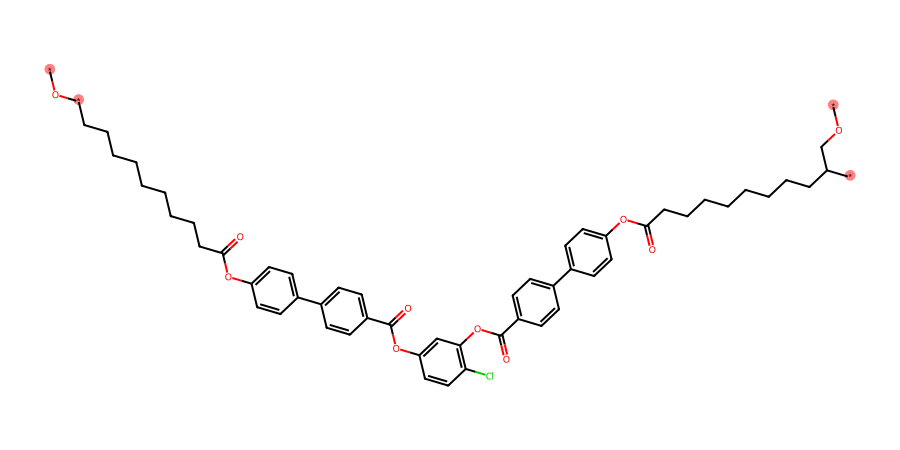

In [16]:
from rdkit.Chem import Draw

# Select the first flagged structure
example_index = connectivity_review.index[0]
example_mol = molecules.loc[example_index]

# Collect the indices of all dummy atoms
dummy_indices = [
    atom.GetIdx()
    for atom in example_mol.GetAtoms()
    if atom.GetAtomicNum() == 0
]

# Display the original identifier and full SMILES
print("Polymer ID:", train.loc[example_index, "id"])
print("SMILES:", train.loc[example_index, "SMILES"])

# Draw the represented structure and highlight its dummy atoms
display(
    Draw.MolToImage(
        example_mol,
        size=(900, 450),
        highlightAtoms=dummy_indices,
    )
)

| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `from rdkit.Chem import Draw` | Importiert das RDKit-Modul zum Zeichnen von Strukturen. | Imports the RDKit module for drawing structures. |
| `connectivity_review.index[0]` | Wählt den ursprünglichen Zeilenindex des ersten auffälligen Eintrags. | Selects the original row index of the first flagged entry. |
| `molecules.loc[example_index]` | Holt das zugehörige Molekülobjekt anhand dieses Index. | Retrieves the corresponding molecule object by its index. |
| `atom.GetIdx()` | Gibt den Index eines Atoms innerhalb dieses Moleküls zurück. | Returns an atom's index within this molecule. |
| `if atom.GetAtomicNum() == 0` | Nimmt nur Dummy-Atome in die Liste auf. | Includes only dummy atoms in the list. |
| `dummy_indices` | Liste der Atomindizes, die hervorgehoben werden sollen. | List of atom indices to highlight. |
| `train.loc[example_index, "SMILES"]` | Holt den vollständigen ursprünglichen SMILES-Text. | Retrieves the complete original SMILES string. |
| `Draw.MolToImage(...)` | Erstellt eine zweidimensionale Strukturzeichnung. | Creates a two-dimensional structure drawing. |
| `example_mol` | Das als erstes Argument übergebene Molekülobjekt. | The molecule object supplied as the first argument. |
| `size=(900, 450)` | Legt Bildbreite und Bildhöhe in Pixeln fest. | Sets the image width and height in pixels. |
| `highlightAtoms=dummy_indices` | Übergibt die Atomindizes für die Hervorhebung. | Supplies the atom indices to highlight. |

### Decision: unusual dummy-atom connectivity

Five structures contain a dummy atom with two directly bonded neighbours.
Visual inspection of the first case confirms this connectivity.

The intended representation remains unresolved. These entries are retained
and flagged for review. No automatic correction is applied.

In [17]:
# Generate canonical SMILES while preserving stereochemical information
def get_canonical_smiles(mol):
    if mol is None:
        return None

    return Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=True,
    )


canonical_smiles = molecules.apply(get_canonical_smiles)

# Identify all members of repeated canonical-SMILES groups
canonical_duplicate_mask = (
    canonical_smiles.notna()
    & canonical_smiles.duplicated(keep=False)
)

print(
    "Rows belonging to repeated canonical-SMILES groups:",
    canonical_duplicate_mask.sum(),
)

# Display the original entries and their canonical representation
canonical_review = train.loc[
    canonical_duplicate_mask, ["id", "SMILES"]
].copy()

canonical_review["canonical_smiles"] = canonical_smiles.loc[
    canonical_duplicate_mask
]

display(canonical_review)

Rows belonging to repeated canonical-SMILES groups: 0


,id,SMILES,canonical_smiles


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `get_canonical_smiles` | Eigene Funktion zur Erzeugung einer kanonischen SMILES-Schreibweise. | Custom function for generating canonical SMILES. |
| `mol` | Parameter für ein RDKit-Molekülobjekt. | Parameter representing an RDKit molecule object. |
| `Chem.MolToSmiles(...)` | Wandelt ein Molekülobjekt wieder in einen SMILES-Text um. | Converts a molecule object back into a SMILES string. |
| `canonical=True` | Fordert die kanonische Schreibweise an. | Requests canonical output. |
| `isomericSmiles=True` | Behält vorhandene Stereochemie- und Isotopeninformationen in der Ausgabe bei. | Preserves available stereochemical and isotope information in the output. |
| `molecules.apply(...)` | Wendet die Funktion auf jedes eingelesene Molekül an. | Applies the function to each parsed molecule. |
| `canonical_smiles` | Series mit den erzeugten kanonischen SMILES. | Series containing the generated canonical SMILES. |
| `.notna()` | Schließt fehlende Ergebnisse aus der Duplikatmarkierung aus. | Excludes missing results from duplicate flagging. |
| `.duplicated(keep=False)` | Markiert alle Mitglieder einer wiederholten Gruppe, einschließlich des ersten. | Flags every member of a repeated group, including the first. |
| `&` | Verknüpft die beiden Bedingungen mit UND. | Combines the two conditions with AND. |
| `canonical_duplicate_mask.sum()` | Zählt die betroffenen Zeilen, nicht die Anzahl der Gruppen. | Counts affected rows, not the number of groups. |
| `.copy()` | Erstellt eine separate Untersuchungstabelle. | Creates a separate review table. |

### Findings: canonical-SMILES duplicate check

- No repeated canonical isomeric SMILES were found among the
  7,973 training structures using RDKit 2026.09.1.
- All generated canonical representations were distinct.
- This check does not establish uniqueness under alternative
  polymer repeat-unit representations.
- No observations were removed.

## 10. Descriptive statistics of the target properties

We summarise the available values for each prediction target.

The summary includes:
- non-missing value count;
- mean and standard deviation;
- minimum and maximum;
- 25th percentile, median and 75th percentile.

Missing target values are excluded separately for each property.
No values are imputed or removed.
Units still require confirmation from the dataset documentation.

Important: The statistics for Tg use its 511 available values, while those for FFV use its 7,030 values. We do not require the rows to be completely filled in for this purpose.

## 10. Deskriptive Statistik der Zielgrößen

Wir fassen die verfügbaren Werte für jede Zielgröße zusammen.

Die Zusammenfassung umfasst:
- Anzahl der vorhandenen (nicht fehlenden) Werte;
- Mittelwert und Standardabweichung;
- Minimum und Maximum;
- 25.-Perzentil, Median und 75.-Perzentil.

Fehlende Werte der Zielgrößen werden für jede Eigenschaft separat ausgeschlossen.
Es werden keine Werte imputiert oder entfernt.
Die Maßeinheiten müssen noch anhand der Dokumentation des Datensatzes bestätigt werden.

Wichtig: Die Statistik für Tg verwendet dessen 511 vorhandene Werte, die für FFV dessen 7.030 Werte. Wir verlangen dafür keine vollständig ausgefüllten Zeilen.

In [18]:
# Summarise each target using its available values
target_statistics = train[target_columns].describe().T

display(target_statistics)

,count,mean,std,min,25%,50%,75%,max
Tg,511.0,96.452314,111.228279,-148.029738,13.674509,74.040183,161.147595,472.250000
FFV,7030.0,0.367212,0.029609,0.226992,0.349549,0.364264,0.380790,0.777097
Tc,737.0,0.256334,0.089538,0.046500,0.186000,0.236000,0.330500,0.524000
Density,613.0,0.985484,0.146189,0.748691,0.890243,0.948193,1.062096,1.840999
Rg,614.0,16.419787,4.608640,9.728355,12.540328,15.052194,20.411067,34.672906


## 11. Target distributions

We plot a separate histogram for each target property.

Each histogram uses the available values for that target.
The full observed range is retained, including extreme values.
Axes are separate because the properties have different scales.

We inspect concentration, asymmetry, multiple peaks and extreme values.
Units remain unconfirmed and are therefore not added to the axes.

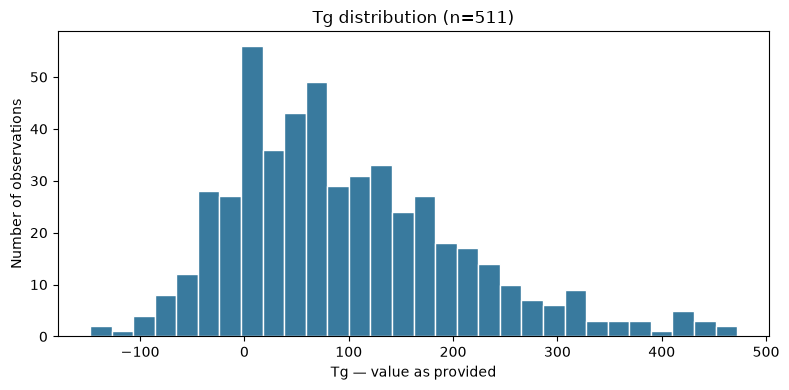

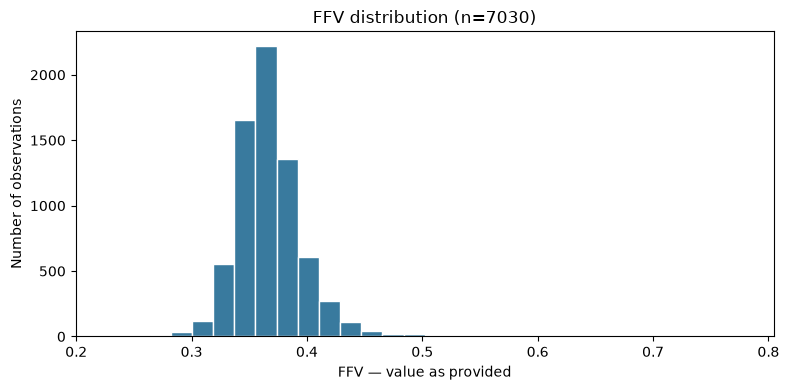

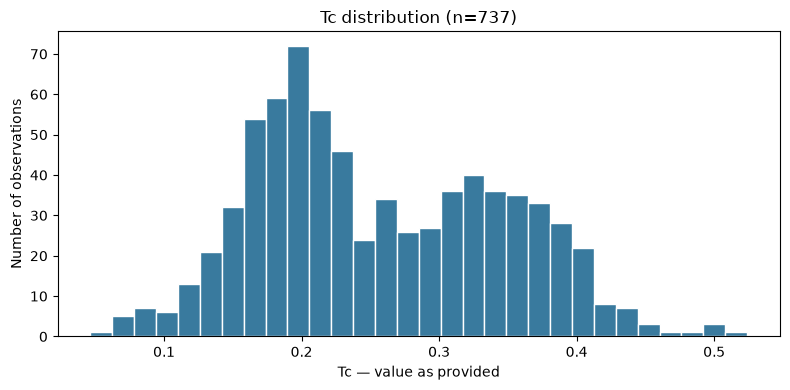

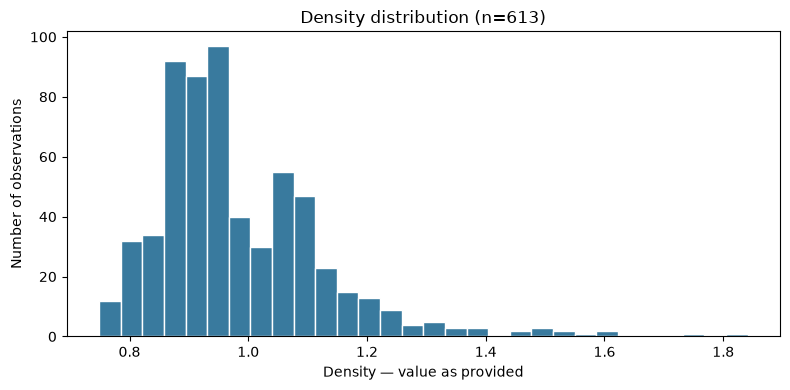

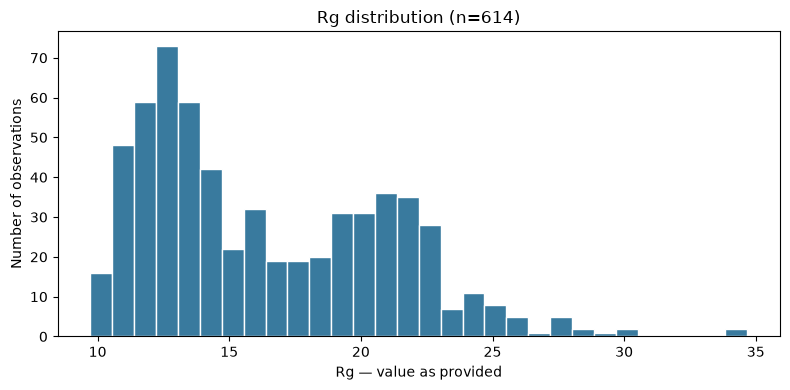

In [19]:
# Plot each target separately using all available values
for target in target_columns:
    values = train[target].dropna()

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.hist(
        values,
        bins=30,
        color="#397A9E",
        edgecolor="white",
    )

    ax.set_title(f"{target} distribution (n={len(values)})")
    ax.set_xlabel(f"{target} — value as provided")
    ax.set_ylabel("Number of observations")

    fig.tight_layout()
    plt.show()

| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `for target in target_columns:` | Durchläuft die fünf Zielspalten. | Iterates over the five target columns. |
| `target` | Variable für den aktuellen Spaltennamen. | Variable holding the current column name. |
| `train[target]` | Wählt die aktuelle Zielspalte als Series aus. | Selects the current target column as a Series. |
| `.dropna()` | Gibt die vorhandenen Werte zurück. Die ursprüngliche Tabelle bleibt unverändert. | Returns non-missing values without changing the original table. |
| `values` | Variable für die Werte der aktuellen Zielgröße. | Variable containing the current target's values. |
| `plt.subplots(...)` | Erstellt eine Figure und einen Zeichenbereich. | Creates a figure and an axes object. |
| `fig` | Das gesamte Diagrammobjekt. | The complete figure object. |
| `ax` | Der Zeichenbereich mit Achsen und Histogramm. | The plotting area containing axes and the histogram. |
| `figsize=(8, 4)` | Breite und Höhe der Figure in Zoll. | Figure width and height in inches. |
| `ax.hist(values, ...)` | Zeichnet das Histogramm der übergebenen Werte. | Draws a histogram of the supplied values. |
| `bins=30` | Teilt den Wertebereich in 30 gleich breite Intervalle. | Divides the value range into 30 equal-width intervals. |
| `color="#397A9E"` | Bestimmt die Balkenfarbe mit einem hexadezimalen Farbcode. | Sets the bar colour using a hexadecimal colour code. |
| `edgecolor="white"` | Zeichnet weiße Balkenränder. | Draws white bar edges. |
| `f"..."` | Formatierter String, der Ausdrücke in geschweiften Klammern einsetzt. | Formatted string that inserts expressions enclosed in braces. |
| `{target}` | Setzt den aktuellen Zielnamen in den Titel ein. | Inserts the current target name into the title. |
| `{len(values)}` | Setzt die Anzahl verwendeter Werte ein. | Inserts the number of observations used. |
| `ax.set_title(...)` | Setzt den Diagrammtitel. | Sets the chart title. |
| `ax.set_xlabel(...)` | Beschriftet die horizontale Achse. | Labels the horizontal axis. |
| `ax.set_ylabel(...)` | Beschriftet die vertikale Achse. | Labels the vertical axis. |
| `fig.tight_layout()` | Passt die Abstände innerhalb der Figure an. | Adjusts spacing within the figure. |
| `plt.show()` | Zeigt das Diagramm an. | Displays the chart. |

### Findings: initial target histograms

- FFV values are strongly concentrated around 0.36.
  Rare extreme values are difficult to see on the linear count scale.
- Tc shows a prominent peak around 0.20 and a broader secondary
  concentration around 0.32–0.37.
- Density is right-skewed, with relatively few high values.
- Rg shows possible multiple concentrations and a right-hand tail.
- Apparent peaks depend partly on histogram binning.
  They do not establish distinct polymer classes.
- Extreme values are retained pending further investigation.

In [20]:
# Select rows with available FFV values
ffv_review = train.loc[
    train["FFV"].notna(),
    ["id", "SMILES", "FFV"],
].copy()

# Inspect the upper and lower extremes
print("Ten highest FFV values:")
display(ffv_review.nlargest(10, "FFV"))

print("Ten lowest FFV values:")
display(ffv_review.nsmallest(10, "FFV"))

Ten highest FFV values:


,id,SMILES,FFV
6064,1645416728,*CCC1C[N+](C)(C)CC1*,0.777097
2966,806978622,*CC(*)O[N+](=O)[O-],0.774066
645,180321996,*CCCCCCCCCC[N+](*)(C)C,0.769315
2338,637669265,*CC(*)C(=O)NCCC[N+](C)(C)C,0.687057
2626,713393124,*CC(*)C(=O)N1CC[NH+](CC)CC1,0.650907
633,177272960,*c1ccc(*)[nH]1,0.563897
5385,1462748332,*c1ccc(-c2nc3ccc(-c4ccc5nc(*)c(-c6ccccc6)nc5c4...,0.532769
1374,370833911,*CCSSSS*,0.528203
3143,852184111,*c1cc(C)c(*)s1,0.516864
5032,1365848174,*c1ccc(-c2nc3cc4nc(-c5ccccc5)c(*)nc4cc3nc2-c2c...,0.513982


Ten lowest FFV values:


,id,SMILES,FFV
7705,2076949860,*CC(*)(CC(=O)O)C(=O)O,0.226992
4352,1173339618,*CC(*)C(N)=O,0.237637
5053,1370577687,*CC(*)C(=O)NCC(N)=O,0.245613
7536,2036966102,*C(*)O,0.245654
2198,595580163,*CC(*)(C)C(N)=O,0.256579
3036,822079361,*CC(*)C(=O)NCP(=O)(O)O,0.267393
4939,1337317565,*CC(*)(C)C(=O)O,0.271584
2159,584442637,*CC(OC)C(C(=O)O)C(*)C(=O)O,0.271790
4565,1231617285,*CC(*)NC=O,0.274937
4340,1169539258,*CC(*)(CC(=O)OC)C(=O)O,0.275583


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `train["FFV"].notna()` | Markiert Zeilen mit vorhandenem FFV-Wert. | Marks rows with an available FFV value. |
| `train.loc[..., ["id", "SMILES", "FFV"]]` | Wählt diese Zeilen und die drei angegebenen Spalten aus. | Selects these rows and the three specified columns. |
| `.copy()` | Erstellt eine separate Untersuchungstabelle. | Creates a separate review table. |
| `ffv_review` | Variable für die FFV-Untersuchungstabelle. | Variable containing the FFV review table. |
| `.nlargest(10, "FFV")` | Liefert die zehn Zeilen mit den höchsten FFV-Werten, absteigend sortiert. | Returns the ten rows with the highest FFV values, sorted in descending order. |
| `.nsmallest(10, "FFV")` | Liefert die zehn Zeilen mit den niedrigsten FFV-Werten, aufsteigend sortiert. | Returns the ten rows with the lowest FFV values, sorted in ascending order. |
| `10` | Argument für die gewünschte Zeilenanzahl; Parameter `n`. | Argument specifying the requested row count; parameter `n`. |
| `"FFV"` | Argument für die Spalte, nach der ausgewählt wird; Parameter `columns`. | Argument specifying the selection column; parameter `columns`. |

### Findings: FFV extreme values

- The three highest FFV values are approximately 0.769–0.777.
- Further high values occur around 0.687 and 0.651.
- There are noticeable gaps between some of the highest observations.
- The minimum FFV is approximately 0.227.
- The five highest SMILES entries contain positively charged nitrogen
  notation [N+]. This observation requires further investigation and
  does not establish a causal relationship.
- Extreme observations are retained. Their validity has not yet
  been established from source documentation.

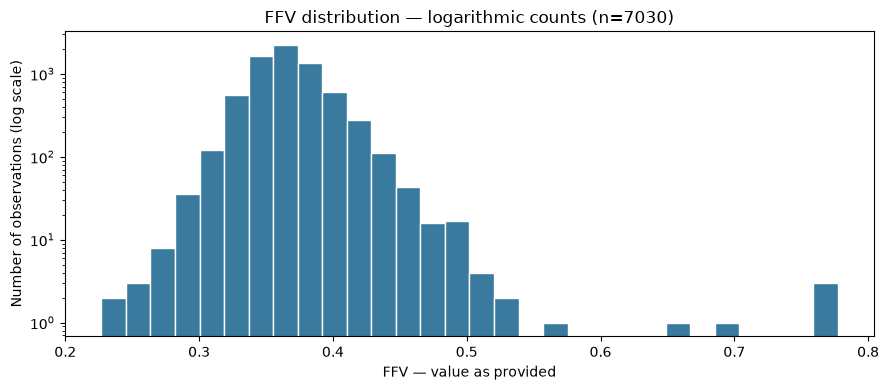

In [21]:
# Show rare FFV observations using a logarithmic count axis
ffv_values = train["FFV"].dropna()

fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(
    ffv_values,
    bins=30,
    log=True,
    color="#397A9E",
    edgecolor="white",
)

ax.set_title(f"FFV distribution — logarithmic counts (n={len(ffv_values)})")
ax.set_xlabel("FFV — value as provided")
ax.set_ylabel("Number of observations (log scale)")

fig.tight_layout()
plt.show()

### Findings: FFV histogram with logarithmic counts

- The logarithmic count axis makes sparsely populated intervals visible.
- Most FFV observations remain concentrated around 0.35–0.38.
- The upper tail contains a small number of widely separated values.
- The three highest observations around 0.77 fall into the same bin.
- The FFV values were not transformed, removed or corrected.
- This plot alone does not establish whether extreme values are valid.

Polymer ID: 1645416728
FFV: 0.77709707
SMILES: *CCC1C[N+](C)(C)CC1*


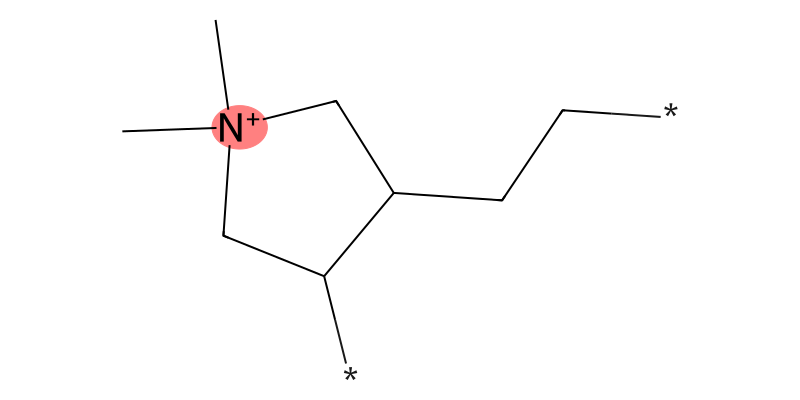

In [22]:
# Select the row with the highest available FFV value
highest_ffv_index = ffv_review["FFV"].idxmax()
highest_ffv_mol = molecules.loc[highest_ffv_index]

# Identify atoms with a non-zero formal charge
charged_atom_indices = [
    atom.GetIdx()
    for atom in highest_ffv_mol.GetAtoms()
    if atom.GetFormalCharge() != 0
]

print("Polymer ID:", train.loc[highest_ffv_index, "id"])
print("FFV:", train.loc[highest_ffv_index, "FFV"])
print("SMILES:", train.loc[highest_ffv_index, "SMILES"])

display(
    Draw.MolToImage(
        highest_ffv_mol,
        size=(800, 400),
        highlightAtoms=charged_atom_indices,
    )
)

### Visual inspection of the highest-FFV entry

- Entry ID 1645416728 has the highest observed FFV: 0.77709707.
- Its represented structure contains a nitrogen atom with formal charge +1.
- Two dummy atoms are present.
- The highlighted atom indicates formal charge, not an attachment point.
- This observation does not explain or validate the high FFV value.
- The entry is retained and flagged for further review.

### Formal charges in the ten highest-FFV entries

We inspect the number of formally charged atoms and the sum of
formal charges in each represented structure.

A zero total formal charge does not imply that every atom is uncharged.
This analysis describes the stored molecular graphs and does not
establish why their FFV values are high.

No structures or target values are modified.

In [23]:
# Count atoms with a non-zero formal charge
def count_charged_atoms(mol):
    if mol is None:
        return None

    return sum(
        atom.GetFormalCharge() != 0
        for atom in mol.GetAtoms()
    )


# Sum the formal charges of all atoms
def sum_formal_charges(mol):
    if mol is None:
        return None

    return sum(
        atom.GetFormalCharge()
        for atom in mol.GetAtoms()
    )


# Select the ten highest-FFV entries and their molecules
top_ffv_charge_review = ffv_review.nlargest(10, "FFV").copy()
top_ffv_molecules = molecules.loc[top_ffv_charge_review.index]

# Add charge information, aligned by the original row index
top_ffv_charge_review["charged_atom_count"] = (
    top_ffv_molecules.apply(count_charged_atoms)
)

top_ffv_charge_review["total_formal_charge"] = (
    top_ffv_molecules.apply(sum_formal_charges)
)

display(
    top_ffv_charge_review[
        ["id", "FFV", "charged_atom_count", "total_formal_charge"]
    ]
)

,id,FFV,charged_atom_count,total_formal_charge
6064,1645416728,0.777097,1,1
2966,806978622,0.774066,2,0
645,180321996,0.769315,1,1
2338,637669265,0.687057,1,1
2626,713393124,0.650907,1,1
633,177272960,0.563897,0,0
5385,1462748332,0.532769,0,0
1374,370833911,0.528203,0,0
3143,852184111,0.516864,0,0
5032,1365848174,0.513982,0,0


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `def` | Definiert eine eigene Funktion. | Defines a custom function. |
| `mol` | Parameter für ein einzelnes Molekülobjekt. | Parameter representing one molecule object. |
| `if mol is None:` | Prüft, ob das Molekülobjekt fehlt. | Checks whether the molecule object is missing. |
| `return None` | Beendet die Funktion ohne berechneten Wert. | Exits the function without a calculated value. |
| `mol.GetAtoms()` | Liefert die Atome zum Durchlaufen. | Provides the atoms for iteration. |
| `atom.GetFormalCharge()` | Gibt die formale Ladung des aktuellen Atoms zurück. | Returns the current atom's formal charge. |
| `!= 0` | Prüft, ob die Ladung ungleich null ist. | Checks whether the charge is non-zero. |
| `sum(...)` | Addiert Ladungen oder zählt wahre Bedingungen, abhängig vom übergebenen Ausdruck. | Adds charges or counts true conditions, depending on the supplied expression. |
| `.nlargest(10, "FFV")` | Wählt die zehn höchsten FFV-Einträge aus. | Selects the ten highest-FFV entries. |
| `.copy()` | Erstellt eine separate Untersuchungstabelle. | Creates a separate review table. |
| `top_ffv_charge_review.index` | Enthält die ursprünglichen Zeilenindizes der ausgewählten Einträge. | Contains the original row indices of the selected entries. |
| `molecules.loc[...]` | Wählt die zugehörigen Molekülobjekte aus. | Selects the corresponding molecule objects. |
| `.apply(count_charged_atoms)` | Zählt geladene Atome für jedes ausgewählte Molekül. | Counts charged atoms for each selected molecule. |
| `.apply(sum_formal_charges)` | Berechnet die Ladungssumme für jedes ausgewählte Molekül. | Calculates the formal-charge sum for each selected molecule. |

### Findings: formal charges in the highest-FFV entries

- All five highest-FFV entries contain formally charged atoms.
- Four have a total formal charge of +1.
- One entry, ID 806978622, contains two charged atoms but has
  a total formal charge of zero.
- Entries ranked 6–10 contain no formally charged atoms.
- These findings describe the selected extremes only.
  They do not establish causation or invalidate the target values.
- No observations were removed.

In [24]:
# Count formally charged atoms in all parsed structures. (Zähle formal geladene Atome in allen analysierten Strukturen)
charged_atom_counts = molecules.apply(count_charged_atoms)

# Create a separate table for the FFV group comparison. (Erstelle eine separate Tabelle für den FFV-Gruppenvergleich.)
ffv_charge_comparison = ffv_review.copy()

ffv_charge_comparison["charged_atom_count"] = (
    charged_atom_counts.loc[ffv_charge_comparison.index]
)

ffv_charge_comparison["has_charged_atoms"] = (
    ffv_charge_comparison["charged_atom_count"].gt(0)
)

# Summarise FFV separately for both groups
ffv_charge_summary = (
    ffv_charge_comparison
    .groupby("has_charged_atoms")["FFV"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(ffv_charge_summary)

,count,mean,median,min,max
has_charged_atoms,,,,,
False,6841,0.366896,0.364270,0.226992,0.563897
True,189,0.378636,0.363822,0.333269,0.777097


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `.apply(count_charged_atoms)` | Wendet unsere vorhandene Zählfunktion auf jedes Molekül an. | Applies our existing counting function to each molecule. |
| `.loc[ffv_charge_comparison.index]` | Wählt die Anzahlen für die passenden FFV-Zeilen aus. | Selects counts for the corresponding FFV rows. |
| `.gt(0)` | Prüft, ob die Anzahl größer als null ist. | Checks whether the count is greater than zero. |
| `"has_charged_atoms"` | Neue Spalte: `True` bei mindestens einem geladenen Atom, sonst `False`. | New column: `True` for at least one charged atom, otherwise `False`. |
| `.groupby("has_charged_atoms")` | Gruppiert die Zeilen nach dieser Kennzeichnung. | Groups rows by this indicator. |
| `["FFV"]` | Wählt die zu untersuchenden Werte innerhalb der Gruppen aus. | Selects the values to examine within each group. |
| `.agg([...])` | Berechnet mehrere angegebene Statistiken je Gruppe. | Calculates several specified statistics for each group. |
| `"count"` | Anzahl vorhandener FFV-Werte je Gruppe. | Number of available FFV values per group. |
| `"mean"` / `"median"` | Mittelwert und Median je Gruppe. | Mean and median per group. |
| `"min"` / `"max"` | Kleinster und größter Wert je Gruppe. | Minimum and maximum value per group. |

### Findings: FFV comparison by presence of formally charged atoms

- Of the 7,030 FFV-labelled structures, 189 (approximately 2.69%)
  contain at least one formally charged atom.
- Their mean FFV is higher: 0.378636 versus 0.366896.
- The medians are nearly identical: 0.363822 versus 0.364270.
- The difference between means is consistent with the influence
  of the high upper-tail values identified earlier.
- The groups differ substantially in size.
- This descriptive comparison does not establish a causal effect
  or justify removing charged structures.
- All observations are retained.

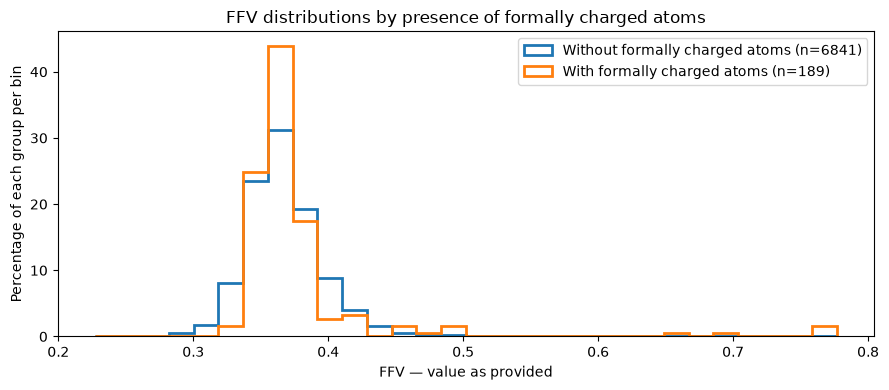

In [25]:
# Use identical bin boundaries for both groups
bin_edges = np.linspace(
    ffv_charge_comparison["FFV"].min(),
    ffv_charge_comparison["FFV"].max(),
    31,
)

fig, ax = plt.subplots(figsize=(9, 4))

for has_charge, group in ffv_charge_comparison.groupby("has_charged_atoms"):
    values = group["FFV"]

    # Each group's observations sum to 100 percent
    weights = np.full(len(values), 100 / len(values))

    label = (
        "With formally charged atoms"
        if has_charge
        else "Without formally charged atoms"
    )

    ax.hist(
        values,
        bins=bin_edges,
        weights=weights,
        histtype="step",
        linewidth=2,
        label=f"{label} (n={len(values)})",
    )

ax.set_title("FFV distributions by presence of formally charged atoms")
ax.set_xlabel("FFV — value as provided")
ax.set_ylabel("Percentage of each group per bin")
ax.legend()

fig.tight_layout()
plt.show()

| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `np.linspace(minimum, maximum, 31)` | Erstellt 31 gleichmäßig verteilte Grenzen für 30 Intervalle. | Creates 31 equally spaced boundaries for 30 bins. |
| `for has_charge, group in ...` | Liefert je Durchlauf den Gruppenschlüssel und die zugehörige Tabelle. | Provides the group key and its table in each iteration. |
| `has_charge` | Gruppenschlüssel: `True` oder `False`. | Group key: `True` or `False`. |
| `group` | Tabelle der aktuellen Gruppe. | Table containing the current group. |
| `np.full(len(values), 100 / len(values))` | Erstellt für jede Beobachtung dasselbe Prozentgewicht. | Creates the same percentage weight for every observation. |
| `weights=weights` | Addiert im Histogramm diese Gewichte statt bloßer Anzahlen. | Sums these weights instead of raw counts in the histogram. |
| `histtype="step"` | Zeichnet die Histogramme als Umrisslinien, damit beide sichtbar bleiben. | Draws histogram outlines so both remain visible. |
| `linewidth=2` | Legt die Linienstärke fest. | Sets the line width. |
| `label=...` | Beschriftung der jeweiligen Gruppe für die Legende. | Group label used in the legend. |
| `ax.legend()` | Zeigt die Legende an. | Displays the legend. |

## 12. Target quantiles and tail inspection

We calculate additional quantiles for each target to inspect its tails.

The 1st and 99th percentiles help distinguish the central distribution
from sparsely populated extremes. They are descriptive markers,
not automatic thresholds for removing observations.

Missing values are excluded separately for each target.
No observations are modified or removed.

In [26]:
# Inspect the centre and tails of each target distribution
quantile_levels = [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1]

target_quantiles = (
    train[target_columns]
    .quantile(quantile_levels)
    .T
)

display(target_quantiles)

,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
Tg,-148.029738,-90.165068,-49.041020,13.674509,74.040183,161.147595,311.948697,423.228584,472.250000
FFV,0.226992,0.306384,0.327622,0.349549,0.364264,0.380790,0.416925,0.451024,0.777097
Tc,0.046500,0.084360,0.131700,0.186000,0.236000,0.330500,0.403350,0.450243,0.524000
Density,0.748691,0.772621,0.806181,0.890243,0.948193,1.062096,1.234910,1.515912,1.840999
Rg,9.728355,10.064432,10.870906,12.540328,15.052194,20.411067,24.349463,28.234264,34.672906


### Findings: target quantiles

- For FFV, the 99th percentile is approximately 0.451,
  while the maximum is approximately 0.777.
- This supports the earlier observation of a sparse, extended upper tail.
- Density and Rg also have maxima above their 99th percentiles.
- Quantiles describe relative positions within each target distribution.
  They do not establish physical plausibility.
- The 1st and 99th percentiles are not used as deletion thresholds.
- All observations are retained.

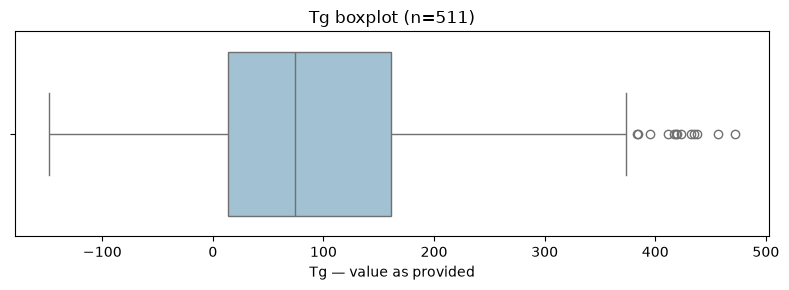

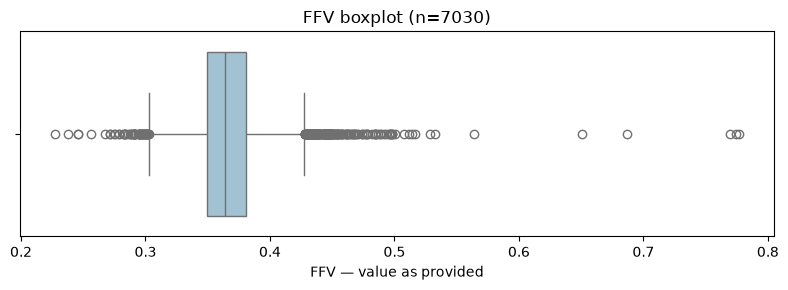

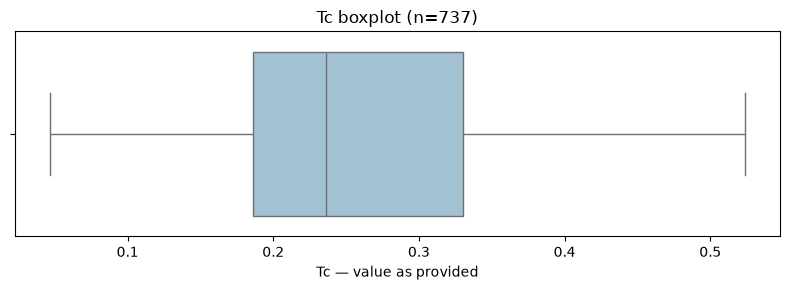

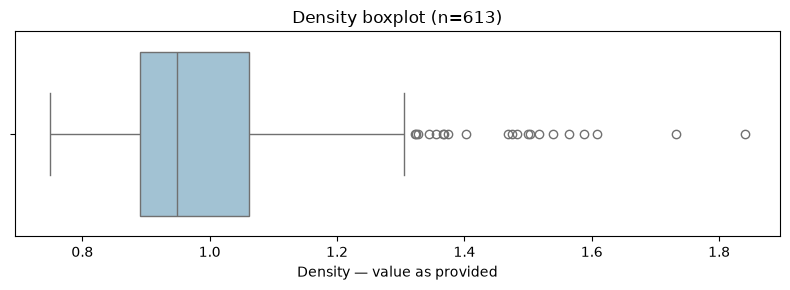

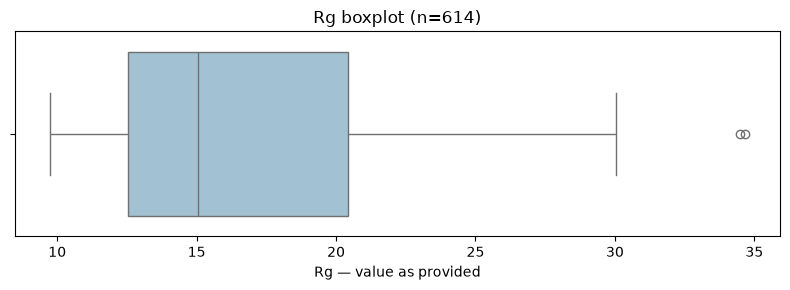

In [27]:
# Display each target using the standard 1.5-IQR boxplot rule
for target in target_columns:
    values = train[target].dropna()

    fig, ax = plt.subplots(figsize=(8, 3))

    sns.boxplot(
        x=values,
        whis=1.5,
        color="#9AC4DB",
        ax=ax,
    )

    ax.set_title(f"{target} boxplot (n={len(values)})")
    ax.set_xlabel(f"{target} — value as provided")

    fig.tight_layout()
    plt.show()

### Findings: target boxplots

- The 1.5-IQR rule flags upper-tail observations for Tg, Density and Rg.
- FFV has flagged observations in both tails.
- Tc has no observations outside the boxplot fences.
- The rule identifies statistical extremes, not confirmed data errors.
- Overlapping plot markers do not reliably show the number of
  flagged observations.
- All observations are retained.

## 13. IQR-based target review

We calculate the lower and upper fences using the 1.5 × IQR rule
and count the observations outside these fences for each target.

These are statistical review thresholds, not physical validity limits.
Missing values are excluded separately for each target.
No observations are modified or removed.

In [28]:
# Collect IQR-based review statistics for each target
iqr_rows = []

for target in target_columns:
    values = train[target].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    below_count = values.lt(lower_fence).sum()
    above_count = values.gt(upper_fence).sum()
    flagged_count = below_count + above_count

    iqr_rows.append({
        "target": target,
        "available_count": len(values),
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "below_count": below_count,
        "above_count": above_count,
        "flagged_count": flagged_count,
        "flagged_percent": flagged_count / len(values) * 100,
    })

iqr_summary = pd.DataFrame(iqr_rows).set_index("target")

display(iqr_summary.round(4))

,available_count,lower_fence,upper_fence,below_count,above_count,flagged_count,flagged_percent
target,,,,,,,
Tg,511,-207.5351,382.3572,0,13,13,2.5440
FFV,7030,0.3027,0.4277,57,212,269,3.8265
Tc,737,-0.0308,0.5472,0,0,0,0.0000
Density,613,0.6325,1.3199,0,21,21,3.4258
Rg,614,0.7342,32.2172,0,2,2,0.3257


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `iqr_rows = []` | Erstellt eine leere Liste für die Ergebnisse. | Creates an empty list for the results. |
| `.quantile(0.25)` | Berechnet das erste Quartil. | Calculates the first quartile. |
| `.quantile(0.75)` | Berechnet das dritte Quartil. | Calculates the third quartile. |
| `iqr = q3 - q1` | Berechnet den Interquartilsabstand. | Calculates the interquartile range. |
| `lower_fence` / `upper_fence` | Berechnete statistische Untersuchungsgrenzen. | Calculated statistical review thresholds. |
| `.lt(lower_fence)` | Prüft auf Werte strikt unterhalb der unteren Grenze. | Checks for values strictly below the lower threshold. |
| `.gt(upper_fence)` | Prüft auf Werte strikt oberhalb der oberen Grenze. | Checks for values strictly above the upper threshold. |
| `flagged_count` | Summe der markierten Werte beider Seiten. | Total number of flagged values in both tails. |
| `.append({...})` | Fügt ein Dictionary mit den Ergebnissen einer Zielgröße zur Liste hinzu. | Appends a dictionary containing one target's results to the list. |
| `.set_index("target")` | Verwendet die Zielnamen als Zeilenindex. | Uses target names as the row index. |
| `.round(4)` | Rundet die angezeigte Ergebniskopie auf vier Nachkommastellen. | Rounds the displayed result copy to four decimal places. |

### Findings: IQR-based target review

The 1.5 × IQR rule was applied separately to the non-missing
values of each target.

| Target | Available values | Below lower fence | Above upper fence | Total flagged | Flagged (%) |
|---|---:|---:|---:|---:|---:|
| Tg | 511 | 0 | 13 | 13 | 2.54 |
| FFV | 7,030 | 57 | 212 | 269 | 3.83 |
| Tc | 737 | 0 | 0 | 0 | 0.00 |
| Density | 613 | 0 | 21 | 21 | 3.43 |
| Rg | 614 | 0 | 2 | 2 | 0.33 |

FFV has the highest proportion of flagged values.
For Tg, Density, and Rg, all flagged values are above
the upper fence. No Tc values fall outside the IQR fences.

These fences are statistical review thresholds, not physical
validity limits. Flagged values are not automatically errors,
and values within the fences are not automatically valid.

All observations are retained at this stage.
Percentages are calculated using the available values
of each target.

## 14. Relationships between target properties

We examine pairwise relationships between the target properties
using Spearman correlation.

Each correlation is interpreted alongside the number of jointly
available observations. Different target pairs may use different
subsets of polymers.

Correlation does not establish causation.

In [29]:
# Select the target columns
target_data = train[target_columns]

# Count jointly available observations for each target pair
target_available = target_data.notna().astype("int64")
pair_counts = target_available.T.dot(target_available)

# Calculate pairwise Spearman correlations
spearman_corr = target_data.corr(method="spearman")

# Display counts and correlations
print("Jointly available observations:")
display(pair_counts)

print("Spearman correlation:")
display(spearman_corr.round(3))

Jointly available observations:


,Tg,FFV,Tc,Density,Rg
Tg,511,1,32,24,24
FFV,1,7030,300,270,270
Tc,32,300,737,531,535
Density,24,270,531,613,610
Rg,24,270,535,610,614


Spearman correlation:


,Tg,FFV,Tc,Density,Rg
Tg,1.000,NaN,-0.218,0.418,0.099
FFV,NaN,1.000,0.227,-0.502,-0.011
Tc,-0.218,0.227,1.000,-0.454,0.505
Density,0.418,-0.502,-0.454,1.000,0.163
Rg,0.099,-0.011,0.505,0.163,1.000


### Findings: pairwise target correlations

The strongest observed Spearman correlations are:

- FFV–Density: −0.502, based on 270 paired observations.
- Tc–Rg: +0.505, based on 535 paired observations.
- Tc–Density: −0.454, based on 531 paired observations.

FFV–Rg shows almost no monotonic association
(−0.011; 270 paired observations).

Correlations involving Tg require particular caution because
only 24–32 paired observations are available for the
calculable relationships. Tg–FFV cannot be calculated
because only one paired observation is available.

Each correlation describes the subset where both targets
are observed. Different target pairs may use different subsets.

These exploratory associations do not establish causation.
Scatter plots will be used to inspect the patterns.

### 14.1 Scatter plot: FFV and Density

We visualize the relationship between FFV and Density using
observations where both target values are available.

Each point represents one training row.
The scatter plot helps inspect the overall pattern,
possible groups, and unusual observations.

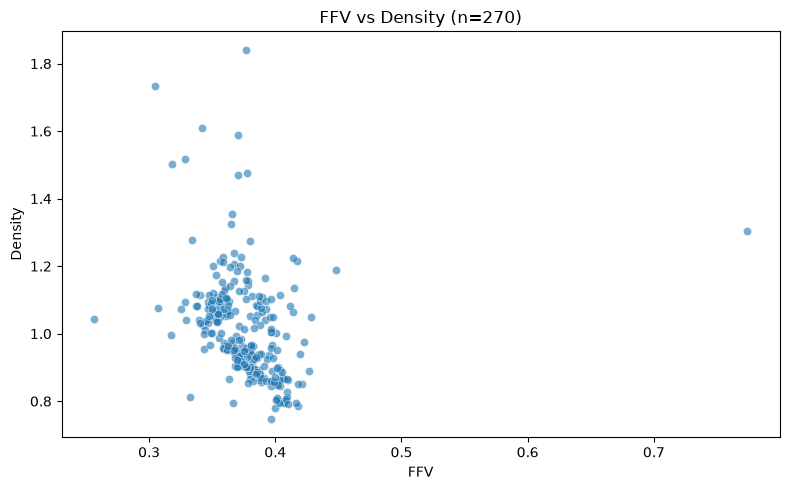

In [30]:
# Select paired observations without changing the training dataset
ffv_density_pairs = train[["FFV", "Density"]].dropna()

# Create the figure and axes
fig, ax = plt.subplots(figsize=(8, 5))

# Plot one point for each paired observation
sns.scatterplot(
    data=ffv_density_pairs,
    x="FFV",
    y="Density",
    alpha=0.6,
    s=35,
    ax=ax,
)

# Add a title and axis labels
ax.set_title(
    f"FFV vs Density (n={len(ffv_density_pairs)})"
)
ax.set_xlabel("FFV")
ax.set_ylabel("Density")

# Adjust spacing and display the figure
fig.tight_layout()
plt.show()

#### Findings: FFV and Density

The scatter plot shows a downward tendency in the main
point cloud, consistent with the Spearman correlation
of −0.502 across 270 paired observations.

Most paired observations are concentrated approximately
between FFV 0.33–0.42 and Density 0.8–1.2.

Considerable scatter remains: similar FFV values can occur
with different Density values.

Several observations lie away from the main point cloud,
including one at approximately FFV 0.77 and Density 1.30.
These observations are retained.

The findings describe the subset with both targets available
and do not establish causation.

### 14.2 Scatter plot: Tc and Rg

We visualize the relationship between Tc and Rg using
observations where both target values are available.

Each point represents one training row.
We inspect the positive association suggested by the
Spearman correlation of +0.505 across 535 paired observations.

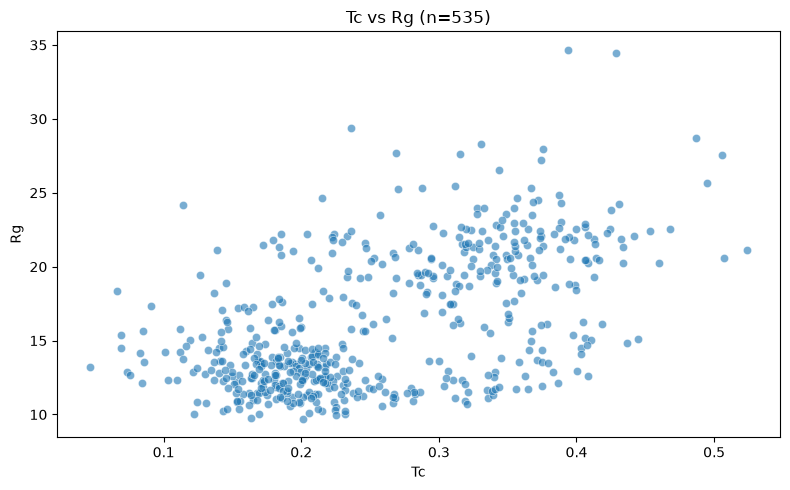

In [31]:
# Select rows where both targets are available
tc_rg_pairs = train[["Tc", "Rg"]].dropna()

# Create the figure and axes
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the paired observations
sns.scatterplot(
    data=tc_rg_pairs,
    x="Tc",
    y="Rg",
    alpha=0.6,
    s=35,
    ax=ax,
)

# Add a title and axis labels
ax.set_title(f"Tc vs Rg (n={len(tc_rg_pairs)})")
ax.set_xlabel("Tc")
ax.set_ylabel("Rg")

# Adjust spacing and display the figure
fig.tight_layout()
plt.show()

#### Findings: Tc and Rg

The scatter plot shows an overall positive association,
consistent with the Spearman correlation of +0.505
across 535 paired observations.

Two visually dense regions occur approximately around:
- Tc 0.14–0.23 and Rg 10–15.
- Tc 0.30–0.42 and Rg 18–24.

Considerable scatter remains, including low Rg values
at higher Tc values. A single straight-line description
would therefore capture only part of the visible pattern.

The dense regions do not establish distinct polymer classes
or data sources. Two observations have Rg values around 34–35.
All observations are retained.

These findings describe the subset with both targets available
and do not establish causation.

### 14.3 Scatter plot: Tc and Density

We visualize the relationship between Tc and Density using
observations where both target values are available.

Each point represents one training row.
We inspect the negative association suggested by the
Spearman correlation of −0.454 across 531 paired observations.

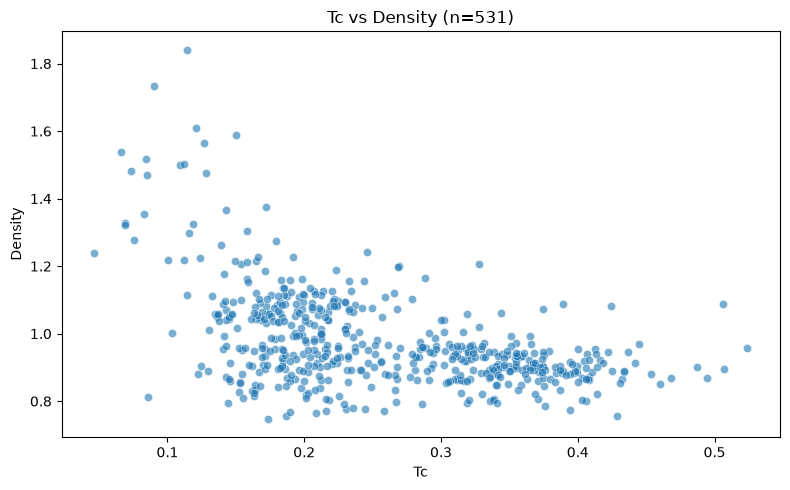

In [32]:
# Select rows where both targets are available
tc_density_pairs = train[["Tc", "Density"]].dropna()

# Create the figure and axes
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the paired observations
sns.scatterplot(
    data=tc_density_pairs,
    x="Tc",
    y="Density",
    alpha=0.6,
    s=35,
    ax=ax,
)

# Add a title and axis labels
ax.set_title(f"Tc vs Density (n={len(tc_density_pairs)})")
ax.set_xlabel("Tc")
ax.set_ylabel("Density")

# Adjust spacing and display the figure
fig.tight_layout()
plt.show()

#### Findings: Tc and Density

The scatter plot shows an overall negative association,
consistent with the Spearman correlation of −0.454
across 531 paired observations.

Many observations around Tc 0.15–0.23 have Density values
approximately between 0.8 and 1.15.

Around Tc 0.30–0.42, many Density values are concentrated
approximately between 0.85 and 0.97.

Several high Density values occur at relatively low Tc.
Considerable scatter remains, so Tc alone does not
uniquely determine Density.

All observations are retained. These findings describe
the subset with both targets available and do not
establish causation.

### Pairwise correlations between target properties

Investigate linear relationships between Tg, FFV, Tc, Density,
and Rg using Pearson correlation.

Each correlation uses only samples with both target values available.
Report the number of jointly labeled samples alongside the correlations
because label availability differs substantially between target pairs.

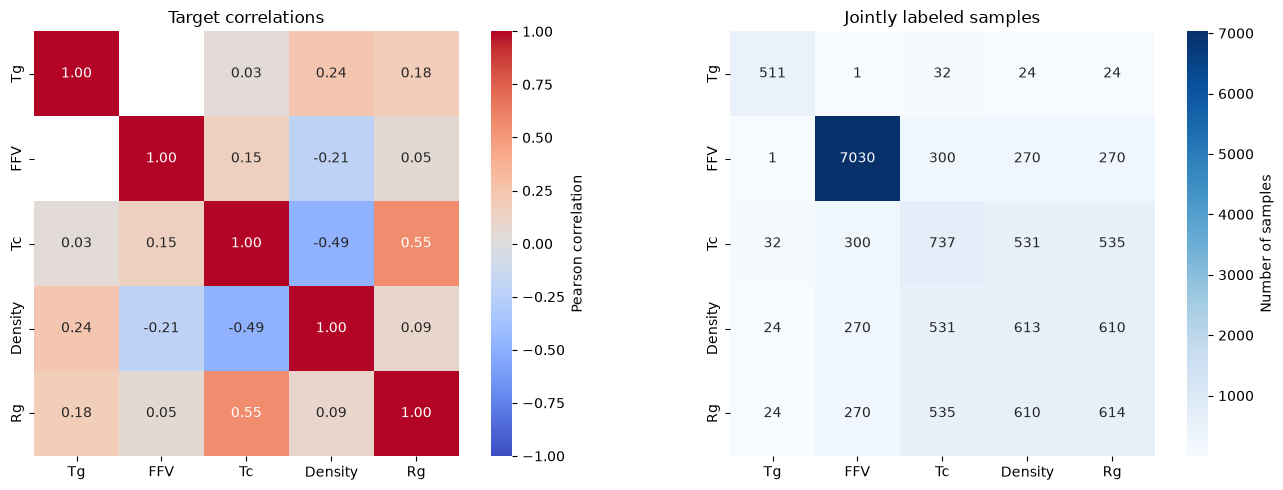

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the five target properties.
target_columns = ["Tg", "FFV", "Tc", "Density", "Rg"]
target_data = train[target_columns]

# Count samples with both target values available.
target_available = target_data.notna().astype("int64")
target_pair_counts = target_available.T.dot(target_available)

# Calculate pairwise Pearson correlations.
target_correlations = target_data.corr(
    method="pearson",
    min_periods=3,
)

# Create two plots beside each other.
fig, axes = plt.subplots(figsize=(14, 5), ncols=2)

# Plot the correlation coefficients.
sns.heatmap(
    target_correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0],
    cbar_kws={"label": "Pearson correlation"},
)

axes[0].set_title("Target correlations")

# Plot the number of jointly labeled samples.
sns.heatmap(
    target_pair_counts,
    annot=True,
    fmt="d",
    cmap="Blues",
    square=True,
    ax=axes[1],
    cbar_kws={"label": "Number of samples"},
)

axes[1].set_title("Jointly labeled samples")

fig.tight_layout()
plt.show()

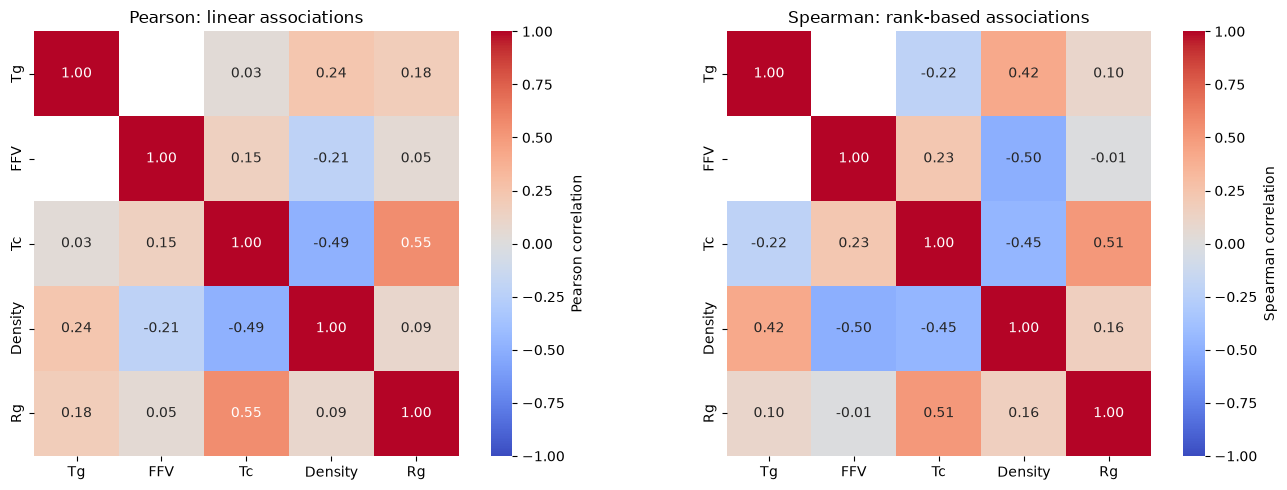

In [112]:
# Calculate rank-based correlations.
target_spearman_correlations = target_data.corr(
    method="spearman",
    min_periods=3,
)

# Create two plots beside each other.
fig, axes = plt.subplots(ncols=2, figsize=(14, 5))

# Plot Pearson correlations.
sns.heatmap(
    target_correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0],
    cbar_kws={"label": "Pearson correlation"},
)

axes[0].set_title("Pearson: linear associations")

# Plot Spearman correlations.
sns.heatmap(
    target_spearman_correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1],
    cbar_kws={"label": "Spearman correlation"},
)

axes[1].set_title("Spearman: rank-based associations")

fig.tight_layout()
plt.show()

### Findings — Pearson versus Spearman correlations

- Tc–Rg showed positive associations with both methods
  (Pearson ≈ 0.55, Spearman ≈ 0.51; n = 535).
- Tc–Density showed negative associations with both methods
  (Pearson ≈ −0.49, Spearman ≈ −0.45; n = 531).
- FFV–Density showed a stronger rank-based association
  (Spearman ≈ −0.50) than linear association
  (Pearson ≈ −0.21; n = 270).
- Scatter plots are needed to investigate the shape of these
  relationships and the possible influence of unusual observations.
- Tg results remain exploratory because jointly labeled
  sample counts are small.
- Correlations describe associations and do not establish causality.

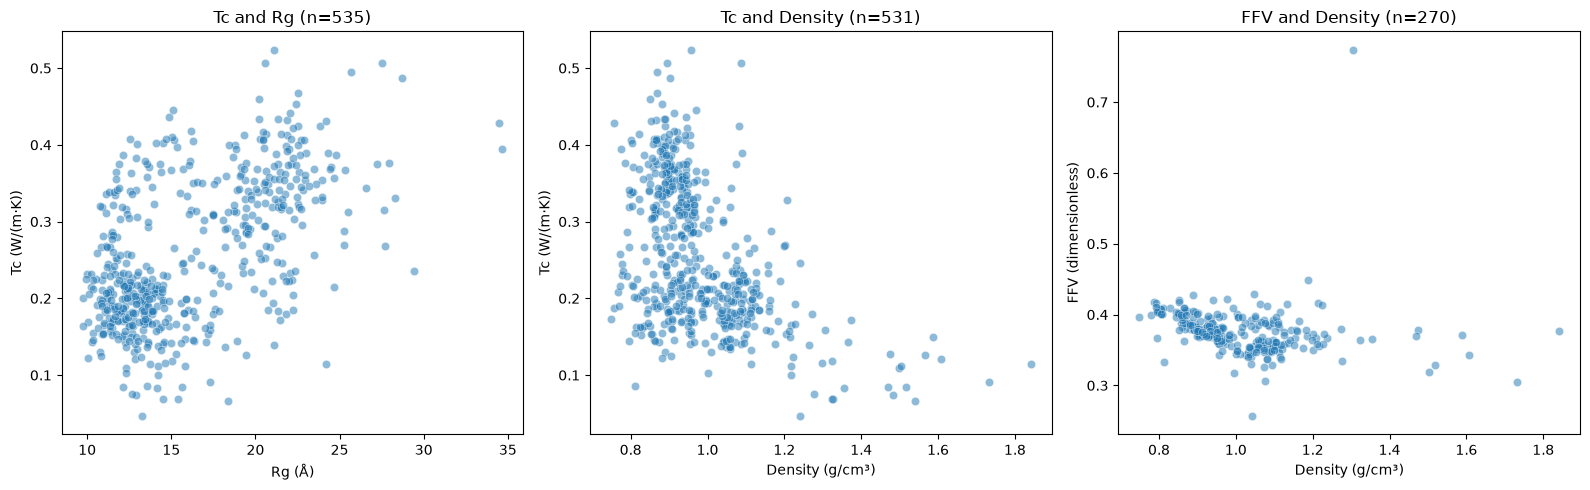

In [113]:
# Select jointly labeled samples for each target pair.
tc_rg_data = target_data[["Rg", "Tc"]].dropna()
tc_density_data = target_data[["Density", "Tc"]].dropna()
ffv_density_data = target_data[["Density", "FFV"]].dropna()

# Create three scatter plots.
fig, axes = plt.subplots(ncols=3, figsize=(16, 5))

sns.scatterplot(
    data=tc_rg_data,
    x="Rg",
    y="Tc",
    alpha=0.5,
    ax=axes[0],
)
axes[0].set_title(f"Tc and Rg (n={len(tc_rg_data)})")
axes[0].set_xlabel("Rg (Å)")
axes[0].set_ylabel("Tc (W/(m·K))")

sns.scatterplot(
    data=tc_density_data,
    x="Density",
    y="Tc",
    alpha=0.5,
    ax=axes[1],
)
axes[1].set_title(f"Tc and Density (n={len(tc_density_data)})")
axes[1].set_xlabel("Density (g/cm³)")
axes[1].set_ylabel("Tc (W/(m·K))")

sns.scatterplot(
    data=ffv_density_data,
    x="Density",
    y="FFV",
    alpha=0.5,
    ax=axes[2],
)
axes[2].set_title(f"FFV and Density (n={len(ffv_density_data)})")
axes[2].set_xlabel("Density (g/cm³)")
axes[2].set_ylabel("FFV (dimensionless)")

fig.tight_layout()
plt.show()

### Findings — Target scatter plots

- Tc–Rg shows an overall positive association, with substantial
  scatter and visible groups of observations.
- Tc–Density shows an overall negative association. The relationship
  is not adequately described by a single deterministic trend.
- Most jointly labeled FFV–Density samples occupy a relatively
  narrow FFV range, with a generally decreasing pattern.
- One observation has an unusually high FFV of approximately 0.77
  at a density of approximately 1.3 g/cm³.
- This observation may influence Pearson correlation and contribute
  to its difference from Spearman correlation. Its influence requires
  a separate sensitivity check.
- Visible groups require structural investigation before assigning
  them a chemical explanation.
- No observations were removed based on these plots.

In [114]:
# Identify the five highest FFV values among jointly labeled samples.
highest_joint_ffv = ffv_density_data.nlargest(
    n=5,
    columns="FFV",
)

# Retrieve identifiers, structures, and both target values.
highest_joint_ffv_review = train.loc[
    highest_joint_ffv.index,
    ["id", "SMILES", "FFV", "Density"],
].copy()

display(highest_joint_ffv_review)

,id,SMILES,FFV,Density
2966,806978622,*CC(*)O[N+](=O)[O-],0.774066,1.305302
4141,1121030015,*CCS*,0.448504,1.187990
6173,1674948032,*Sc1c(C)cc(*)cc1C,0.428441,1.048021
289,82633177,*C1Cc2ccccc2C1*,0.426989,0.889252
3069,834012774,*CC(*)c1cccc(N(c2ccc(C)cc2)c2ccc(C)cc2)c1,0.422623,0.975794


In [115]:
# Identify the sample with the highest jointly available FFV.
highest_ffv_index = ffv_density_data["FFV"].idxmax()

# Create a comparison dataset without this single sample.
ffv_density_without_highest = ffv_density_data.drop(
    index=highest_ffv_index,
)

# Compare correlations with and without the selected sample.
correlation_sensitivity = pd.DataFrame({
    "dataset": [
        "All jointly labeled samples",
        "Without highest-FFV sample",
    ],
    "sample_count": [
        len(ffv_density_data),
        len(ffv_density_without_highest),
    ],
    "pearson": [
        ffv_density_data["Density"].corr(
            ffv_density_data["FFV"], method="pearson"
        ),
        ffv_density_without_highest["Density"].corr(
            ffv_density_without_highest["FFV"], method="pearson"
        ),
    ],
    "spearman": [
        ffv_density_data["Density"].corr(
            ffv_density_data["FFV"], method="spearman"
        ),
        ffv_density_without_highest["Density"].corr(
            ffv_density_without_highest["FFV"], method="spearman"
        ),
    ],
})

display(correlation_sensitivity)

,dataset,sample_count,pearson,spearman
0,All jointly labeled samples,270,-0.214185,-0.502453
1,Without highest-FFV sample,269,-0.423115,-0.518049


### Findings — FFV–Density correlation sensitivity

- Among 270 jointly labeled samples, Pearson correlation was
  approximately −0.214 and Spearman correlation was −0.502.
- Excluding the single highest-FFV sample for a sensitivity check
  changed Pearson correlation to −0.423 (n = 269).
- Spearman correlation changed only slightly, to −0.518.
- The sample therefore substantially weakens the observed negative
  Pearson correlation and contributes to the difference between
  the two correlation methods.
- This sensitivity check does not establish that the sample is
  erroneous. The original dataset remains unchanged.

### Summary — Target relationships

- Tc–Rg shows a moderate positive association with both methods.
- Tc–Density shows a moderate negative association with both methods.
- FFV–Density shows a negative association whose Pearson coefficient
  is sensitive to one unusually high-FFV observation.
- Tg correlations are limited by small overlapping sample counts.
  Tg–FFV cannot be estimated from only one jointly labeled sample.
- These exploratory associations do not establish causality or
  demonstrate a predictive benefit from joint target modeling.

### Comparison of Pearson and Spearman target correlations

Compare linear associations with rank-based associations.

Both methods use the same jointly labeled samples for each target pair.
Differences between the coefficients may motivate inspection of
scatter plots, unusual observations, or nonlinear relationships.

### Findings — Pairwise target correlations

- The largest observed absolute Pearson correlations between
  different targets were Tc–Rg (r ≈ 0.55, n = 535) and
  Tc–Density (r ≈ −0.49, n = 531).
- FFV–Density showed a weak negative linear association
  (r ≈ −0.21, n = 270).
- Density–Rg showed little linear association
  (r ≈ 0.09, n = 610).
- Tg correlations require caution because only 24–32 jointly
  labeled samples were available for its estimable target pairs.
- Tg–FFV correlation could not be calculated because only one
  sample contained both target values.
- Each coefficient describes a different subset of jointly
  labeled samples. Missing-label patterns may affect interpretation.
- These results describe associations in the supplied simulated
  dataset. They do not establish causality or demonstrate that
  joint target modeling would improve prediction.

### 14.4 Summary and implications for modeling

Three selected target relationships were inspected:

| Target pair | Paired observations | Spearman correlation |
|---|---:|---:|
| FFV–Density | 270 | −0.502 |
| Tc–Rg | 535 | +0.505 |
| Tc–Density | 531 | −0.454 |

The scatter plots show broad trends alongside substantial
scatter and visually dense regions.

Correlations involving Tg have limited paired observations.
Tg–FFV cannot be calculated because only one pair is available.

These findings do not justify removing observations,
filling missing targets, or assuming causal relationships.

For the initial models, molecular features will be used
to predict each target separately. Other target properties
will not be assumed to be available at prediction time.

## 15. Data sources, target units and supplementary datasets

We review the supplementary datasets before considering
their use in model development.

The review covers their structure, available labels,
provenance, units, and overlapping polymer structures.

No supplementary data are merged at this stage.

### 15.1 Structure and completeness of supplementary datasets

For each supplementary dataset, we inspect the first rows,
column data types, and non-missing value counts.

In [33]:
# List the supplementary dataset keys
supplement_files = [
    "raw/train_supplement/dataset1.csv",
    "raw/train_supplement/dataset2.csv",
    "raw/train_supplement/dataset3.csv",
    "raw/train_supplement/dataset4.csv",
]

# Inspect each supplementary dataset
for file_name in supplement_files:
    supplement = datasets[file_name]

    print(f"\nFile: {file_name}")
    print(f"Shape: {supplement.shape}")

    display(supplement.head(3))
    supplement.info()


File: raw/train_supplement/dataset1.csv
Shape: (874, 2)


,SMILES,TC_mean
0,*/C(=C(\c1ccccc1)c1ccc(*)cc1)c1ccccc1,0.3380
1,*/C(F)=C(\F)C(F)(C(*)(F)F)C(F)(F)F,0.1020
2,*/C=C(/*)C#CCCCCCCCCCCCCCCCCCCCCC(=O)O,0.4105


<class 'pandas.DataFrame'>
RangeIndex: 874 entries, 0 to 873
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SMILES   874 non-null    str    
 1   TC_mean  874 non-null    float64
dtypes: float64(1), str(1)
memory usage: 13.8 KB

File: raw/train_supplement/dataset2.csv
Shape: (7208, 1)


,SMILES
0,*/C(=C(/*)c1ccc(C(C)(C)C)cc1)c1ccccc1
1,*/C(=C(/*)c1ccc(CCCC)cc1)c1ccccc1
2,*/C(=C(/*)c1ccc(Oc2ccccc2)cc1)c1ccccc1


<class 'pandas.DataFrame'>
RangeIndex: 7208 entries, 0 to 7207
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   SMILES  7208 non-null   str  
dtypes: str(1)
memory usage: 56.4 KB

File: raw/train_supplement/dataset3.csv
Shape: (46, 2)


,SMILES,Tg
0,*=Nc1ccc(N=C(C)Nc2ccc(-c3ccc(NC(=*)C)c(C(=O)O)...,89.380459
1,*C(=O)OC(=O)COc1ccc(OCC(=O)OC(=O)c2ccc(*)nc2)cc1,155.970957
2,*C(=O)c1ccc(C(=O)c2ccc(C=C3CCC(=Cc4ccc(*)cc4)C...,192.209684


<class 'pandas.DataFrame'>
RangeIndex: 46 entries, 0 to 45
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SMILES  46 non-null     str    
 1   Tg      46 non-null     float64
dtypes: float64(1), str(1)
memory usage: 868.0 bytes

File: raw/train_supplement/dataset4.csv
Shape: (862, 2)


,SMILES,FFV
0,*C(=O)NNC(=O)c1ccc([Si](c2ccccc2)(c2ccccc2)c2c...,0.372725
1,*C(=O)NNC(=O)c1ccc([Si](c2ccccc2)(c2ccccc2)c2c...,0.365478
2,*C(=O)Nc1cc(NC(=O)c2ccc3[nH]c(-c4cc(-c5nc6cc(*...,0.376377


<class 'pandas.DataFrame'>
RangeIndex: 862 entries, 0 to 861
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SMILES  862 non-null    str    
 1   FFV     862 non-null    float64
dtypes: float64(1), str(1)
memory usage: 13.6 KB


#### Findings: supplementary dataset structure

| Dataset | Rows | Columns | Missing values reported by info() |
|---|---:|---|---:|
| dataset1.csv | 874 | SMILES, TC_mean | 0 |
| dataset2.csv | 7,208 | SMILES | 0 |
| dataset3.csv | 46 | SMILES, Tg | 0 |
| dataset4.csv | 862 | SMILES, FFV | 0 |

Datasets 1, 3, and 4 contain potential supplementary labels.
Dataset 2 contains structures only and is set aside for
the initial supervised baseline.

Non-null counts do not establish valid SMILES, unique
structures, or compatible target definitions.

Before merging, we must verify provenance, units,
the meaning of TC_mean, and overlapping structures.

No supplementary observations have been added to train.

### 15.2 Data provenance and target units

The competition describes the five targets as properties
derived from molecular dynamics simulations.

| Target | Unit |
|---|---|
| Tg | °C |
| FFV | Dimensionless fraction |
| Tc | W/(m·K) |
| Density | g/cm³ |
| Rg | Å |

Datasets 1, 3, and 4 contain older host simulation results.
Dataset 1 is described as supplementary Tc data, but the
aggregation behind TC_mean is not specified on the data page.

Decision: retain the original supplementary column names.
Use the main training dataset for the initial baseline.
Supplementary data remain separate pending compatibility
and overlap checks.

Source:
https://www.kaggle.com/competitions/neurips-open-polymer-prediction-2025/data

### 15.3 Exact SMILES duplicates and training-set overlap

We first compare SMILES strings exactly as stored.

For each supplementary dataset, we count unique non-missing
SMILES, repeated occurrences beyond the first, and matches
with the main training dataset.

Exact string matching does not detect alternative SMILES
representations of the same molecular structure.

No observations are merged or removed.

In [34]:
# Collect unique non-missing training SMILES
train_smiles_set = set(train["SMILES"].dropna())

# Collect review results
overlap_rows = []

for file_name in supplement_files:
    supplement = datasets[file_name]
    supplement_smiles = supplement["SMILES"].dropna()

    matches_train = supplement_smiles.isin(train_smiles_set)

    overlap_rows.append({
        "file": file_name,
        "rows": len(supplement),
        "missing_smiles": supplement["SMILES"].isna().sum(),
        "unique_smiles": supplement_smiles.nunique(),
        "repeated_occurrences": supplement_smiles.duplicated().sum(),
        "matching_rows": matches_train.sum(),
        "matching_unique_smiles": (
            supplement_smiles[matches_train].nunique()
        ),
    })

# Display the exact-match review
exact_overlap_summary = pd.DataFrame(overlap_rows)
display(exact_overlap_summary)

,file,rows,missing_smiles,unique_smiles,repeated_occurrences,matching_rows,matching_unique_smiles
0,raw/train_supplement/dataset1.csv,874,0,867,7,744,737
1,raw/train_supplement/dataset2.csv,7208,0,7174,34,5212,5191
2,raw/train_supplement/dataset3.csv,46,0,46,0,0,0
3,raw/train_supplement/dataset4.csv,862,0,862,0,0,0


#### Findings: exact SMILES duplicates and overlap

| Dataset | Rows | Unique SMILES | Repeated occurrences | Matching rows in train | Unique matching SMILES |
|---|---:|---:|---:|---:|---:|
| dataset1.csv | 874 | 867 | 7 | 744 | 737 |
| dataset2.csv | 7,208 | 7,174 | 34 | 5,212 | 5,191 |
| dataset3.csv | 46 | 46 | 0 | 0 | 0 |
| dataset4.csv | 862 | 862 | 0 | 0 | 0 |

No missing SMILES values were detected.

Dataset 1 contains 130 unique SMILES strings not found
in train by exact matching. Its overlapping structures
require label comparison before any integration.

Datasets 3 and 4 have no exact SMILES matches with train.
This does not yet establish that their molecular
structures are absent from train.

Canonical SMILES comparison is the next check.
No observations have been merged or removed.

### 15.3.1 Canonical SMILES overlap

We use RDKit canonical isomeric SMILES to compare the
represented molecular structures across datasets.

Parsing failures are counted and excluded from matching.
Stereochemistry is retained in the canonical representation.

This comparison does not establish complete polymer
equivalence across different repeat-unit representations.

No observations are merged or removed.

In [35]:
# Define a consistent canonicalization function
def canonicalize_smiles(smiles_text):
    if pd.isna(smiles_text):
        return None

    mol = Chem.MolFromSmiles(smiles_text)

    if mol is None:
        return None

    return Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=True,
    )


# Canonicalize training structures
train_canonical = train["SMILES"].apply(canonicalize_smiles)
train_canonical_set = set(train_canonical.dropna())

# Store supplementary canonical strings and review results
supplement_canonical = {}
canonical_overlap_rows = []

for file_name in supplement_files:
    canonical = datasets[file_name]["SMILES"].apply(
        canonicalize_smiles
    )
    supplement_canonical[file_name] = canonical

    valid_canonical = canonical.dropna()
    matches_train = valid_canonical.isin(train_canonical_set)

    canonical_overlap_rows.append({
        "file": file_name,
        "missing_or_failed": canonical.isna().sum(),
        "unique_canonical": valid_canonical.nunique(),
        "repeated_occurrences": valid_canonical.duplicated().sum(),
        "matching_rows": matches_train.sum(),
        "matching_unique_canonical": (
            valid_canonical[matches_train].nunique()
        ),
    })

# Display conversion status and overlap results
print(
    "Missing or failed training conversions:",
    train_canonical.isna().sum(),
)

canonical_overlap_summary = pd.DataFrame(canonical_overlap_rows)
display(canonical_overlap_summary)

Missing or failed training conversions: 0


,file,missing_or_failed,unique_canonical,repeated_occurrences,matching_rows,matching_unique_canonical
0,raw/train_supplement/dataset1.csv,0,866,8,744,737
1,raw/train_supplement/dataset2.csv,0,7174,34,5212,5191
2,raw/train_supplement/dataset3.csv,0,46,0,0,0
3,raw/train_supplement/dataset4.csv,0,862,0,0,0


#### Findings: canonical SMILES overlap

All training and supplementary SMILES were successfully
converted to canonical isomeric SMILES.

Dataset 1 contains 866 unique canonical SMILES, compared
with 867 unique original SMILES strings. Canonicalization
therefore identifies one additional repeated occurrence.

Of these 866 canonical structures, 737 occur in train
and 129 do not.

Overlap counts with train are unchanged by canonicalization
for all four supplementary datasets.

Datasets 3 and 4 still have no detected overlap with train.
These results concern the represented molecular graphs,
not complete polymer equivalence across repeat-unit choices.

No observations have been merged or removed.
Supplementary data remain separate from the initial baseline.

## 16. EDA summary and modeling decisions

### 16.1 Main training dataset

The training dataset contains 7,973 rows, with polymer
structures represented as SMILES and five partially
observed target properties.

| Target | Available labels |
|---|---:|
| Tg | 511 |
| FFV | 7,030 |
| Tc | 737 |
| Density | 613 |
| Rg | 614 |

No row contains all five target values.
Each initial model will therefore use the rows where
its own target is available. Missing targets will not
be imputed.

### 16.2 Structure quality and representation

- All 7,973 training SMILES were successfully parsed by RDKit.
- No missing, empty, or surrounding-whitespace SMILES
  were detected in the training dataset.
- No duplicate training IDs, exact SMILES strings,
  or canonical isomeric SMILES were detected.
- Eighteen structures have a dummy-atom count other than two.
- Five structures contain a dummy atom with degree two.
- These representation cases are retained and documented.
- Successful parsing does not establish that every structure
  is an appropriate representation of the intended polymer.

### 16.3 Target distributions and relationships

The 1.5 × IQR review flagged:

| Target | Flagged values |
|---|---:|
| Tg | 13 |
| FFV | 269 |
| Tc | 0 |
| Density | 21 |
| Rg | 2 |

These are statistical flags, not confirmed errors.
No observations were removed.

Selected Spearman correlations were:

| Target pair | Paired observations | Correlation |
|---|---:|---:|
| FFV–Density | 270 | −0.502 |
| Tc–Rg | 535 | +0.505 |
| Tc–Density | 531 | −0.454 |

Scatter plots show broad trends with substantial scatter.
Correlations involving Tg have limited paired observations.
The relationships do not establish causation.

### 16.4 Supplementary datasets

Supplementary datasets were reviewed separately.

- Dataset 1 contains 866 unique canonical SMILES:
  737 match train and 129 do not.
- Dataset 2 contains structures without target labels.
- Datasets 3 and 4 have no detected canonical SMILES
  overlap with train.
- Compatibility, label conflicts, and overlaps between
  supplementary datasets require further review before use.

The initial baseline will use only the main training dataset.

### 16.5 Decisions for feature engineering and modeling

1. Retain all training observations at this stage.
2. Calculate molecular descriptors consistently from
   the represented structures.
3. Document how dummy atoms and formal charges are handled.
4. Interpret MolWt as the mass of the represented unit,
   not automatically the molecular weight of a full chain.
5. Exclude IDs, SMILES text, and other target properties
   from the initial numerical descriptor feature matrix.
6. Train a separate initial model for each target.
7. Define and preserve validation splits before model tuning.
8. Fit any learned preprocessing only on training folds.
9. Compare predictive performance against a simple baseline.
10. Treat performance on simulation-derived labels separately
    from validation against experimental measurements.

### 16.6 Scope and remaining limitations

This EDA supports development of an initial baseline.
It does not establish complete polymer equivalence,
experimental validity, or readiness for deployment.

Supplementary data integration remains a later extension.

## 17. Feature engineering: molecular descriptors

We build on Suhmi's initial implementation using nine
RDKit molecular descriptors.

The molecules parsed during EDA are reused.
We first inspect one example before calculating descriptors
for the complete training dataset.

### 17.1 Calculate descriptors for one example

The descriptors describe the molecular graph represented
by the SMILES, including its dummy-atom representation.

MolWt must not be interpreted as the molecular weight
of a complete polymer chain.

In [36]:
# Import RDKit descriptor modules
from rdkit.Chem import Descriptors, rdMolDescriptors

# Select the first training example
example_index = train.index[0]
example_mol = molecules.loc[example_index]

# Calculate Suhmi's nine descriptors
example_descriptors = {
    "MolWt": Descriptors.MolWt(example_mol),
    "HeavyAtomCount": Descriptors.HeavyAtomCount(example_mol),
    "NumAtoms": example_mol.GetNumAtoms(),
    "NumRings": rdMolDescriptors.CalcNumRings(example_mol),
    "NumAromaticRings": rdMolDescriptors.CalcNumAromaticRings(example_mol),
    "NumHDonors": rdMolDescriptors.CalcNumHBD(example_mol),
    "NumHAcceptors": rdMolDescriptors.CalcNumHBA(example_mol),
    "MolLogP": Descriptors.MolLogP(example_mol),
    "TPSA": Descriptors.TPSA(example_mol),
}

# Display the selected structure and calculated values
print("Training index:", example_index)
print("Polymer ID:", train.loc[example_index, "id"])
print("SMILES:", train.loc[example_index, "SMILES"])

display(
    pd.Series(example_descriptors, name="value").to_frame()
)

Training index: 0
Polymer ID: 87817
SMILES: *CC(*)c1ccccc1C(=O)OCCCCCC


,value
MolWt,232.3230
HeavyAtomCount,17.0000
NumAtoms,19.0000
NumRings,1.0000
NumAromaticRings,1.0000
NumHDonors,0.0000
NumHAcceptors,2.0000
MolLogP,3.9817
TPSA,26.3000


#### Findings: single-structure descriptor example

The nine descriptor values match Suhmi's initial example
for training index 0, polymer ID 87817.

The represented structure contains:
- 17 heavy atoms.
- Two dummy atoms marking attachment points.
- 19 explicit graph atoms in total.
- One aromatic ring.
- Zero hydrogen-bond donors and two acceptors.

For this example, the difference between NumAtoms and
HeavyAtomCount is explained by the two dummy atoms.
Implicit hydrogen atoms are not included in GetNumAtoms().

MolWt describes the represented unit and must not be
reported as the full polymer chain's Mn or Mw.

MolLogP and TPSA are calculated structural descriptors,
not direct measurements of bulk polymer behavior.

In [37]:
# Collect information about each explicit graph atom
atom_rows = []

for atom in example_mol.GetAtoms():
    atom_rows.append({
        "atom_index": atom.GetIdx(),
        "symbol": atom.GetSymbol(),
        "atomic_number": atom.GetAtomicNum(),
        "is_dummy": atom.GetAtomicNum() == 0,
        "implicit_h_count": atom.GetNumImplicitHs(),
    })

# Display the atom-level table
atom_audit = pd.DataFrame(atom_rows)
display(atom_audit)

# Summarize the atom categories
print("Explicit graph atoms:", len(atom_audit))
print("Dummy atoms:", atom_audit["is_dummy"].sum())
print(
    "Explicit hydrogen atoms:",
    atom_audit["atomic_number"].eq(1).sum(),
)
print(
    "Heavy atoms:",
    atom_audit["atomic_number"].gt(1).sum(),
)
print(
    "Implicit hydrogens:",
    atom_audit["implicit_h_count"].sum(),
)

,atom_index,symbol,atomic_number,is_dummy,implicit_h_count
0,0,*,0,True,0
1,1,C,6,False,2
2,2,C,6,False,1
3,3,*,0,True,0
4,4,C,6,False,0
5,5,C,6,False,1
6,6,C,6,False,1
7,7,C,6,False,1
8,8,C,6,False,1
9,9,C,6,False,0


Explicit graph atoms: 19
Dummy atoms: 2
Explicit hydrogen atoms: 0
Heavy atoms: 17
Implicit hydrogens: 20


#### Findings: atom-count audit

The selected example contains:

| Category | Count |
|---|---:|
| Explicit graph atoms | 19 |
| Dummy atoms | 2 |
| Explicit hydrogen atoms | 0 |
| Heavy atoms | 17 |
| Implicit hydrogen atoms | 20 |

The heavy atoms comprise 15 carbon and two oxygen atoms.
Dummy atoms occur at atom indices 0 and 3.

For this example:
NumAtoms = HeavyAtomCount + DummyAtomCount = 17 + 2 = 19.

The 20 implicit hydrogens are not separate graph atoms
and are not included in GetNumAtoms().
They contribute to the molecular weight calculation.

The original structure and attachment points are preserved.

### 17.3 Define the descriptor calculation function

We define a reusable function for the nine selected descriptors.

For a missing molecule, the function returns the same
descriptor names with NaN values.

The represented molecular graph is used without removing
dummy atoms or neutralizing formal charges.
Unexpected calculation errors are allowed to surface.

In [38]:
# Define the descriptor names and their order
descriptor_columns = [
    "MolWt",
    "HeavyAtomCount",
    "NumAtoms",
    "NumRings",
    "NumAromaticRings",
    "NumHDonors",
    "NumHAcceptors",
    "MolLogP",
    "TPSA",
]


# Define the reusable calculation function
def calculate_descriptors(mol):
    if mol is None:
        return dict.fromkeys(descriptor_columns, np.nan)

    return {
        "MolWt": Descriptors.MolWt(mol),
        "HeavyAtomCount": Descriptors.HeavyAtomCount(mol),
        "NumAtoms": mol.GetNumAtoms(),
        "NumRings": rdMolDescriptors.CalcNumRings(mol),
        "NumAromaticRings": rdMolDescriptors.CalcNumAromaticRings(mol),
        "NumHDonors": rdMolDescriptors.CalcNumHBD(mol),
        "NumHAcceptors": rdMolDescriptors.CalcNumHBA(mol),
        "MolLogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
    }


# Check the function on the previously inspected example
example_result = calculate_descriptors(example_mol)

display(
    pd.Series(example_result, name="value").to_frame()
)

,value
MolWt,232.3230
HeavyAtomCount,17.0000
NumAtoms,19.0000
NumRings,1.0000
NumAromaticRings,1.0000
NumHDonors,0.0000
NumHAcceptors,2.0000
MolLogP,3.9817
TPSA,26.3000


### 17.4 Calculate the complete descriptor matrix

We apply the descriptor function to every previously
parsed training molecule.

The resulting feature matrix contains one row per
training observation and nine descriptor columns.

The original row index is preserved to maintain alignment
between molecular features and target values.

No target values are used in descriptor calculation.

In [39]:
# Verify alignment before calculating features
assert molecules.index.equals(train.index), (
    "Molecule and training indices do not match."
)

# Calculate nine descriptors for each molecule
descriptor_data = molecules.apply(calculate_descriptors)

# Build the numerical feature matrix
descriptor_df = pd.DataFrame(
    descriptor_data.tolist(),
    index=molecules.index,
    columns=descriptor_columns,
)

# Display the first five rows and matrix dimensions
display(descriptor_df.head())
print("Feature matrix shape:", descriptor_df.shape)

,MolWt,HeavyAtomCount,NumAtoms,NumRings,NumAromaticRings,NumHDonors,NumHAcceptors,MolLogP,TPSA
0,232.323,17,19,1,1,0,2,3.98170,26.30
1,598.919,45,47,5,4,2,2,12.35960,24.06
2,1003.207,73,75,10,8,0,9,14.21700,122.27
3,542.726,42,44,6,6,2,2,11.00768,24.06
4,965.154,70,72,6,4,0,14,11.84500,182.28


Feature matrix shape: (7973, 9)


### 17.5 Validate the descriptor matrix

We verify the matrix dimensions, row alignment, column order,
and numerical data types.

For each descriptor, we count missing and infinite values
and inspect the number of distinct values.

No features or observations are removed during this check.

In [40]:
# Verify dimensions, alignment, and column order
assert descriptor_df.shape == (len(train), len(descriptor_columns))
assert descriptor_df.index.equals(train.index)
assert descriptor_df.columns.tolist() == descriptor_columns

# Confirm that every descriptor column is numerical
assert all(
    pd.api.types.is_numeric_dtype(dtype)
    for dtype in descriptor_df.dtypes
), "Some descriptor columns are not numerical."

# Summarize descriptor quality
feature_quality = pd.DataFrame({
    "dtype": descriptor_df.dtypes.astype(str),
    "missing_count": descriptor_df.isna().sum(),
    "infinite_count": np.isinf(descriptor_df).sum(),
    "unique_count": descriptor_df.nunique(),
})

display(feature_quality)

,dtype,missing_count,infinite_count,unique_count
MolWt,float64,0,0,6064
HeavyAtomCount,int64,0,0,112
NumAtoms,int64,0,0,112
NumRings,int64,0,0,19
NumAromaticRings,int64,0,0,17
NumHDonors,int64,0,0,10
NumHAcceptors,int64,0,0,25
MolLogP,float64,0,0,6654
TPSA,float64,0,0,1142


#### Findings: descriptor matrix validation

The descriptor matrix contains 7,973 rows and nine columns.

All executed checks passed:
- Row indices match the training dataset.
- Descriptor columns follow the specified order.
- All columns have numerical data types.
- No missing or infinite descriptor values were detected.
- Every descriptor has more than one distinct value.

Repeated descriptor values do not imply duplicate structures.
Equal distinct-value counts do not imply identical columns.

The matrix passes these technical checks.
Predictive usefulness and generalization remain to be
evaluated during model validation.

## 18. Prepare target-specific modeling datasets

Each target uses the training rows where its own label
is available. Missing target values are not imputed.

The input features contain only the nine molecular
descriptors. IDs and other target properties are excluded.

### 18.1 Prepare the FFV dataset

We select the observations with an available FFV label
and preserve the alignment between features and targets.

This step prepares X and y without fitting a model
or splitting the data.

In [41]:
# Identify rows with an available FFV label
ffv_mask = train["FFV"].notna()

# Select aligned features and target values
X_ffv = descriptor_df.loc[ffv_mask].copy()
y_ffv = train.loc[ffv_mask, "FFV"].copy()

# Verify alignment and finite target values
assert X_ffv.index.equals(y_ffv.index)
assert np.isfinite(y_ffv).all(), "FFV contains non-finite values."

# Display dimensions and a preview
print("X_ffv shape:", X_ffv.shape)
print("y_ffv shape:", y_ffv.shape)

display(X_ffv.head())
display(y_ffv.head())

X_ffv shape: (7030, 9)
y_ffv shape: (7030,)


,MolWt,HeavyAtomCount,NumAtoms,NumRings,NumAromaticRings,NumHDonors,NumHAcceptors,MolLogP,TPSA
0,232.323,17,19,1,1,0,2,3.98170,26.30
1,598.919,45,47,5,4,2,2,12.35960,24.06
2,1003.207,73,75,10,8,0,9,14.21700,122.27
3,542.726,42,44,6,6,2,2,11.00768,24.06
4,965.154,70,72,6,4,0,14,11.84500,182.28


0    0.374645
1    0.370410
2    0.378860
3    0.387324
4    0.355470
Name: FFV, dtype: float64

#### Findings: FFV modeling dataset

X_ffv contains 7,030 observations and nine descriptor columns.
y_ffv contains the corresponding 7,030 observed FFV values.

Feature and target indices match, and all selected targets
are finite. No missing target values were imputed.

The data have not yet been split or used to fit a model.

### 18.2 Prepare datasets for all five targets

For each target, we select observations with an available
label and retrieve the corresponding descriptor rows.

Aligned feature matrices and target vectors are stored
in a dictionary. Supplementary data are not included.

In [42]:
# Store the aligned datasets for each target
modeling_datasets = {}
modeling_rows = []

for target in target_columns:
    label_mask = train[target].notna()

    X = descriptor_df.loc[label_mask].copy()
    y = train.loc[label_mask, target].copy()

    assert X.index.equals(y.index)
    assert np.isfinite(y).all(), (
        f"{target} contains non-finite values."
    )

    modeling_datasets[target] = {
        "X": X,
        "y": y,
    }

    modeling_rows.append({
        "target": target,
        "observations": len(y),
        "features": X.shape[1],
    })

# Display the dataset dimensions
modeling_summary = pd.DataFrame(modeling_rows).set_index("target")
display(modeling_summary)

,observations,features
target,,
Tg,511,9
FFV,7030,9
Tc,737,9
Density,613,9
Rg,614,9


#### Findings: target-specific modeling datasets

Five aligned modeling datasets were prepared.

| Target | Observations | Features |
|---|---:|---:|
| Tg | 511 | 9 |
| FFV | 7,030 | 9 |
| Tc | 737 | 9 |
| Density | 613 | 9 |
| Rg | 614 | 9 |

All feature and target indices match.
All selected target values are finite.

Each dataset uses only rows with its own observed target.
A polymer may appear in multiple target-specific datasets.

No target values were imputed.
Supplementary data were not included.
No models have been fitted.

## 19. Validation strategy and reproducible data splits

### 19.1 Initial validation strategy

For the initial baseline comparison, each target-specific
dataset is divided into approximately 80% training data
and 20% validation data.

A fixed random seed is used. All models for a given target
must use the same split.

The validation data support model development and comparison.
They are not an untouched final test set, since the full
dataset has already been explored during EDA.

Random splitting may place chemically similar structures
in both subsets. Generalization to new polymer families
requires an additional structure-based evaluation.

Any learned preprocessing must be fitted only on the
training subset or training folds.

In [43]:
from sklearn.model_selection import train_test_split

# Define the initial split settings
VALIDATION_FRACTION = 0.20
RANDOM_STATE = 42

# Split features and targets together
X_train_ffv, X_valid_ffv, y_train_ffv, y_valid_ffv = train_test_split(
    X_ffv,
    y_ffv,
    test_size=VALIDATION_FRACTION,
    random_state=RANDOM_STATE,
    shuffle=True,
)

# Verify alignment and separation
assert X_train_ffv.index.equals(y_train_ffv.index)
assert X_valid_ffv.index.equals(y_valid_ffv.index)
assert X_train_ffv.index.intersection(X_valid_ffv.index).empty
assert len(X_train_ffv) + len(X_valid_ffv) == len(X_ffv)

# Display subset sizes
print("Training features:", X_train_ffv.shape)
print("Validation features:", X_valid_ffv.shape)
print("Training targets:", y_train_ffv.shape)
print("Validation targets:", y_valid_ffv.shape)

Training features: (5624, 9)
Validation features: (1406, 9)
Training targets: (5624,)
Validation targets: (1406,)


#### Findings: FFV validation split

The 7,030 labeled FFV observations were divided into:

- Training: 5,624 observations (80%).
- Validation: 1,406 observations (20%).

Both feature matrices contain nine descriptor columns.
Feature and target indices match within each subset.
Training and validation row indices do not overlap.
All observations are accounted for.

No model has been fitted.
This split will be reused for the initial FFV model comparison.

### 19.2 Create reproducible splits for all targets

Each target-specific dataset is split separately into
approximately 80% training and 20% validation observations.

The validation fraction and random seed are fixed.
The resulting splits are stored and reused across models.

Splits are independent across targets. A polymer's assignment
may differ between targets. This setup supports separate
models using molecular descriptors only.

In [44]:
# Store the splits and their summary
modeling_splits = {}
split_rows = []

for target in target_columns:
    # Retrieve the prepared features and target
    X = modeling_datasets[target]["X"]
    y = modeling_datasets[target]["y"]

    # Split features and targets together
    X_train, X_valid, y_train, y_valid = train_test_split(
        X,
        y,
        test_size=VALIDATION_FRACTION,
        random_state=RANDOM_STATE,
        shuffle=True,
    )

    # Verify alignment and separation
    assert X_train.index.equals(y_train.index)
    assert X_valid.index.equals(y_valid.index)
    assert X_train.index.intersection(X_valid.index).empty
    assert len(X_train) + len(X_valid) == len(X)

    # Store this target's split
    modeling_splits[target] = {
        "X_train": X_train,
        "X_valid": X_valid,
        "y_train": y_train,
        "y_valid": y_valid,
    }

    # Record the subset sizes
    split_rows.append({
        "target": target,
        "total_rows": len(X),
        "training_rows": len(X_train),
        "validation_rows": len(X_valid),
        "features": X_train.shape[1],
    })

# Display the split summary
split_summary = pd.DataFrame(split_rows).set_index("target")
display(split_summary)

,total_rows,training_rows,validation_rows,features
target,,,,
Tg,511,408,103,9
FFV,7030,5624,1406,9
Tc,737,589,148,9
Density,613,490,123,9
Rg,614,491,123,9


#### Findings: target-specific validation splits

All five datasets were split successfully using
test_size=0.20 and random_state=42.

| Target | Training rows | Validation rows | Features |
|---|---:|---:|---:|
| Tg | 408 | 103 | 9 |
| FFV | 5,624 | 1,406 | 9 |
| Tc | 589 | 148 | 9 |
| Density | 490 | 123 | 9 |
| Rg | 491 | 123 | 9 |

Feature and target indices match within every subset.
Training and validation row indices do not overlap
within each target, and all observations are accounted for.

The splits are stored in modeling_splits and will be
reused across models. No models have been fitted yet.

## 20. Baseline models and evaluation

### 20.1 Median baseline for FFV

The baseline predicts the median of the training FFV
values for every validation observation.

It does not use molecular descriptors to distinguish
between structures.

The median is calculated from training labels only.
Validation performance is measured using mean absolute
error (MAE). Lower MAE indicates better predictions.

This baseline provides a reference for subsequent models.

In [45]:
# Retrieve the stored FFV split
ffv_split = modeling_splits["FFV"]

# Calculate the constant prediction from training labels only
ffv_training_median = ffv_split["y_train"].median()

# Predict the same value for every validation observation
ffv_baseline_predictions = pd.Series(
    ffv_training_median,
    index=ffv_split["y_valid"].index,
    name="predicted_FFV",
)

# Calculate absolute errors and their mean
ffv_absolute_errors = (
    ffv_split["y_valid"] - ffv_baseline_predictions
).abs()

ffv_baseline_mae = ffv_absolute_errors.mean()

# Display the baseline result
print("Training FFV median:", ffv_training_median)
print("Validation MAE:", ffv_baseline_mae)

# Inspect individual predictions
ffv_baseline_review = pd.DataFrame({
    "actual_FFV": ffv_split["y_valid"],
    "predicted_FFV": ffv_baseline_predictions,
    "absolute_error": ffv_absolute_errors,
})

display(ffv_baseline_review.head())

Training FFV median: 0.364249105
Validation MAE: 0.02140254628733997


,actual_FFV,predicted_FFV,absolute_error
2800,0.371493,0.364249,0.007243
7684,0.380925,0.364249,0.016676
7779,0.379962,0.364249,0.015713
3444,0.340679,0.364249,0.023570
4618,0.367933,0.364249,0.003684


#### Findings: FFV median baseline

The median of the 5,624 training FFV labels is 0.364249105.

Predicting this constant for all 1,406 validation observations
produces a validation MAE of approximately 0.02140255.

The baseline uses training labels only to determine its
constant prediction. Molecular descriptors are not used
to distinguish observations.

Subsequent FFV models will be evaluated on the same
validation split and compared against this reference.

Baseline evaluation is complete. Further model development
will continue in the shared modeling workflow.

### 20.2 Median baselines for all five targets

For each polymer property, we calculate the median using only the
training targets. We predict this same value for every validation sample.

We evaluate these predictions using the mean absolute error (MAE).
This provides a reference for evaluating our machine learning models.

The existing training and validation splits remain unchanged.

In [91]:
# Collect the baseline results for all targets.
baseline_rows = []

for target in target_columns:
    # Select the existing split for this target.
    target_split = modeling_splits[target]
    y_train = target_split["y_train"]
    y_valid = target_split["y_valid"]

    # Calculate the median using training targets only.
    training_median = y_train.median()

    # Predict the same median for every validation sample.
    baseline_predictions = pd.Series(
        data=training_median,
        index=y_valid.index,
        name="baseline_prediction",
    )

    # Calculate absolute errors and their mean.
    absolute_errors = (y_valid - baseline_predictions).abs()
    baseline_mae = absolute_errors.mean()

    # Store the results for this target.
    baseline_rows.append({
        "target": target,
        "training_rows": len(y_train),
        "validation_rows": len(y_valid),
        "training_median": training_median,
        "validation_mae": baseline_mae,
    })

# Display the baseline comparison table.
baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results)

,target,training_rows,validation_rows,training_median,validation_mae
0,Tg,408,103,72.122600,78.708284
1,FFV,5624,1406,0.364249,0.021403
2,Tc,589,148,0.237000,0.080060
3,Density,490,123,0.947737,0.104401
4,Rg,491,123,14.857331,3.863995


### 20.3 Random Forest for FFV

#### 20.3.1 Create and train the model

Train an initial Random Forest regressor using the nine molecular
descriptors and the existing FFV training split.

Validation data are reserved for evaluation. This initial configuration
has not been tuned.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Select the existing FFV training data.(Wähle die vorhandenen FFV-Validierungsdaten aus)
ffv_split = modeling_splits["FFV"]
X_train_ffv = ffv_split["X_train"]
y_train_ffv = ffv_split["y_train"]

# Create an initial Random Forest model.
rf_ffv = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# Train the model using training data only.
rf_ffv.fit(X_train_ffv, y_train_ffv)

print("Training completed.")
print("Training features:", X_train_ffv.shape)
print("Training targets:", y_train_ffv.shape)

Training completed.
Training features: (5624, 9)
Training targets: (5624,)


#### 20.3.2 Predict and evaluate FFV on the validation set

Use the trained Random Forest to predict FFV for the existing validation
samples. Calculate validation MAE and compare it with the training-median
baseline on the same samples.

In [93]:
# Select the existing FFV validation data.
X_valid_ffv = ffv_split["X_valid"]
y_valid_ffv = ffv_split["y_valid"]

# Predict FFV and preserve the validation index.
rf_ffv_predictions = pd.Series(
    data=rf_ffv.predict(X_valid_ffv),
    index=y_valid_ffv.index,
    name="predicted_FFV",
)

# Calculate the Random Forest validation MAE.
rf_ffv_absolute_errors = (
    y_valid_ffv - rf_ffv_predictions
).abs()
rf_ffv_mae = rf_ffv_absolute_errors.mean()

# Evaluate the training-median baseline on the same validation samples.
ffv_training_median = y_train_ffv.median()
ffv_baseline_mae = (
    y_valid_ffv - ffv_training_median
).abs().mean()

# Compare both approaches.
ffv_mae_comparison = pd.DataFrame({
    "model": ["Training-median baseline", "Random Forest"],
    "validation_rows": [len(y_valid_ffv), len(y_valid_ffv)],
    "validation_mae": [ffv_baseline_mae, rf_ffv_mae],
})

display(ffv_mae_comparison)

,model,validation_rows,validation_mae
0,Training-median baseline,1406,0.021403
1,Random Forest,1406,0.010925


#### Findings — Initial FFV Random Forest

- Both approaches were evaluated on the same 1,406 validation samples.
- Training-median baseline MAE: approximately 0.021403.
- Random Forest validation MAE: approximately 0.010925.
- The Random Forest reduced validation MAE by approximately 49%
  relative to the median baseline.
- The model used nine molecular descriptors and 200 trees.
  Hyperparameters have not been tuned.
- This is an initial result from one random validation split.
  Generalization to structurally different polymers remains to be assessed.
- The targets originate from simulations; experimental predictive
  performance has not been established.
  
#### Ergebnisse — Erster FFV-Random-Forest-Ansatz

- Beide Ansätze wurden anhand derselben 1.406 Validierungsstichproben evaluiert.
- MAE der Median-Baseline (basierend auf den Trainingsdaten): ca. 0,021403.
- MAE des Random-Forest-Modells (auf den Validierungsdaten): ca. 0,010925.
- Das Random-Forest-Modell reduzierte den MAE auf den Validierungsdaten um ca. 49 %
im Vergleich zur Median-Baseline.
- Das Modell verwendete neun molekulare Deskriptoren und 200 Entscheidungsbäume. 
Die Hyperparameter wurden nicht optimiert.
- Dies ist ein erstes Ergebnis, das auf einer einzelnen zufälligen Aufteilung in Trainings- und Validierungsdaten basiert. 
Die Generalisierbarkeit auf strukturell unterschiedliche Polymere muss noch untersucht werden.
- Die Zielwerte stammen aus Simulationen; die Vorhersageleistung für experimentelle Daten
wurde bisher nicht ermittelt.

#### 20.3.3 Compare training and validation errors

Calculate training MAE using the fitted Random Forest and compare it
with the existing validation MAE.

A lower training error is expected. A large gap may indicate overfitting.
Training performance does not measure generalization to unseen samples.

In [94]:
# Predict FFV for the samples used during training.
rf_ffv_train_predictions = pd.Series(
    data=rf_ffv.predict(X_train_ffv),
    index=y_train_ffv.index,
    name="predicted_FFV_train",
)

# Calculate the training MAE.
rf_ffv_train_mae = (
    y_train_ffv - rf_ffv_train_predictions
).abs().mean()

# Compare training and validation performance.
rf_ffv_error_comparison = pd.DataFrame({
    "subset": ["Training", "Validation"],
    "rows": [len(y_train_ffv), len(y_valid_ffv)],
    "mae": [rf_ffv_train_mae, rf_ffv_mae],
})

display(rf_ffv_error_comparison)

,subset,rows,mae
0,Training,5624,0.004238
1,Validation,1406,0.010925


#### Findings — Training and validation errors

- Training MAE: approximately 0.004238.
- Validation MAE: approximately 0.010925.
- Validation MAE is approximately 2.58 times the training MAE.
- The gap suggests overfitting and warrants further investigation.
- Despite this gap, validation MAE remains approximately 49% lower
  than the training-median baseline MAE.
- These findings apply to the current random split. Performance on
  structurally different polymers remains to be assessed.

#### 20.3.4 Actual versus predicted FFV

Plot Random Forest predictions against the known FFV targets for the
validation samples.

The diagonal represents perfect predictions. Points above the diagonal
indicate overestimation; points below indicate underestimation.

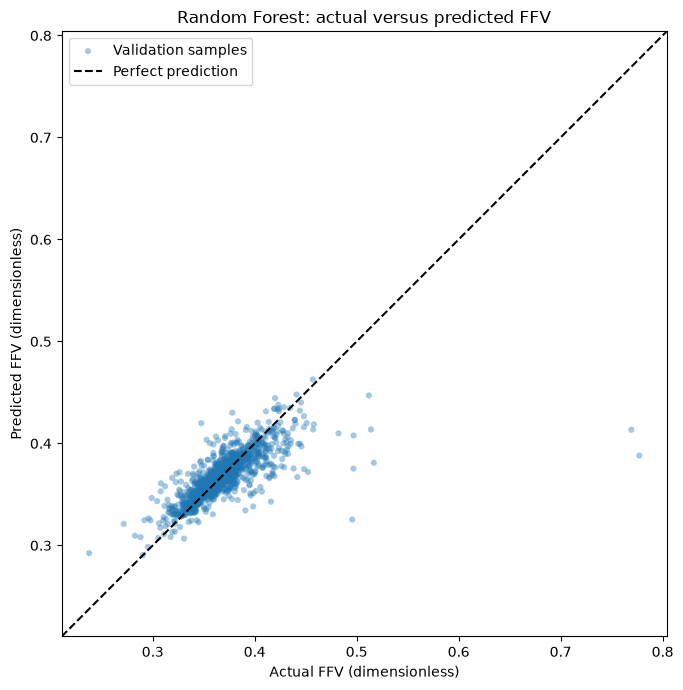

In [95]:
# Combine actual and predicted FFV values using their matching indices.
ffv_prediction_review = pd.DataFrame({
    "actual_FFV": y_valid_ffv,
    "predicted_FFV": rf_ffv_predictions,
})

# Determine shared limits for both axes.
plot_min = ffv_prediction_review.min().min()
plot_max = ffv_prediction_review.max().max()
plot_padding = (plot_max - plot_min) * 0.05
plot_limits = [
    plot_min - plot_padding,
    plot_max + plot_padding,
]

# Plot validation predictions against actual target values.
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    ffv_prediction_review["actual_FFV"],
    ffv_prediction_review["predicted_FFV"],
    s=20,
    alpha=0.4,
    edgecolors="none",
    label="Validation samples",
)

# Add the reference line for perfect predictions.
ax.plot(
    plot_limits,
    plot_limits,
    color="black",
    linestyle="--",
    label="Perfect prediction",
)

# Use identical scales on both axes.
ax.set_xlim(plot_limits)
ax.set_ylim(plot_limits)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("Actual FFV (dimensionless)")
ax.set_ylabel("Predicted FFV (dimensionless)")
ax.set_title("Random Forest: actual versus predicted FFV")
ax.legend()

fig.tight_layout()
plt.show()

#### Findings — Actual versus predicted FFV

- Many validation samples in the densely populated central FFV range
  lie close to the perfect-prediction line.
- Several samples with higher actual FFV values are underestimated.
- Two visually prominent samples near actual FFV 0.77 have predictions
  around 0.39–0.41.
- The overall MAE therefore coexists with some large individual errors.
- Approximate values above were read from the plot. Exact errors and
  sample identities will be inspected next.
- The plot alone does not establish the chemical cause of these errors
  or demonstrate that the corresponding target values are incorrect.

#### Ergebnisse – Tatsächlicher versus vorhergesagter FFV-Wert

- Viele Validierungsstichproben im dicht besetzten mittleren FFV-Bereich
liegen nahe an der Linie für eine perfekte Vorhersage.
- Einige Stichproben mit höheren tatsächlichen FFV-Werten werden unterschätzt.
- Zwei auffällige Stichproben bei einem tatsächlichen FFV-Wert von etwa 0,77
weisen Vorhersagewerte im Bereich von 0,39–0,41 auf.
- Der mittlere absolute Fehler (MAE) geht somit mit einigen größeren Einzelfehlern einher.
- Die oben genannten Näherungswerte wurden aus dem Diagramm abgelesen. 
Die genauen Fehler sowie die Identität der jeweiligen Stichproben werden im nächsten Schritt untersucht.
- Das Diagramm allein lässt keinen Rückschluss auf die chemische Ursache dieser Fehler zu
und belegt auch nicht, dass die entsprechenden Zielwerte fehlerhaft sind.

#### 20.3.5 Inspect the largest FFV prediction errors

Calculate signed and absolute errors for each validation sample.
Select the ten largest absolute errors and retrieve the corresponding
polymer IDs and SMILES.

Signed error is defined as predicted minus actual FFV:
positive values indicate overestimation; negative values indicate
underestimation.

Samples are inspected without removing them or changing their targets.

In [97]:
# Copy the validation prediction table.
ffv_error_review = ffv_prediction_review.copy()

# Calculate signed errors: prediction minus actual value.
ffv_error_review["signed_error"] = (
    ffv_error_review["predicted_FFV"]
    - ffv_error_review["actual_FFV"]
)

# Calculate absolute errors.
ffv_error_review["absolute_error"] = (
    ffv_error_review["signed_error"].abs()
)

# Select the ten largest absolute errors.
largest_ffv_errors = ffv_error_review.nlargest(
    n=10,
    columns="absolute_error",
).copy()

# Retrieve polymer identifiers and structures using the original index.
largest_ffv_errors = train.loc[
    largest_ffv_errors.index,
    ["id", "SMILES"],
].join(largest_ffv_errors)

display(largest_ffv_errors)

,id,SMILES,actual_FFV,predicted_FFV,signed_error,absolute_error
6064,1645416728,*CCC1C[N+](C)(C)CC1*,0.777097,0.388128,-0.388969,0.388969
645,180321996,*CCCCCCCCCC[N+](*)(C)C,0.769315,0.413473,-0.355843,0.355843
6689,1814521184,*CC(*)(C)C(=O)OCCO[N+](=O)[O-],0.495595,0.325300,-0.170294,0.170294
3143,852184111,*c1cc(C)c(*)s1,0.516864,0.381061,-0.135804,0.135804
1089,293886642,*c1ccc(*)s1,0.496817,0.375284,-0.121534,0.121534
5032,1365848174,*c1ccc(-c2nc3cc4nc(-c5ccccc5)c(*)nc4cc3nc2-c2c...,0.513982,0.413658,-0.100324,0.100324
6212,1684855250,*O[Si](C)(C)C#C[Si](C)(C)C#C[Si](C)(C)C#C[Si](...,0.496932,0.407732,-0.089199,0.089199
5269,1431061733,*CC(*)c1ccc(Cl)c([N+](=O)[O-])c1,0.452348,0.371913,-0.080436,0.080436
3704,1003609082,*c1ccc(C#Cc2cc(OCCCCCCCC)c(C#Cc3ccc(-c4nnc(*)o...,0.441777,0.367026,-0.074752,0.074752
4141,1121030015,*CCS*,0.448504,0.374702,-0.073803,0.073803


#### Findings — Largest FFV prediction errors

- All ten largest absolute validation errors are underestimations.
  This observation concerns the selected cases, not all validation samples.
- The two largest errors correspond to polymer IDs 1645416728
  and 180321996.
- Their actual FFV values are approximately 0.777097 and 0.769315;
  predictions are approximately 0.388128 and 0.413473.
- Their absolute errors are approximately 0.388969 and 0.355843.
- Both SMILES contain positively charged nitrogen atoms.
  This observation does not establish the cause of the prediction errors.
- Further inspection will compare these samples with the training
  target distribution and molecular descriptors.
- All samples and target values remain unchanged.

#### 20.3.6 Inspect FFV target coverage in training and validation

Compare target ranges and upper quantiles between the existing training
and validation subsets. Inspect the ten highest training FFV values.

Check whether validation targets fall outside the training target range.
Target-range coverage alone does not establish structural similarity.

In [98]:
# Compare FFV target distributions.
ffv_target_coverage = pd.DataFrame({
    "Training": y_train_ffv.describe(
        percentiles=[0.50, 0.95, 0.99]
    ),
    "Validation": y_valid_ffv.describe(
        percentiles=[0.50, 0.95, 0.99]
    ),
})

display(ffv_target_coverage)

# Count validation targets outside the training target range.
ffv_training_min = y_train_ffv.min()
ffv_training_max = y_train_ffv.max()

print(
    "Validation targets below training minimum:",
    (y_valid_ffv < ffv_training_min).sum(),
)
print(
    "Validation targets above training maximum:",
    (y_valid_ffv > ffv_training_max).sum(),
)

# Inspect the ten highest FFV targets available during training.
highest_training_ffv = y_train_ffv.nlargest(n=10)

highest_training_ffv_review = train.loc[
    highest_training_ffv.index,
    ["id", "SMILES", "FFV"],
].copy()

display(highest_training_ffv_review)

,Training,Validation
count,5624.000000,1406.000000
mean,0.367101,0.367658
std,0.028938,0.032160
min,0.226992,0.237637
50%,0.364249,0.364297
95%,0.416375,0.418577
99%,0.451199,0.448498
max,0.774066,0.777097


Validation targets below training minimum: 0
Validation targets above training maximum: 1


,id,SMILES,FFV
2966,806978622,*CC(*)O[N+](=O)[O-],0.774066
2338,637669265,*CC(*)C(=O)NCCC[N+](C)(C)C,0.687057
2626,713393124,*CC(*)C(=O)N1CC[NH+](CC)CC1,0.650907
633,177272960,*c1ccc(*)[nH]1,0.563897
5385,1462748332,*c1ccc(-c2nc3ccc(-c4ccc5nc(*)c(-c6ccccc6)nc5c4...,0.532769
1374,370833911,*CCSSSS*,0.528203
4455,1201617221,*c1ccc(-c2sc(-c3cc(SCCCC)c(*)s3)cc2SCCCC)cc1,0.507618
2411,660253930,*c1ccc(-c2sc(-c3ccc(-c4cc(CCCC)c(*)s4)cc3)cc2C...,0.500778
7259,1960875010,*c1ccc(-c2cnc3cc4nc(*)cnc4cc3n2)cc1,0.498316
373,103451865,*O[Si](C)(C)C#C[Si](C)(C)C#C[Si](C)(C)C#C[Si](...,0.498243


#### Findings — FFV target coverage

- Training and validation medians and upper quantiles are similar.
- The training maximum is 0.774066; the validation maximum is 0.777097.
- One validation target exceeds the training maximum.
  No validation targets fall below the training minimum.
- The second-largest prediction error occurs for a target of 0.769315,
  which lies within the training target range.
- High FFV training targets exist but are rare: the training
  99th percentile is approximately 0.451199.
- Target-range coverage alone does not explain the large errors.
  Descriptor representation and structural similarity require inspection.
- A positively charged atom does not necessarily imply a positive
  net formal charge of the represented molecule.

#### 20.3.7 Compare descriptor values with training ranges

Compare the nine descriptors of the two validation samples with the
largest absolute errors against the FFV training descriptor ranges.

Being within every individual range does not guarantee that a
combination of descriptors is well represented in training.

In [99]:
# Select the two validation samples with the largest errors.
selected_error_indices = largest_ffv_errors.head(2).index

# Calculate descriptor limits from the training features.
training_descriptor_min = X_train_ffv.min()
training_descriptor_max = X_train_ffv.max()

# Compare each selected sample with the training limits.
for sample_index in selected_error_indices:
    sample_descriptors = X_valid_ffv.loc[sample_index]

    descriptor_range_review = pd.DataFrame({
        "training_min": training_descriptor_min,
        "sample_value": sample_descriptors,
        "training_max": training_descriptor_max,
    })

    descriptor_range_review["below_training_min"] = (
        sample_descriptors < training_descriptor_min
    )
    descriptor_range_review["above_training_max"] = (
        sample_descriptors > training_descriptor_max
    )

    print("Original row index:", sample_index)
    print("Polymer ID:", train.loc[sample_index, "id"])
    display(descriptor_range_review)

Original row index: 6064
Polymer ID: 1645416728


,training_min,sample_value,training_max,below_training_min,above_training_max
MolWt,26.0380,126.2230,2202.48200,False,False
HeavyAtomCount,2.0000,9.0000,164.00000,False,False
NumAtoms,4.0000,11.0000,166.00000,False,False
NumRings,0.0000,1.0000,18.00000,False,False
NumAromaticRings,0.0000,0.0000,16.00000,False,False
NumHDonors,0.0000,0.0000,8.00000,False,False
NumHAcceptors,0.0000,0.0000,45.00000,False,False
MolLogP,-4.8229,1.3881,27.55734,False,False
TPSA,0.0000,0.0000,437.26000,False,False


Original row index: 645
Polymer ID: 180321996


,training_min,sample_value,training_max,below_training_min,above_training_max
MolWt,26.0380,184.3470,2202.48200,False,False
HeavyAtomCount,2.0000,13.0000,164.00000,False,False
NumAtoms,4.0000,15.0000,166.00000,False,False
NumRings,0.0000,0.0000,18.00000,False,False
NumAromaticRings,0.0000,0.0000,16.00000,False,False
NumHDonors,0.0000,0.0000,8.00000,False,False
NumHAcceptors,0.0000,0.0000,45.00000,False,False
MolLogP,-4.8229,3.6155,27.55734,False,False
TPSA,0.0000,0.0000,437.26000,False,False


#### Findings — Descriptor range inspection

- For both samples with the largest absolute FFV errors, all nine
  descriptor values lie within their respective FFV training ranges.
- Neither sample is flagged as below a training minimum or above
  a training maximum.
- Individual descriptor-range violations therefore do not explain
  these two large errors.
- This check does not assess local sample density, unusual descriptor
  combinations, or chemical similarity.
- The current feature set has no explicit formal-charge or
  charged-atom-count descriptor. Their predictive value remains
  to be evaluated.

### 20.4 Random Forest models for all five targets

Train a separate Random Forest for each target using the existing
target-specific splits and nine molecular descriptors.

Use the same initial configuration for every target: 200 trees and
random_state=42. Compare training and validation MAE, and evaluate
each model against its training-median baseline.

These are development results from the existing random splits.
Hyperparameters have not been tuned.

In [100]:
# Store fitted models and evaluation results.
rf_models = {}
rf_result_rows = []

for target in target_columns:
    # Retrieve the existing split for this target.
    target_split = modeling_splits[target]
    X_train = target_split["X_train"]
    X_valid = target_split["X_valid"]
    y_train = target_split["y_train"]
    y_valid = target_split["y_valid"]

    # Create and train a separate model for this target.
    model = RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    model.fit(X_train, y_train)

    # Predict training and validation targets.
    train_predictions = pd.Series(
        model.predict(X_train),
        index=y_train.index,
    )
    valid_predictions = pd.Series(
        model.predict(X_valid),
        index=y_valid.index,
    )

    # Calculate training and validation MAE.
    train_mae = (y_train - train_predictions).abs().mean()
    valid_mae = (y_valid - valid_predictions).abs().mean()

    # Calculate the training-median baseline validation MAE.
    training_median = y_train.median()
    baseline_mae = (y_valid - training_median).abs().mean()

    # Store the fitted model and its results.
    rf_models[target] = model

    rf_result_rows.append({
        "target": target,
        "training_rows": len(y_train),
        "validation_rows": len(y_valid),
        "baseline_validation_mae": baseline_mae,
        "rf_training_mae": train_mae,
        "rf_validation_mae": valid_mae,
    })

    print("Completed:", target)

# Display results for all five targets.
rf_results = pd.DataFrame(rf_result_rows)
display(rf_results)

Completed: Tg
Completed: FFV
Completed: Tc
Completed: Density
Completed: Rg


,target,training_rows,validation_rows,baseline_validation_mae,rf_training_mae,rf_validation_mae
0,Tg,408,103,78.708284,23.116752,62.648394
1,FFV,5624,1406,0.021403,0.004238,0.010925
2,Tc,589,148,0.080060,0.016919,0.039240
3,Density,490,123,0.104401,0.021625,0.066089
4,Rg,491,123,3.863995,0.992764,2.880267


#### Findings — Random Forest models for all targets

- Separate Random Forest models were trained for all five targets,
  using nine descriptors, 200 trees, and random_state=42.
- Each model achieved lower validation MAE than its corresponding
  training-median baseline on the same validation samples.
- Approximate validation MAE reductions:
  - Tg: 20.4%
  - FFV: 49.0%
  - Tc: 51.0%
  - Density: 36.7%
  - Rg: 25.5%
- The FFV results match the previous individual model evaluation.
- Training MAE is substantially lower than validation MAE for every
  target, motivating further investigation of overfitting.
- These are development results from single random splits.
  Cross-validation and structural generalization checks remain necessary.
- Absolute MAE values have different units and must not be compared
  directly across target properties.

### 20.5 Linear regression for all five targets

Train a separate ordinary least squares regression model for each target
using the same nine descriptors and existing splits as the Random Forest.

Evaluate training and validation MAE. Training minimizes squared errors;
MAE is used here to compare predictive performance.

In [101]:
from sklearn.linear_model import LinearRegression

# Store fitted linear models and their evaluation results.
lr_models = {}
lr_result_rows = []

for target in target_columns:
    # Retrieve the existing split for this target.
    target_split = modeling_splits[target]
    X_train = target_split["X_train"]
    X_valid = target_split["X_valid"]
    y_train = target_split["y_train"]
    y_valid = target_split["y_valid"]

    # Create and train a separate linear regression model.
    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)

    # Predict training and validation targets.
    train_predictions = pd.Series(
        linear_model.predict(X_train),
        index=y_train.index,
    )
    valid_predictions = pd.Series(
        linear_model.predict(X_valid),
        index=y_valid.index,
    )

    # Calculate training and validation MAE.
    train_mae = (y_train - train_predictions).abs().mean()
    valid_mae = (y_valid - valid_predictions).abs().mean()

    # Store the fitted model and its results.
    lr_models[target] = linear_model

    lr_result_rows.append({
        "target": target,
        "training_rows": len(y_train),
        "validation_rows": len(y_valid),
        "lr_training_mae": train_mae,
        "lr_validation_mae": valid_mae,
    })

    print("Completed:", target)

# Display linear regression results.
lr_results = pd.DataFrame(lr_result_rows)
display(lr_results)

Completed: Tg
Completed: FFV
Completed: Tc
Completed: Density
Completed: Rg


,target,training_rows,validation_rows,lr_training_mae,lr_validation_mae
0,Tg,408,103,55.656168,58.901433
1,FFV,5624,1406,0.016296,0.016863
2,Tc,589,148,0.043136,0.044047
3,Density,490,123,0.062631,0.061519
4,Rg,491,123,3.363095,3.268056


#### Findings — Linear regression and model comparison

- Linear regression outperformed the training-median baseline for all
  five targets on the existing 20% test splits.
- Linear regression achieved lower test MAE than Random Forest for
  Tg and Density.
- Random Forest achieved lower test MAE for FFV, Tc, and Rg.
- Linear regression training and test MAE values are relatively close.
- Slightly lower test than training MAE for Density and Rg can occur
  because the subsets contain different samples.
- No single model performed best for every target in this comparison.
- These are development comparisons on the existing test splits.
  Model rankings and stability still need assessment through
  cross-validation within the training subsets.

### 20.6 Compare baseline, linear regression, and Random Forest

Combine the existing test MAE results for each target.

All approaches use the same test samples per target. Compare errors
within each target because the target properties have different units.

The 20% subsets are called test sets here. Since they inform model
selection, the results remain development estimates.

### 20.6 Vergleich von Baseline, linearer Regression und Random Forest

Führe die vorliegenden MAE-Ergebnisse auf dem Testdatensatz für jedes Target zusammen.

Alle Ansätze verwenden für jedes Target dieselben Teststichproben. Vergleiche die Fehler innerhalb der jeweiligen Targets, da die Targets unterschiedliche Einheiten aufweisen können.

Die 20%-Teilmengen werden hier als Testdatensätze bezeichnet. Da sie in die Modellauswahl einfließen, sind die Ergebnisse lediglich als Schätzwerte für die Entwicklungsphase zu verstehen.

In [102]:
# Start with the baseline results, indexed by target.
model_comparison = rf_results.set_index("target")[
    ["baseline_validation_mae"]
].copy()

# Align model results by target name.
model_comparison["linear_regression_test_mae"] = (
    lr_results.set_index("target")["lr_validation_mae"]
)

model_comparison["random_forest_test_mae"] = (
    rf_results.set_index("target")["rf_validation_mae"]
)

# Rename the baseline column using our test-set terminology.
model_comparison = model_comparison.rename(columns={
    "baseline_validation_mae": "baseline_test_mae",
})

# Identify the approach with the lowest test MAE for each target.
mae_columns = [
    "baseline_test_mae",
    "linear_regression_test_mae",
    "random_forest_test_mae",
]

model_labels = {
    "baseline_test_mae": "Median baseline",
    "linear_regression_test_mae": "Linear regression",
    "random_forest_test_mae": "Random Forest",
}

model_comparison["lowest_test_mae_model"] = (
    model_comparison[mae_columns]
    .idxmin(axis=1)
    .map(model_labels)
)

display(model_comparison)

,baseline_test_mae,linear_regression_test_mae,random_forest_test_mae,lowest_test_mae_model
target,,,,
Tg,78.708284,58.901433,62.648394,Linear regression
FFV,0.021403,0.016863,0.010925,Random Forest
Tc,0.080060,0.044047,0.039240,Random Forest
Density,0.104401,0.061519,0.066089,Linear regression
Rg,3.863995,3.268056,2.880267,Random Forest


#### Findings — Combined model comparison

- Linear regression has the lowest test MAE for Tg and Density.
- Random Forest has the lowest test MAE for FFV, Tc, and Rg.
- Both trained model types outperform the median baseline for every target.
- No single model performs best for all targets in this comparison.
- The rankings apply to the current 20% test splits and the evaluated
  model configurations. They do not establish a final model selection.

### 20.7 Five-fold cross-validation within the training subsets

#### 20.7.1 Define and inspect the folds

Split each existing 80% training subset into five folds.
In each round, fit on four folds and evaluate on the remaining fold.

The existing 20% test subsets are excluded from cross-validation.
First inspect the fold sizes for FFV before evaluating models.

In [103]:
from sklearn.model_selection import KFold

# Define the cross-validation settings.
N_SPLITS = 5

cv = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Use only the existing FFV training subset.
X_cv_ffv = modeling_splits["FFV"]["X_train"]

# Inspect the sizes of the five internal splits.
fold_rows = []

for fold_number, (fit_positions, check_positions) in enumerate(
    cv.split(X_cv_ffv),
    start=1,
):
    fold_rows.append({
        "fold": fold_number,
        "fit_rows": len(fit_positions),
        "check_rows": len(check_positions),
    })

fold_sizes = pd.DataFrame(fold_rows)
display(fold_sizes)

,fold,fit_rows,check_rows
0,1,4499,1125
1,2,4499,1125
2,3,4499,1125
3,4,4499,1125
4,5,4500,1124


#### 20.7.2 Evaluate FFV models with five-fold cross-validation

Evaluate the median baseline, linear regression, and Random Forest
on identical folds within the FFV training subset.

Each model is fitted separately in every fold. The median baseline
is calculated using only that fold's fitting targets.

The existing 20% test set is excluded.

In [104]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score

# Select the targets matching the FFV training features.
y_cv_ffv = modeling_splits["FFV"]["y_train"]

# Define model templates for cross-validation.
ffv_cv_models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Linear regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

# Store one MAE value per fold and model.
ffv_cv_mae = pd.DataFrame(
    index=pd.RangeIndex(start=1, stop=N_SPLITS + 1, name="fold")
)

for model_name, estimator in ffv_cv_models.items():
    negative_mae_scores = cross_val_score(
        estimator=estimator,
        X=X_cv_ffv,
        y=y_cv_ffv,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1,
        error_score="raise",
    )

    # Convert negative scores to positive MAE values.
    ffv_cv_mae[model_name] = -negative_mae_scores

    print("Completed:", model_name)

display(ffv_cv_mae)

Completed: Median baseline
Completed: Linear regression
Completed: Random Forest


,Median baseline,Linear regression,Random Forest
fold,,,
1,0.020865,0.016703,0.011158
2,0.020458,0.015627,0.010340
3,0.020656,0.016347,0.011431
4,0.021146,0.017109,0.011413
5,0.020009,0.015998,0.010145


#### 20.7.3 Summarize FFV cross-validation results

Calculate the mean, sample standard deviation, minimum, and maximum
of the five MAE values for each approach.

The standard deviation describes variation across these folds.
It is not a confidence interval or an individual prediction uncertainty.

In [105]:
# Summarize the five fold errors for each approach.
ffv_cv_summary = ffv_cv_mae.agg(
    ["mean", "std", "min", "max"]
).T

# Assign descriptive column names.
ffv_cv_summary = ffv_cv_summary.rename(columns={
    "mean": "mean_cv_mae",
    "std": "std_cv_mae",
    "min": "min_fold_mae",
    "max": "max_fold_mae",
})

# Show the lowest average MAE first.
ffv_cv_summary = ffv_cv_summary.sort_values(
    by="mean_cv_mae"
)

display(ffv_cv_summary)

,mean_cv_mae,std_cv_mae,min_fold_mae,max_fold_mae
Random Forest,0.010897,0.000611,0.010145,0.011431
Linear regression,0.016357,0.000581,0.015627,0.017109
Median baseline,0.020627,0.000429,0.020009,0.021146


#### Findings — FFV cross-validation summary

- Random Forest achieved the lowest MAE in all five folds.
- Mean cross-validation MAE:
  - Random Forest: approximately 0.010897.
  - Linear regression: approximately 0.016357.
  - Median baseline: approximately 0.020627.
- Random Forest reduced mean CV MAE by approximately 47.2%
  relative to the median baseline.
- Its fold MAE ranged from approximately 0.010145 to 0.011431,
  with a sample standard deviation of approximately 0.000611.
- Mean CV MAE is close to the previously observed test MAE of 0.010925.
- These averages do not eliminate the large individual errors
  identified earlier or establish generalization to new polymer families.
- Cross-validation used only the existing FFV training subset.

#### 20.7.4 Cross-validation for all five targets

Evaluate the median baseline, linear regression, and Random Forest
using five-fold cross-validation within each target's training subset.

For each target, all approaches use identical folds. Store individual
fold errors and summarize their mean and sample standard deviation.

The existing 20% test subsets are excluded.

In [106]:
# Store individual fold errors and summary statistics.
cv_fold_rows = []
cv_summary_rows = []

for target in target_columns:
    # Select only this target's existing training subset.
    X_cv = modeling_splits[target]["X_train"]
    y_cv = modeling_splits[target]["y_train"]

    # Fix identical fold positions for all models of this target.
    target_folds = list(cv.split(X_cv))

    for model_name, estimator in ffv_cv_models.items():
        # Evaluate fresh model copies on the five folds.
        negative_mae_scores = cross_val_score(
            estimator=estimator,
            X=X_cv,
            y=y_cv,
            cv=target_folds,
            scoring="neg_mean_absolute_error",
            n_jobs=1,
            error_score="raise",
        )

        fold_mae = -negative_mae_scores

        # Store each fold's MAE.
        for fold_number, mae in enumerate(fold_mae, start=1):
            cv_fold_rows.append({
                "target": target,
                "model": model_name,
                "fold": fold_number,
                "mae": mae,
            })

        # Store summary statistics for this target and model.
        cv_summary_rows.append({
            "target": target,
            "model": model_name,
            "training_rows": len(y_cv),
            "mean_cv_mae": fold_mae.mean(),
            "std_cv_mae": fold_mae.std(ddof=1),
            "min_fold_mae": fold_mae.min(),
            "max_fold_mae": fold_mae.max(),
        })

    print("Completed:", target)

# Create tables containing detailed and summarized results.
cv_fold_results = pd.DataFrame(cv_fold_rows)
cv_summary = pd.DataFrame(cv_summary_rows)

display(cv_summary)

Completed: Tg
Completed: FFV
Completed: Tc
Completed: Density
Completed: Rg


,target,model,training_rows,mean_cv_mae,std_cv_mae,min_fold_mae,max_fold_mae
0,Tg,Median baseline,408,88.595225,3.013855,85.016094,93.309342
1,Tg,Linear regression,408,58.145842,6.273931,52.000542,68.754593
2,Tg,Random Forest,408,61.701580,5.938314,53.538530,69.160914
3,FFV,Median baseline,5624,0.020627,0.000429,0.020009,0.021146
4,FFV,Linear regression,5624,0.016357,0.000581,0.015627,0.017109
5,FFV,Random Forest,5624,0.010897,0.000611,0.010145,0.011431
6,Tc,Median baseline,589,0.075423,0.003113,0.070810,0.079448
7,Tc,Linear regression,589,0.044440,0.004287,0.041063,0.049807
8,Tc,Random Forest,589,0.040360,0.003859,0.035028,0.044966
9,Density,Median baseline,490,0.104542,0.015672,0.093913,0.132121


#### Findings — Cross-validation across all targets

- Five-fold cross-validation was completed within each target's
  existing training subset.
- Both trained model types achieved lower mean CV MAE than the
  median baseline for every target.
- Linear regression achieved the lowest mean CV MAE for Tg.
- Random Forest achieved the lowest mean CV MAE for FFV, Tc,
  Density, and Rg.
- The Density ranking differs from the existing 20% test-set result,
  where linear regression achieved lower MAE.
- Differences between model means should be considered alongside
  fold variation. Fold standard deviations are not significance tests.
- FFV results match the earlier individual cross-validation.
- Random-fold CV does not establish performance on new polymer families.

#### 20.7.5 Paired fold comparison for Tg and Density

Compare linear regression and Random Forest MAE on identical folds.

Define the difference as:
Random Forest MAE minus linear regression MAE.

Negative differences favour Random Forest.
Positive differences favour linear regression.

This is a descriptive comparison, not a statistical significance test.

In [107]:
# Compare the two model types on matching folds.
for target in ["Tg", "Density"]:
    target_fold_results = cv_fold_results.loc[
        cv_fold_results["target"] == target
    ]

    # Place each model's MAE in a separate column.
    paired_mae = target_fold_results.pivot(
        index="fold",
        columns="model",
        values="mae",
    )[["Linear regression", "Random Forest"]].copy()

    # Negative differences favour Random Forest.
    paired_mae["rf_minus_lr_mae"] = (
        paired_mae["Random Forest"]
        - paired_mae["Linear regression"]
    )

    print("Target:", target)
    display(paired_mae)

    print(
        "Random Forest has lower MAE in folds:",
        (paired_mae["rf_minus_lr_mae"] < 0).sum(),
    )
    print(
        "Linear regression has lower MAE in folds:",
        (paired_mae["rf_minus_lr_mae"] > 0).sum(),
    )
    print(
        "Equal MAE in folds:",
        (paired_mae["rf_minus_lr_mae"] == 0).sum(),
    )

Target: Tg


model,Linear regression,Random Forest,rf_minus_lr_mae
fold,,,
1,57.231690,62.634463,5.402772
2,56.325859,58.596956,2.271097
3,68.754593,69.160914,0.406321
4,56.416525,64.577037,8.160512
5,52.000542,53.538530,1.537988


Random Forest has lower MAE in folds: 0
Linear regression has lower MAE in folds: 5
Equal MAE in folds: 0
Target: Density


model,Linear regression,Random Forest,rf_minus_lr_mae
fold,,,
1,0.063697,0.054754,-0.008943
2,0.088137,0.079593,-0.008544
3,0.056334,0.061915,0.005581
4,0.058863,0.061580,0.002717
5,0.058349,0.043364,-0.014985


Random Forest has lower MAE in folds: 3
Linear regression has lower MAE in folds: 2
Equal MAE in folds: 0


#### Findings — Paired fold comparison

- For Tg, linear regression achieved lower MAE than Random Forest
  in all five matching folds.
- Random Forest minus linear regression MAE ranged from approximately
  0.41 to 8.16 °C for Tg.
- This supports linear regression as the stronger current Tg candidate
  among these two evaluated configurations.

- For Density, Random Forest achieved lower MAE in three folds;
  linear regression achieved lower MAE in two folds.
- Random Forest has lower mean CV MAE, whereas linear regression
  has lower MAE on the existing 20% test set.
- Density model rankings therefore depend on the split, and both
  approaches remain candidates for further comparison.

- These are descriptive results from five folds with overlapping
  training subsets, not a statistical significance test.

### 20.8 Learning curves

#### 20.8.1 Calculate the FFV Random Forest learning curve

Evaluate five training sizes within the existing FFV training subset
using five-fold cross-validation.

For each size, calculate training and internal validation MAE.
The existing 20% test set is excluded.

Training fractions refer to the available fitting portion of each
CV split, not to the complete dataset.

In [108]:
from sklearn.model_selection import learning_curve

# Define fractions of the available fitting rows within each CV split.
LEARNING_FRACTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]

# Calculate learning-curve scores using FFV training data only.
ffv_learning_sizes, ffv_learning_train_scores, ffv_learning_check_scores = (
    learning_curve(
        estimator=RandomForestRegressor(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        X=X_cv_ffv,
        y=y_cv_ffv,
        train_sizes=LEARNING_FRACTIONS,
        cv=cv,
        scoring="neg_mean_absolute_error",
        shuffle=True,
        random_state=RANDOM_STATE,
        n_jobs=1,
        error_score="raise",
    )
)

# Convert negative scores to positive MAE values.
ffv_learning_train_mae = -ffv_learning_train_scores
ffv_learning_check_mae = -ffv_learning_check_scores

# Summarize the five folds for each training size.
ffv_learning_summary = pd.DataFrame({
    "fit_rows": ffv_learning_sizes,
    "mean_training_mae": ffv_learning_train_mae.mean(axis=1),
    "std_training_mae": ffv_learning_train_mae.std(axis=1, ddof=1),
    "mean_cv_mae": ffv_learning_check_mae.mean(axis=1),
    "std_cv_mae": ffv_learning_check_mae.std(axis=1, ddof=1),
})

display(ffv_learning_summary)

,fit_rows,mean_training_mae,std_training_mae,mean_cv_mae,std_cv_mae
0,899,0.004848,0.000129,0.013320,0.000615
1,1799,0.004757,0.000188,0.012511,0.000574
2,2699,0.004587,0.000107,0.011925,0.000519
3,3599,0.004487,0.000099,0.011349,0.000564
4,4499,0.004326,0.000086,0.010897,0.000621


### 20.8.2 Plot the FFV learning curves

Plot the mean training and cross-validation MAE for increasing
training sizes.

The shaded regions represent one standard deviation across the
five folds. They describe variation between folds and are not
confidence intervals.

Only the existing training subset is used. The outer test set
is excluded from this analysis.


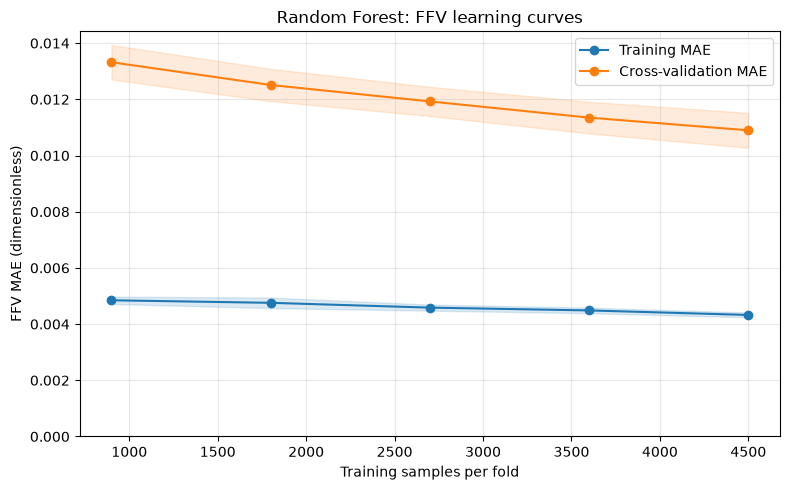

In [109]:
# Select training sizes and mean errors.
fit_rows = ffv_learning_summary["fit_rows"]
training_mean = ffv_learning_summary["mean_training_mae"]
cv_mean = ffv_learning_summary["mean_cv_mae"]

# Select the standard deviations across folds.
training_std = ffv_learning_summary["std_training_mae"]
cv_std = ffv_learning_summary["std_cv_mae"]

# Create the figure and axes.
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the mean training and cross-validation errors.
ax.plot(
    fit_rows,
    training_mean,
    marker="o",
    color="tab:blue",
    label="Training MAE",
)

ax.plot(
    fit_rows,
    cv_mean,
    marker="o",
    color="tab:orange",
    label="Cross-validation MAE",
)

# Show one standard deviation above and below each mean.
ax.fill_between(
    fit_rows,
    training_mean - training_std,
    training_mean + training_std,
    color="tab:blue",
    alpha=0.15,
)

ax.fill_between(
    fit_rows,
    cv_mean - cv_std,
    cv_mean + cv_std,
    color="tab:orange",
    alpha=0.15,
)

# Label and display the plot.
ax.set_xlabel("Training samples per fold")
ax.set_ylabel("FFV MAE (dimensionless)")
ax.set_title("Random Forest: FFV learning curves")
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

### Findings — FFV learning curves

- Increasing the training size from 899 to 4,499 samples per fold
  reduced the mean cross-validation MAE from approximately
  0.01332 to 0.01090, an improvement of about 18.2%.
- Training MAE remained substantially lower than cross-validation
  MAE, indicating a persistent generalization gap.
- The gap narrowed as training size increased.
- Cross-validation MAE continued to decrease at the largest
  training size examined. Further improvement from additional
  data is possible but has not been demonstrated.
- Additional structural features and model regularization are
  candidates for further comparison.
- Shaded regions show one standard deviation across five folds,
  not confidence intervals.
- The outer test set was not used to construct these curves.

### Findings — FFV learning curves

- Increasing the training size from 899 to 4,499 samples per fold
  reduced the mean cross-validation MAE from approximately
  0.01332 to 0.01090, an improvement of about 18.2%.
- Training MAE remained substantially lower than cross-validation
  MAE, indicating a persistent generalization gap.
- The gap narrowed as training size increased.
- Cross-validation MAE continued to decrease at the largest
  training size examined. Further improvement from additional
  data is possible but has not been demonstrated.
- Additional structural features and model regularization are
  candidates for further comparison.
- Shaded regions show one standard deviation across five folds,
  not confidence intervals.
- The outer test set was not used to construct these curves.

### 20.8.3 Calculate the linear regression learning curve

Evaluate linear regression at the same training sizes and with
the same cross-validation settings as the Random Forest.

Use only the existing FFV training subset. Keep the outer test
set excluded from the learning-curve analysis.

In [116]:
from sklearn.linear_model import LinearRegression

# Calculate the learning curve using the existing FFV training subset.
lr_learning_sizes, lr_train_scores, lr_cv_scores = learning_curve(
    estimator=LinearRegression(),
    X=X_cv_ffv,
    y=y_cv_ffv,
    train_sizes=LEARNING_FRACTIONS,
    cv=cv,
    scoring="neg_mean_absolute_error",
    shuffle=True,
    random_state=RANDOM_STATE,
    n_jobs=1,
    error_score="raise",
)

# Convert negative scores to positive MAE values.
lr_train_mae = -lr_train_scores
lr_cv_mae = -lr_cv_scores

# Summarize the five folds for each training size.
lr_learning_summary = pd.DataFrame({
    "fit_rows": lr_learning_sizes,
    "mean_training_mae": lr_train_mae.mean(axis=1),
    "std_training_mae": lr_train_mae.std(axis=1, ddof=1),
    "mean_cv_mae": lr_cv_mae.mean(axis=1),
    "std_cv_mae": lr_cv_mae.std(axis=1, ddof=1),
})

display(lr_learning_summary)

,fit_rows,mean_training_mae,std_training_mae,mean_cv_mae,std_cv_mae
0,899,0.015999,0.000581,0.016478,0.000557
1,1799,0.016290,0.000386,0.016381,0.000548
2,2699,0.016331,0.000183,0.016397,0.000612
3,3599,0.016450,0.000128,0.016395,0.000578
4,4499,0.016292,0.000127,0.016357,0.000581


### 20.8.4 Compare the FFV learning curves

Compare linear regression and Random Forest using identical axis
scales, training sizes, and cross-validation settings.

Shaded regions show one standard deviation across the five folds.
They are not confidence intervals.

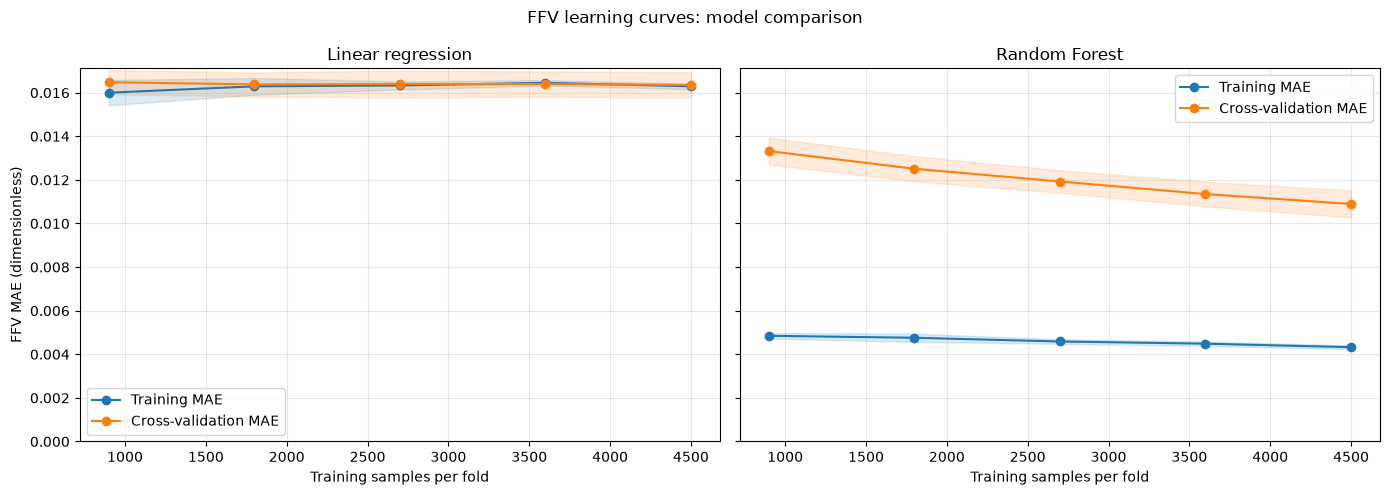

In [ ]:
# Create two plots with identical axis scales.
fig, axes = plt.subplots(
    ncols=2,
    figsize=(14, 5),
    sharex=True,
    sharey=True,
)

# Pair each model name with its existing learning-curve summary. (Ordne jedem Modellnamen die zugehörige Zusammenfassung der Lernkurve zu.)
learning_summaries = {
    "Linear regression": lr_learning_summary,
    "Random Forest": ffv_learning_summary,
}

# Plot both models without repeating the plotting code.
for ax, (model_name, summary) in zip(
    axes,
    learning_summaries.items(),
):
    sizes = summary["fit_rows"]
    train_mean = summary["mean_training_mae"]
    train_std = summary["std_training_mae"]
    cv_mean = summary["mean_cv_mae"]
    cv_std = summary["std_cv_mae"]

    ax.plot(
        sizes, train_mean,
        marker="o", color="tab:blue",
        label="Training MAE",
    )
    ax.plot(
        sizes, cv_mean,
        marker="o", color="tab:orange",
        label="Cross-validation MAE",
    )

    ax.fill_between(
        sizes,
        train_mean - train_std,
        train_mean + train_std,
        color="tab:blue",
        alpha=0.15,
    )
    ax.fill_between(
        sizes,
        cv_mean - cv_std,
        cv_mean + cv_std,
        color="tab:orange",
        alpha=0.15,
    )

    ax.set_title(model_name)
    ax.set_xlabel("Training samples per fold")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("FFV MAE (dimensionless)")
fig.suptitle("FFV learning curves: model comparison")
fig.tight_layout()
plt.show()

### Findings — FFV learning-curve comparison

- Random Forest achieved lower mean cross-validation MAE than
  linear regression at every training size examined.
- Linear regression training and cross-validation errors remained
  close to approximately 0.0164, with little improvement as
  training size increased.
- This pattern is consistent with limited model flexibility under
  the current feature representation, but does not establish
  the cause of the remaining error.
- Random Forest cross-validation MAE decreased as training size
  increased, while a training–validation gap remained.
- At 4,499 training samples per fold, Random Forest achieved
  approximately 33.4% lower mean CV MAE than linear regression
  (0.010897 versus 0.016357).
- A smaller training–validation gap does not necessarily imply
  better predictive performance.
- Shaded regions represent one standard deviation across folds,
  not confidence intervals.
- The outer test set was excluded from this analysis.

### 20.8.5 Calculate learning curves for Tg and Density

Compare linear regression and Random Forest at increasing training
sizes for Tg and Density.

Use the existing target-specific training subsets and identical
cross-validation settings for both models. Exclude the outer test sets.

In [118]:
# Define the targets and models to investigate.
learning_targets = ["Tg", "Density"]

learning_models = {
    "Linear regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

# Store one summary table for each target and model.
target_learning_summaries = {}

for target in learning_targets:
    # Select only this target's existing training subset.
    X_learning = modeling_splits[target]["X_train"]
    y_learning = modeling_splits[target]["y_train"]

    target_learning_summaries[target] = {}

    for model_name, estimator in learning_models.items():
        # Calculate errors at five training sizes.
        sizes, train_scores, cv_scores = learning_curve(
            estimator=estimator,
            X=X_learning,
            y=y_learning,
            train_sizes=LEARNING_FRACTIONS,
            cv=cv,
            scoring="neg_mean_absolute_error",
            shuffle=True,
            random_state=RANDOM_STATE,
            n_jobs=1,
            error_score="raise",
        )

        # Convert negative scores to positive MAE values.
        train_mae = -train_scores
        cv_mae = -cv_scores

        # Summarize results across folds.
        summary = pd.DataFrame({
            "fit_rows": sizes,
            "mean_training_mae": train_mae.mean(axis=1),
            "std_training_mae": train_mae.std(axis=1, ddof=1),
            "mean_cv_mae": cv_mae.mean(axis=1),
            "std_cv_mae": cv_mae.std(axis=1, ddof=1),
        })

        # Store and display the summary.
        target_learning_summaries[target][model_name] = summary

        print("Target:", target, "| Model:", model_name)
        display(summary)

Target: Tg | Model: Linear regression


,fit_rows,mean_training_mae,std_training_mae,mean_cv_mae,std_cv_mae
0,65,49.873107,5.027246,64.613209,7.997926
1,130,52.747920,3.246770,59.684019,6.791260
2,195,54.424687,1.890213,58.692805,7.279629
3,260,54.896743,1.673198,58.232694,6.527353
4,326,55.362290,1.465946,58.118345,6.280989


Target: Tg | Model: Random Forest


,fit_rows,mean_training_mae,std_training_mae,mean_cv_mae,std_cv_mae
0,65,23.530637,2.054804,67.917847,3.420848
1,130,23.702876,1.134663,67.278750,3.152921
2,195,23.476860,1.200863,65.540471,5.846988
3,260,23.360330,1.142384,63.517459,5.642165
4,326,22.914174,0.875246,62.186796,6.416488


Target: Density | Model: Linear regression


,fit_rows,mean_training_mae,std_training_mae,mean_cv_mae,std_cv_mae
0,78,0.051562,0.009542,0.070367,0.018581
1,156,0.057026,0.005363,0.068365,0.014032
2,235,0.059213,0.004293,0.065288,0.014524
3,313,0.062049,0.004108,0.065129,0.013941
4,392,0.062357,0.004259,0.065076,0.013172


Target: Density | Model: Random Forest


,fit_rows,mean_training_mae,std_training_mae,mean_cv_mae,std_cv_mae
0,78,0.027082,0.004666,0.084016,0.016542
1,156,0.025240,0.002798,0.071541,0.013336
2,235,0.024058,0.001645,0.068348,0.012104
3,313,0.023369,0.000594,0.064943,0.010774
4,392,0.022526,0.001200,0.059595,0.014193


### 20.8.6 Plot learning curves for glass transition temperature and mass density

Compare linear regression and Random Forest within each target.

Use identical axis scales within each row. Keep separate vertical
scales for the two targets because their errors have different units.

Shaded regions represent one standard deviation across five folds,
not confidence intervals.

Erstelle vier Diagramme:

- Obere Zeile: Glasübergangstemperatur.
- Untere Zeile: Massendichte.
- Linke Spalte: lineare Regression.
- Rechte Spalte: Random Forest.

Lies die bereits gespeicherten Ergebnistabellen.
Zeichne Mittelwerte und Streuungsbereiche.

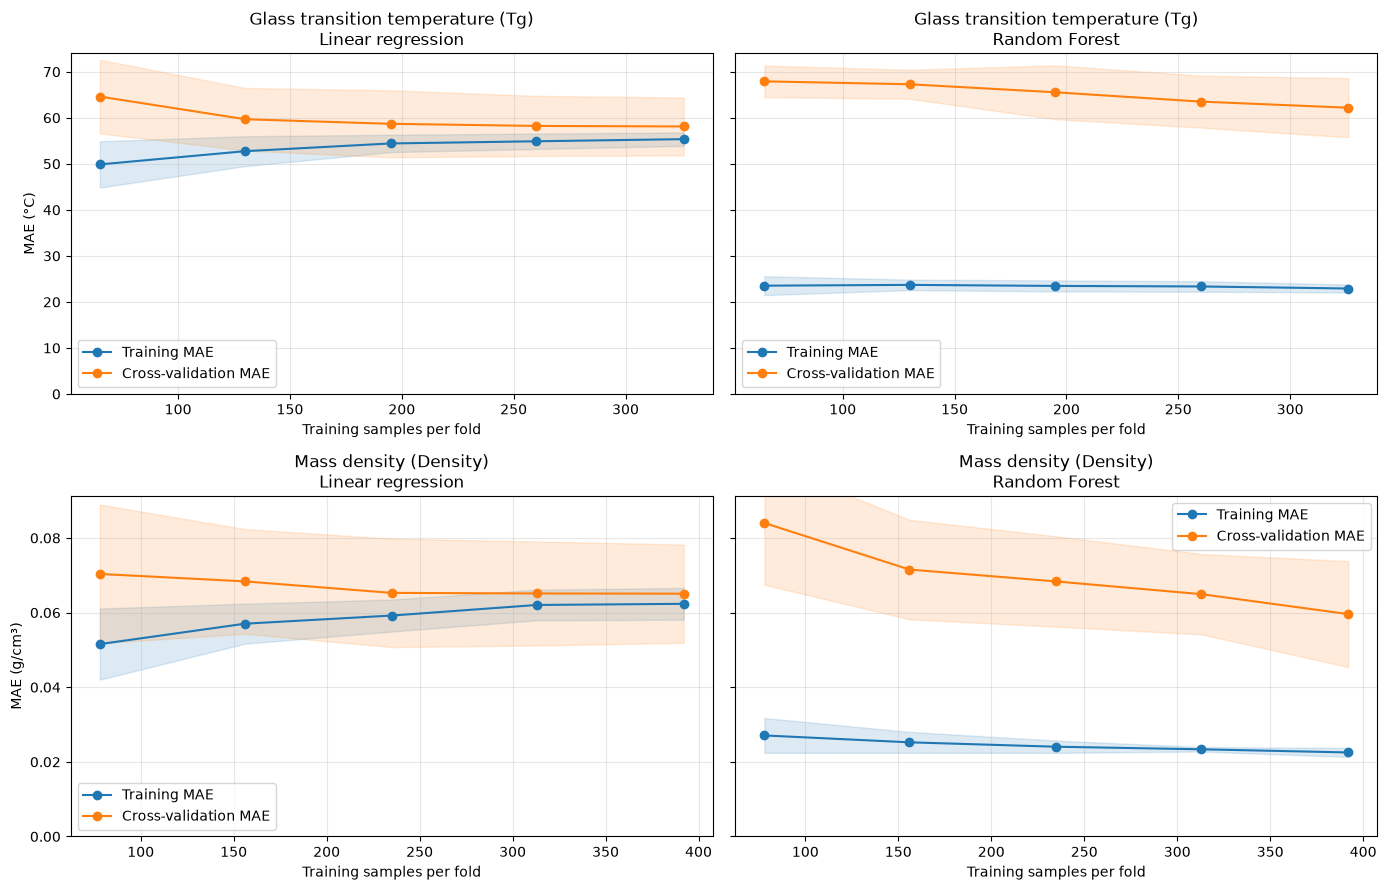

In [119]:
# Define descriptive labels for each target.
learning_target_labels = {
    "Tg": ("Glass transition temperature (Tg)", "MAE (°C)"),
    "Density": ("Mass density (Density)", "MAE (g/cm³)"),
}

# Create a grid with common vertical scales within each row.
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(14, 9),
    sharex="row",
    sharey="row",
)

for row, target in enumerate(learning_targets):
    target_label, error_label = learning_target_labels[target]

    for column, model_name in enumerate(learning_models):
        ax = axes[row, column]
        summary = target_learning_summaries[target][model_name]

        sizes = summary["fit_rows"]
        train_mean = summary["mean_training_mae"]
        train_std = summary["std_training_mae"]
        cv_mean = summary["mean_cv_mae"]
        cv_std = summary["std_cv_mae"]

        ax.plot(
            sizes, train_mean,
            marker="o", color="tab:blue",
            label="Training MAE",
        )
        ax.plot(
            sizes, cv_mean,
            marker="o", color="tab:orange",
            label="Cross-validation MAE",
        )

        ax.fill_between(
            sizes,
            train_mean - train_std,
            train_mean + train_std,
            color="tab:blue",
            alpha=0.15,
        )
        ax.fill_between(
            sizes,
            cv_mean - cv_std,
            cv_mean + cv_std,
            color="tab:orange",
            alpha=0.15,
        )

        ax.set_title(f"{target_label}\n{model_name}")
        ax.set_xlabel("Training samples per fold")
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.3)
        ax.legend()

    axes[row, 0].set_ylabel(error_label)

fig.tight_layout()
plt.show()

### Findings — Learning curves for glass transition temperature and mass density

#### Glass transition temperature (Tg)

- Linear regression achieved lower mean cross-validation MAE
  than Random Forest at every training size examined.
- At 326 training samples per fold, mean CV MAE was approximately
  58.12 °C for linear regression and 62.19 °C for Random Forest.
- Random Forest retained a substantial training–validation gap,
  consistent with overfitting under the current setup.
- Linear regression remains a useful candidate for this target.

#### Mass density (Density)

- Linear regression performed better at smaller training sizes.
- Random Forest improved more as training size increased and
  achieved slightly lower mean CV MAE at the two largest sizes.
- At 392 training samples per fold, mean CV MAE was approximately
  0.05960 g/cm³ for Random Forest and 0.06508 g/cm³ for
  linear regression.
- Fold-to-fold variation remains substantial. Both models remain
  candidates for further comparison.

#### Interpretation limits

- Shaded regions show one standard deviation across folds,
  not confidence intervals or a formal significance test.
- The outer test sets were excluded from these learning curves.
- These results support further development, not final model selection.

### 20.9 XGBoost comparison

Extend the existing model comparison with Suhmi's initial
XGBoost configuration.

Reuse the existing nine descriptors and target-specific splits.

### 20.9.1 Define the initial XGBoost model

Define a function that creates a new, untrained XGBoost regressor.
Evaluate this fixed configuration before parameter tuning.

In [121]:
from xgboost import XGBRegressor


# Reuse Suhmi's initial XGBoost configuration.
def create_xgboost():
    return XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


# Create an untrained model for inspection.
xgb_example = create_xgboost()

display(xgb_example)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


### 20.9.2 Cross-validate XGBoost for fractional free volume (FFV)

Evaluate the initial XGBoost configuration using the existing
FFV training subset and the same five cross-validation folds
as the previous models.

Compare fold-level MAE with the median baseline, linear regression,
and Random Forest. Exclude the outer test set.

In [122]:
from sklearn.model_selection import cross_val_score

# Evaluate XGBoost using the existing FFV training data and folds.
xgb_ffv_cv_mae = -cross_val_score(
    estimator=create_xgboost(),
    X=X_cv_ffv,
    y=y_cv_ffv,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
    error_score="raise",
)

# Preserve the earlier results and add XGBoost.
ffv_cv_with_xgb = ffv_cv_mae.copy()
ffv_cv_with_xgb["XGBoost"] = xgb_ffv_cv_mae

# Display one error value per fold and model.
display(ffv_cv_with_xgb)

# Summarize and rank the models by mean cross-validation MAE.
ffv_cv_with_xgb_summary = (
    ffv_cv_with_xgb
    .agg(["mean", "std"])
    .T
    .rename(columns={
        "mean": "mean_cv_mae",
        "std": "std_cv_mae",
    })
    .sort_values(by="mean_cv_mae")
)

display(ffv_cv_with_xgb_summary)

,Median baseline,Linear regression,Random Forest,XGBoost
fold,,,,
1,0.020865,0.016703,0.011158,0.012651
2,0.020458,0.015627,0.010340,0.011791
3,0.020656,0.016347,0.011431,0.012467
4,0.021146,0.017109,0.011413,0.013115
5,0.020009,0.015998,0.010145,0.011541


,mean_cv_mae,std_cv_mae
Random Forest,0.010897,0.000611
XGBoost,0.012313,0.000642
Linear regression,0.016357,0.000581
Median baseline,0.020627,0.000429


### Findings — Initial XGBoost cross-validation for fractional free volume (FFV)

- The initial XGBoost configuration achieved a mean five-fold
  CV MAE of approximately 0.012313, with a fold standard
  deviation of 0.000642.
- XGBoost improved mean CV MAE by approximately 40.3%
  compared with the training-median baseline.
- Random Forest achieved lower MAE in all five matched folds
  and approximately 11.5% lower mean CV MAE than XGBoost.
- XGBoost outperformed linear regression in all five folds.
- These results apply to the evaluated configurations.
  XGBoost hyperparameters have not yet been tuned in this notebook.
- The outer test set was excluded from this comparison.

### 20.9.3 Cross-validate XGBoost for all five target properties

Evaluate the initial XGBoost configuration separately for:

- Glass transition temperature (Tg)
- Fractional free volume (FFV)
- Thermal conductivity (Tc)
- Mass density (Density)
- Radius of gyration (Rg)

Use only the existing target-specific training subsets and the
same five-fold cross-validation settings as the previous models.

Reuse the FFV scores calculated in the preceding step.

In [123]:
# Store detailed fold results and one summary per target.
xgb_cv_fold_rows = []
xgb_cv_summary_rows = []

for target in target_columns:
    # Retrieve this target's existing training subset.
    split = modeling_splits[target]
    X_target_train = split["X_train"]
    y_target_train = split["y_train"]

    # Reuse FFV results; evaluate the other targets.
    if target == "FFV":
        fold_mae = xgb_ffv_cv_mae.copy()
    else:
        fold_mae = -cross_val_score(
            estimator=create_xgboost(),
            X=X_target_train,
            y=y_target_train,
            cv=cv,
            scoring="neg_mean_absolute_error",
            n_jobs=1,
            error_score="raise",
        )

    # Store each fold's error.
    for fold_number, mae in enumerate(fold_mae, start=1):
        xgb_cv_fold_rows.append({
            "target": target,
            "model": "XGBoost",
            "fold": fold_number,
            "mae": mae,
        })

    # Summarize the five fold errors.
    xgb_cv_summary_rows.append({
        "target": target,
        "model": "XGBoost",
        "training_rows": len(y_target_train),
        "mean_cv_mae": fold_mae.mean(),
        "std_cv_mae": fold_mae.std(ddof=1),
        "min_fold_mae": fold_mae.min(),
        "max_fold_mae": fold_mae.max(),
    })

    print("Completed:", target)

# Create the detailed and summarized result tables.
xgb_cv_fold_results = pd.DataFrame(xgb_cv_fold_rows)
xgb_cv_summary = pd.DataFrame(xgb_cv_summary_rows)

display(xgb_cv_summary)

Completed: Tg
Completed: FFV
Completed: Tc
Completed: Density
Completed: Rg


,target,model,training_rows,mean_cv_mae,std_cv_mae,min_fold_mae,max_fold_mae
0,Tg,XGBoost,408,62.132424,6.715040,53.576743,70.087081
1,FFV,XGBoost,5624,0.012313,0.000642,0.011541,0.013115
2,Tc,XGBoost,589,0.040269,0.004294,0.033777,0.044770
3,Density,XGBoost,490,0.055452,0.010139,0.045558,0.071900
4,Rg,XGBoost,491,2.512000,0.180636,2.321161,2.753452


### 20.9.4 Combine the cross-validation results

Combine the existing baseline, linear regression, and Random Forest
results with the initial XGBoost results.

Compare mean cross-validation MAE within each target.
The lowest observed mean does not establish statistical superiority.

In [124]:
# Combine existing model summaries with the XGBoost summaries.
cv_summary_with_xgb = pd.concat(
    [cv_summary, xgb_cv_summary],
    ignore_index=True,
)

# Verify that each target-model pair occurs only once.
assert not cv_summary_with_xgb.duplicated(
    subset=["target", "model"]
).any(), "Duplicate target-model results found."

# Define the column order for comparison.
comparison_model_order = [
    "Median baseline",
    "Linear regression",
    "Random Forest",
    "XGBoost",
]

# Arrange mean CV errors by target and model.
cv_mean_comparison = cv_summary_with_xgb.pivot(
    index="target",
    columns="model",
    values="mean_cv_mae",
).loc[target_columns, comparison_model_order]

display(cv_mean_comparison)

model,Median baseline,Linear regression,Random Forest,XGBoost
target,,,,
Tg,88.595225,58.145842,61.701580,62.132424
FFV,0.020627,0.016357,0.010897,0.012313
Tc,0.075423,0.044440,0.040360,0.040269
Density,0.104542,0.065076,0.060241,0.055452
Rg,3.906926,3.490039,2.495544,2.512000


### 20.9.5 Compare paired fold errors for mass density (Density)

Compare Random Forest and XGBoost on the same five internal folds.

Calculate XGBoost MAE minus Random Forest MAE for each fold.
Negative differences favor XGBoost. Positive differences favor
Random Forest.

This is a descriptive comparison, not a formal significance test.

In [125]:
# Combine the existing and XGBoost fold results.
cv_fold_results_with_xgb = pd.concat(
    [cv_fold_results, xgb_cv_fold_results],
    ignore_index=True,
)

# Select the mass-density results for both models.
density_fold_results = cv_fold_results_with_xgb.loc[
    (cv_fold_results_with_xgb["target"] == "Density")
    & (
        cv_fold_results_with_xgb["model"].isin(
            ["Random Forest", "XGBoost"]
        )
    )
]

# Align model errors by fold number.
density_paired_mae = density_fold_results.pivot(
    index="fold",
    columns="model",
    values="mae",
)[["Random Forest", "XGBoost"]].copy()

# Calculate the paired error differences.
density_paired_mae["xgb_minus_rf_mae"] = (
    density_paired_mae["XGBoost"]
    - density_paired_mae["Random Forest"]
)

display(density_paired_mae)

# Count which model has the lower error in each fold.
print(
    "XGBoost has lower MAE in folds:",
    (density_paired_mae["xgb_minus_rf_mae"] < 0).sum(),
)

print(
    "Random Forest has lower MAE in folds:",
    (density_paired_mae["xgb_minus_rf_mae"] > 0).sum(),
)

print(
    "Equal MAE in folds:",
    (density_paired_mae["xgb_minus_rf_mae"] == 0).sum(),
)

model,Random Forest,XGBoost,xgb_minus_rf_mae
fold,,,
1,0.054754,0.049534,-0.005220
2,0.079593,0.071900,-0.007693
3,0.061915,0.057073,-0.004842
4,0.061580,0.053193,-0.008387
5,0.043364,0.045558,0.002194


XGBoost has lower MAE in folds: 4
Random Forest has lower MAE in folds: 1
Equal MAE in folds: 0


### Findings — Paired comparison for mass density (Density)

- XGBoost achieved lower MAE than Random Forest in four of
  the five matched cross-validation folds.
- Random Forest achieved lower MAE in the remaining fold.
- Mean CV MAE decreased from approximately 0.060241 g/cm³
  for Random Forest to 0.055452 g/cm³ for XGBoost.
- This corresponds to an absolute reduction of approximately
  0.004789 g/cm³ and a relative reduction of about 8.0%.
- The lower mean error is supported by improvements across
  multiple folds rather than a single favorable fold.
- This descriptive comparison does not establish statistical
  superiority or guarantee better performance on new data.
- XGBoost remains a promising candidate for mass density.
  Final model selection remains open.

## 20.10 XGBoost hyperparameter tuning

Tune XGBoost using cross-validation within the existing training
subsets. Begin with fractional free volume (FFV).

Reuse Suhmi's search ranges and a budget of 30 parameter
combinations to support comparison between the notebooks.

The best search score is a model-selection result, not an
independent estimate of final predictive performance.

### 20.10.1 Define the search space

Specify distributions from which RandomizedSearchCV will
sample candidate hyperparameter combinations.

In [126]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

# Reuse Suhmi's hyperparameter search ranges.
xgb_search_space = {
    "n_estimators": randint(200, 1501),
    "learning_rate": loguniform(0.01, 0.2),
    "max_depth": randint(2, 9),
    "min_child_weight": randint(1, 11),
    "subsample": uniform(loc=0.6, scale=0.4),
    "colsample_bytree": uniform(loc=0.6, scale=0.4),
    "reg_lambda": loguniform(0.1, 10),
}

# Set the number of candidate combinations.
N_SEARCH_ITERATIONS = 30

print("Number of hyperparameters:", len(xgb_search_space))
print("Candidate combinations:", N_SEARCH_ITERATIONS)

Number of hyperparameters: 7
Candidate combinations: 30


### 20.10.2 Run the hyperparameter search for fractional free volume (FFV)

Evaluate 30 randomly sampled XGBoost configurations using five-fold
cross-validation within the existing FFV training subset.

Select the configuration with the lowest mean CV MAE and refit it
on the complete training subset.

The best search score is a selection score and may be optimistic.
The outer test set is excluded from parameter tuning.

In [127]:
# Configure the search using the existing parameter distributions.
ffv_xgb_search = RandomizedSearchCV(
    estimator=XGBRegressor(
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    param_distributions=xgb_search_space,
    n_iter=N_SEARCH_ITERATIONS,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=2,
    refit=True,
    error_score="raise",
    verbose=1,
)

# Run the search on the existing FFV training subset only.
ffv_xgb_search.fit(X_cv_ffv, y_cv_ffv)

# Retrieve the selected model and its search score.
tuned_xgb_ffv = ffv_xgb_search.best_estimator_
ffv_xgb_best_search_mae = -ffv_xgb_search.best_score_

# Display the selected hyperparameters.
display(
    pd.Series(
        ffv_xgb_search.best_params_,
        name="selected_value",
    ).to_frame()
)

print("Best mean CV MAE during search:", ffv_xgb_best_search_mae)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,selected_value
colsample_bytree,0.914070
learning_rate,0.018188
max_depth,8.000000
min_child_weight,4.000000
n_estimators,1031.000000
reg_lambda,0.858076
subsample,0.943976


Best mean CV MAE during search: 0.011016015431428784


### 20.10.3 Evaluate the FFV models on the existing test subset

Compare the median baseline, linear regression, Random Forest,
initial XGBoost, and tuned XGBoost on the same outer test samples.

The outer test subset was excluded from hyperparameter tuning.
However, previous model comparisons have already used this subset,
so these results remain development estimates.

In [128]:
# Retrieve the existing FFV split.
ffv_split = modeling_splits["FFV"]

# Fit the initial XGBoost configuration on the full training subset.
initial_xgb_ffv = create_xgboost()
initial_xgb_ffv.fit(
    ffv_split["X_train"],
    ffv_split["y_train"],
)

# Collect models already fitted on the FFV training subset.
ffv_test_models = {
    "Linear regression": lr_models["FFV"],
    "Random Forest": rf_models["FFV"],
    "XGBoost (initial)": initial_xgb_ffv,
    "XGBoost (tuned)": tuned_xgb_ffv,
}

# Calculate the training-median baseline error.
ffv_test_target = ffv_split["y_valid"]
ffv_median_prediction = ffv_split["y_train"].median()

ffv_test_rows = [{
    "model": "Median baseline",
    "test_rows": len(ffv_test_target),
    "test_mae": (
        ffv_test_target - ffv_median_prediction
    ).abs().mean(),
}]

# Evaluate every model on the same test samples.
for model_name, model in ffv_test_models.items():
    predictions = pd.Series(
        model.predict(ffv_split["X_valid"]),
        index=ffv_test_target.index,
    )

    ffv_test_rows.append({
        "model": model_name,
        "test_rows": len(ffv_test_target),
        "test_mae": (ffv_test_target - predictions).abs().mean(),
    })

# Display the comparison with the lowest MAE first.
ffv_test_comparison = (
    pd.DataFrame(ffv_test_rows)
    .sort_values(by="test_mae")
    .reset_index(drop=True)
)

display(ffv_test_comparison)

,model,test_rows,test_mae
0,Random Forest,1406,0.010925
1,XGBoost (tuned),1406,0.011066
2,XGBoost (initial),1406,0.012470
3,Linear regression,1406,0.016863
4,Median baseline,1406,0.021403


### Findings — Tuned XGBoost for fractional free volume (FFV)

- All models were evaluated on the same 1,406 outer test samples.
- Hyperparameter tuning reduced XGBoost test MAE from approximately
  0.012470 to 0.011066, an improvement of about 11.3%.
- Random Forest retained the lowest observed test MAE at 0.010925.
- The absolute MAE difference between tuned XGBoost and Random Forest
  was approximately 0.000141, favoring Random Forest.
- Both models remain candidates. This small observed difference
  does not establish superiority on new data.
- The result agrees with Suhmi's reported FFV comparison:
  tuning improves XGBoost, while Random Forest remains slightly ahead.
- The outer test subset was excluded from tuning, but previous model
  comparisons have used it. These remain development estimates.

### 20.10.4 Tune XGBoost for the remaining target properties

Run a separate hyperparameter search for:

- Glass transition temperature (Tg)
- Thermal conductivity (Tc)
- Mass density (Density)
- Radius of gyration (Rg)

Reuse the FFV search already completed. Use the same search
distributions, 30 candidate configurations, and five-fold CV.

Fit each search exclusively on its target-specific training subset.
Report best CV scores as search-selection scores.

In [129]:
# Preserve the completed FFV search.
xgb_searches = {"FFV": ffv_xgb_search}

# Run a separate search for every remaining target.
for target in target_columns:
    if target == "FFV":
        continue

    split = modeling_splits[target]

    print("Starting search:", target, flush=True)

    search = RandomizedSearchCV(
        estimator=XGBRegressor(
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        param_distributions=xgb_search_space,
        n_iter=N_SEARCH_ITERATIONS,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=2,
        refit=True,
        error_score="raise",
        verbose=1,
    )

    search.fit(split["X_train"], split["y_train"])

    # Store the complete fitted search object.
    xgb_searches[target] = search

    print("Completed:", target, flush=True)

# Collect the selected models and search results.
tuned_xgb_models = {}
xgb_tuning_rows = []

for target in target_columns:
    search = xgb_searches[target]

    tuned_xgb_models[target] = search.best_estimator_

    xgb_tuning_rows.append({
        "target": target,
        "training_rows": len(modeling_splits[target]["y_train"]),
        "best_search_cv_mae": -search.best_score_,
        **search.best_params_,
    })

# Display one row per target.
xgb_tuning_summary = (
    pd.DataFrame(xgb_tuning_rows)
    .set_index("target")
)

display(xgb_tuning_summary)

Starting search: Tg
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Completed: Tg
Starting search: Tc
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Completed: Tc
Starting search: Density
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Completed: Density
Starting search: Rg
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Completed: Rg


,training_rows,best_search_cv_mae,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample
target,,,,,,,,,
Tg,408,58.008069,0.764415,0.011041,2,1,1353,1.153106,0.779113
FFV,5624,0.011016,0.914070,0.018188,8,4,1031,0.858076,0.943976
Tc,589,0.038638,0.721846,0.013399,5,7,708,4.638631,0.669346
Density,490,0.055085,0.687506,0.053224,5,1,641,8.411909,0.700713
Rg,491,2.503252,0.836519,0.022773,4,1,812,8.778578,0.939566


### 20.10.5 Compare all models on the existing test subsets

Compare the median baseline, linear regression, Random Forest,
initial XGBoost, and tuned XGBoost for every target.

Evaluate all models on the same existing test subset for each target.
Reuse the completed FFV evaluation.

The test subsets were excluded from hyperparameter tuning.
Because earlier model comparisons have already used these subsets,
the results remain development estimates.

In [130]:
# Reuse the completed FFV test evaluation.
all_target_test_rows = (
    ffv_test_comparison
    .assign(target="FFV")
    .to_dict(orient="records")
)

for target in target_columns:
    if target == "FFV":
        continue

    split = modeling_splits[target]
    y_test = split["y_valid"]

    # Evaluate the training-median baseline.
    training_median = split["y_train"].median()

    all_target_test_rows.append({
        "target": target,
        "model": "Median baseline",
        "test_rows": len(y_test),
        "test_mae": (y_test - training_median).abs().mean(),
    })

    # Train the initial XGBoost configuration.
    initial_model = create_xgboost()
    initial_model.fit(split["X_train"], split["y_train"])

    # Collect models fitted on this target's training subset.
    target_models = {
        "Linear regression": lr_models[target],
        "Random Forest": rf_models[target],
        "XGBoost (initial)": initial_model,
        "XGBoost (tuned)": tuned_xgb_models[target],
    }

    for model_name, model in target_models.items():
        predictions = pd.Series(
            model.predict(split["X_valid"]),
            index=y_test.index,
        )

        all_target_test_rows.append({
            "target": target,
            "model": model_name,
            "test_rows": len(y_test),
            "test_mae": (y_test - predictions).abs().mean(),
        })

    print("Completed:", target)

# Create the detailed results table.
all_target_test_results = pd.DataFrame(all_target_test_rows)

# Arrange the model errors side by side.
test_model_order = [
    "Median baseline",
    "Linear regression",
    "Random Forest",
    "XGBoost (initial)",
    "XGBoost (tuned)",
]

all_target_test_comparison = all_target_test_results.pivot(
    index="target",
    columns="model",
    values="test_mae",
).loc[target_columns, test_model_order]

display(all_target_test_comparison)

Completed: Tg
Completed: Tc
Completed: Density
Completed: Rg


model,Median baseline,Linear regression,Random Forest,XGBoost (initial),XGBoost (tuned)
target,,,,,
Tg,78.708284,58.901433,62.648394,62.885619,58.544367
FFV,0.021403,0.016863,0.010925,0.012470,0.011066
Tc,0.080060,0.044047,0.039240,0.037245,0.038106
Density,0.104401,0.061519,0.066089,0.055094,0.056346
Rg,3.863995,3.268056,2.880267,2.799633,2.762694


### Findings — Model comparison after XGBoost tuning

- All models outperformed the median baseline on the existing
  outer test subsets.
- Tuned XGBoost achieved the lowest observed MAE for glass
  transition temperature (Tg) and radius of gyration (Rg).
- Random Forest retained the lowest observed MAE for fractional
  free volume (FFV).
- Initial XGBoost achieved the lowest observed MAE for thermal
  conductivity (Tc) and mass density (Density).
- Tuning improved XGBoost test MAE for three of the five targets.
  It slightly increased test MAE for Tc and Density.
- Linear regression remained close to tuned XGBoost for Tg.
- The observed model ranking agrees with Suhmi's reported ranking,
  although some numerical results differ.
- These are development comparisons on previously inspected
  test subsets, not an independent final performance assessment.
- Final model selection remains open.

## 21. Additional structural features

Investigate whether explicit charge and attachment-point features
add predictive information beyond the original nine descriptors.

### 21.1 Define charge and attachment-point features

Calculate net formal charge, counts of positively and negatively
charged atoms, and the number of dummy atoms.

These features describe the supplied molecular representation.
They do not measure partial charges or the charge of a complete
physical polymer sample.

In [131]:
# Define a function for explicit charge and attachment features.
def calculate_charge_attachment_features(mol):
    if mol is None:
        raise ValueError("A valid RDKit molecule is required.")

    net_charge = 0
    positive_count = 0
    negative_count = 0
    dummy_count = 0

    for atom in mol.GetAtoms():
        charge = atom.GetFormalCharge()
        net_charge += charge

        if charge > 0:
            positive_count += 1

        if charge < 0:
            negative_count += 1

        if atom.GetAtomicNum() == 0:
            dummy_count += 1

    return {
        "NetFormalCharge": net_charge,
        "PositiveAtomCount": positive_count,
        "NegativeAtomCount": negative_count,
        "DummyAtomCount": dummy_count,
    }


# Inspect two structures from our earlier FFV analysis.
charge_example_indices = [2966, 6064]
charge_example_rows = []

for sample_index in charge_example_indices:
    features = calculate_charge_attachment_features(
        molecules.loc[sample_index]
    )

    charge_example_rows.append({
        "row_index": sample_index,
        **features,
    })

charge_example_df = (
    pd.DataFrame(charge_example_rows)
    .set_index("row_index")
)

display(charge_example_df)

,NetFormalCharge,PositiveAtomCount,NegativeAtomCount,DummyAtomCount
row_index,,,,
2966,0,1,1,2
6064,1,1,0,2


### 21.2 Calculate the additional features for all structures

Calculate four explicit charge and attachment-point features
for every molecular structure.

Combine them with the original nine descriptors while preserving
the original row indices. Keep the original feature matrix unchanged.

In [132]:
# Verify alignment with the original descriptor matrix.
assert molecules.index.equals(descriptor_df.index)

# Calculate the four additional features for every structure.
charge_attachment_data = molecules.apply(
    calculate_charge_attachment_features
)

# Convert the dictionaries into a feature table.
charge_attachment_df = pd.DataFrame(
    charge_attachment_data.tolist(),
    index=molecules.index,
)

# Combine the original and additional features by row index.
extended_descriptor_df = descriptor_df.join(
    charge_attachment_df
)

# Verify alignment, dimensions, and finite feature values.
assert extended_descriptor_df.index.equals(descriptor_df.index)
assert extended_descriptor_df.shape == (
    len(descriptor_df),
    descriptor_df.shape[1] + 4,
)
assert np.isfinite(
    extended_descriptor_df.to_numpy()
).all()

# Inspect the additional features.
additional_feature_summary = pd.DataFrame({
    "dtype": charge_attachment_df.dtypes.astype(str),
    "missing_count": charge_attachment_df.isna().sum(),
    "unique_count": charge_attachment_df.nunique(),
    "min": charge_attachment_df.min(),
    "max": charge_attachment_df.max(),
})

display(additional_feature_summary)
print("Original feature matrix:", descriptor_df.shape)
print("Extended feature matrix:", extended_descriptor_df.shape)

,dtype,missing_count,unique_count,min,max
NetFormalCharge,int64,0,3,0,2
PositiveAtomCount,int64,0,3,0,2
NegativeAtomCount,int64,0,3,0,2
DummyAtomCount,int64,0,4,1,4


Original feature matrix: (7973, 9)
Extended feature matrix: (7973, 13)


#### Additional feature checks

Four charge and attachment-point features were calculated for all
7,973 molecular structures without missing values.

The feature matrix increased from nine to thirteen descriptors.
The original feature matrix and row indices were preserved.

All four additional features vary across the dataset. Their predictive
value still needs to be evaluated using cross-validation within the
existing training subsets.

### 21.3 Prepare the extended FFV training features

Select the extended descriptors using the existing FFV training indices.
Preserve the training samples, their order, and their target values.

In [133]:
# Retrieve the existing FFV training data.
X_ffv_original_train = modeling_splits["FFV"]["X_train"]
y_ffv_feature_train = modeling_splits["FFV"]["y_train"]

# Select the same training rows from the extended feature matrix.
X_ffv_extended_train = extended_descriptor_df.loc[
    X_ffv_original_train.index
].copy()

# Verify that samples and target values remain aligned.
assert X_ffv_extended_train.index.equals(
    X_ffv_original_train.index
)
assert X_ffv_extended_train.index.equals(
    y_ffv_feature_train.index
)

# Verify that the original descriptor values are unchanged.
pd.testing.assert_frame_equal(
    X_ffv_extended_train[X_ffv_original_train.columns],
    X_ffv_original_train,
)

print("Original FFV training features:", X_ffv_original_train.shape)
print("Extended FFV training features:", X_ffv_extended_train.shape)
print("FFV training target:", y_ffv_feature_train.shape)

Original FFV training features: (5624, 9)
Extended FFV training features: (5624, 13)
FFV training target: (5624,)


### 21.4 Compare the original and extended FFV features

Evaluate a Random Forest with the same fixed configuration and
five-fold cross-validation for both feature sets.

Use identical training samples and validation folds to compare
nine original descriptors against thirteen extended descriptors.
Keep the outer test subset unused in this comparison.

In [134]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

# Materialize identical folds for both feature sets.
ffv_feature_folds = list(
    cv.split(X_ffv_original_train, y_ffv_feature_train)
)

ffv_feature_sets = {
    "Original: 9 features": X_ffv_original_train,
    "Extended: 13 features": X_ffv_extended_train,
}

# Store one MAE value per fold and feature set.
ffv_feature_cv_mae = pd.DataFrame(
    index=pd.RangeIndex(
        start=1,
        stop=len(ffv_feature_folds) + 1,
        name="fold",
    )
)

for feature_set_name, X_features in ffv_feature_sets.items():
    model = RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

    negative_mae_scores = cross_val_score(
        estimator=model,
        X=X_features,
        y=y_ffv_feature_train,
        cv=ffv_feature_folds,
        scoring="neg_mean_absolute_error",
        n_jobs=1,
        error_score="raise",
    )

    ffv_feature_cv_mae[feature_set_name] = -negative_mae_scores

    print("Completed:", feature_set_name)

# Summarize the five fold errors.
ffv_feature_cv_summary = (
    ffv_feature_cv_mae
    .agg(["mean", "std"])
    .T
    .rename(columns={
        "mean": "mean_cv_mae",
        "std": "std_cv_mae",
    })
)

display(ffv_feature_cv_mae)
display(ffv_feature_cv_summary)

Completed: Original: 9 features
Completed: Extended: 13 features


,Original: 9 features,Extended: 13 features
fold,,
1,0.011158,0.010910
2,0.010340,0.010143
3,0.011431,0.011362
4,0.011413,0.011310
5,0.010145,0.010149


,mean_cv_mae,std_cv_mae
Original: 9 features,0.010897,0.000611
Extended: 13 features,0.010775,0.000600


#### Findings: extended features for fractional free volume (FFV)

Adding four charge and attachment-point descriptors reduced the
Random Forest mean cross-validation MAE from 0.010897 to 0.010775,
an improvement of approximately 1.12%.

The extended feature set achieved a lower MAE in four of five folds.
The fold-to-fold standard deviation remained similar.

The observed improvement is small. This comparison does not establish
which added feature contributes to the improvement or whether the
benefit persists across other data splits.

### 21.5 Compare feature sets across all five targets

Compare the original nine descriptors with the extended thirteen
descriptors using a fixed Random Forest configuration.

For each target, preserve the existing training samples and use
identical cross-validation folds for both feature sets.
Reuse the completed FFV comparison.

Positive improvement percentages indicate a lower mean MAE with
the extended features. MAE values have target-specific units and
should not be compared directly across targets.

In [135]:
target_full_names = {
    "Tg": "Glass transition temperature (Tg)",
    "FFV": "Fractional free volume (FFV)",
    "Tc": "Thermal conductivity (Tc)",
    "Density": "Mass density (Density)",
    "Rg": "Radius of gyration (Rg)",
}

# Reuse the completed FFV comparison.
feature_cv_results = {
    "FFV": ffv_feature_cv_mae.copy()
}

for target in target_columns:
    if target == "FFV":
        continue

    # Retrieve the existing training subset.
    X_original = modeling_splits[target]["X_train"]
    y_train = modeling_splits[target]["y_train"]

    # Select the same rows with the extended descriptors.
    X_extended = extended_descriptor_df.loc[
        X_original.index
    ].copy()

    assert X_extended.index.equals(y_train.index)

    pd.testing.assert_frame_equal(
        X_extended[X_original.columns],
        X_original,
    )

    # Use identical folds for both feature sets.
    target_folds = list(cv.split(X_original, y_train))

    fold_mae = pd.DataFrame(
        index=pd.RangeIndex(
            start=1,
            stop=len(target_folds) + 1,
            name="fold",
        )
    )

    for feature_set_name, X_features in {
        "Original: 9 features": X_original,
        "Extended: 13 features": X_extended,
    }.items():
        model = RandomForestRegressor(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

        negative_scores = cross_val_score(
            estimator=model,
            X=X_features,
            y=y_train,
            cv=target_folds,
            scoring="neg_mean_absolute_error",
            n_jobs=1,
            error_score="raise",
        )

        fold_mae[feature_set_name] = -negative_scores

    feature_cv_results[target] = fold_mae

    print("Completed:", target_full_names[target])

# Summarize the paired comparisons for all five targets.
feature_comparison_rows = []

for target in target_columns:
    scores = feature_cv_results[target]

    original = scores["Original: 9 features"]
    extended = scores["Extended: 13 features"]

    original_mean = original.mean()
    extended_mean = extended.mean()

    feature_comparison_rows.append({
        "target": target_full_names[target],
        "original_mean_cv_mae": original_mean,
        "extended_mean_cv_mae": extended_mean,
        "improvement_percent": (
            (original_mean - extended_mean)
            / original_mean * 100
        ),
        "extended_better_folds": int(
            (extended < original).sum()
        ),
    })

feature_comparison_summary = (
    pd.DataFrame(feature_comparison_rows)
    .set_index("target")
)

display(feature_comparison_summary)

Completed: Glass transition temperature (Tg)
Completed: Thermal conductivity (Tc)
Completed: Mass density (Density)
Completed: Radius of gyration (Rg)


,original_mean_cv_mae,extended_mean_cv_mae,improvement_percent,extended_better_folds
target,,,,
Glass transition temperature (Tg),61.701580,61.821658,-0.194611,2
Fractional free volume (FFV),0.010897,0.010775,1.123458,4
Thermal conductivity (Tc),0.040360,0.040405,-0.111823,1
Mass density (Density),0.060241,0.060026,0.356620,3
Radius of gyration (Rg),2.495544,2.504850,-0.372933,1


### 21.6 Findings: additional structural features

Four charge and attachment-point descriptors were added to the
original nine molecular descriptors.

Using the same training samples, paired five-fold cross-validation,
and a fixed Random Forest configuration:

- Fractional free volume (FFV): mean MAE decreased by 1.12%;
  the extended features performed better in four of five folds.
- Mass density (Density): mean MAE decreased by 0.36%;
  the extended features performed better in three of five folds.
- Glass transition temperature (Tg), thermal conductivity (Tc),
  and radius of gyration (Rg): mean MAE increased slightly,
  by less than 0.4% each.

The additional features did not provide a consistent improvement
across targets. These findings apply to the evaluated Random Forest
configuration and cross-validation splits.

The original nine descriptors remain the reference feature set.
The thirteen-descriptor set remains an experimental alternative,
particularly for FFV.

### 21.7 Compare the original and extended features with XGBoost

Evaluate both feature sets using the initial, fixed XGBoost
configuration for all five targets.

Preserve the existing training samples and use identical five-fold
cross-validation splits for both feature sets. No hyperparameter
tuning is performed in this comparison.

The outer test subsets remain unused.

In [136]:
xgb_feature_cv_results = {}
xgb_feature_comparison_rows = []

for target in target_columns:
    # Retrieve the existing training subset.
    X_original = modeling_splits[target]["X_train"]
    y_train = modeling_splits[target]["y_train"]

    # Select the same samples with the extended features.
    X_extended = extended_descriptor_df.loc[
        X_original.index
    ].copy()

    assert X_original.index.equals(y_train.index)
    assert X_extended.index.equals(y_train.index)

    pd.testing.assert_frame_equal(
        X_extended[X_original.columns],
        X_original,
    )

    # Use identical folds for both feature sets.
    target_folds = list(cv.split(X_original, y_train))

    fold_mae = pd.DataFrame(
        index=pd.RangeIndex(
            start=1,
            stop=len(target_folds) + 1,
            name="fold",
        )
    )

    for feature_set_name, X_features in {
        "Original: 9 features": X_original,
        "Extended: 13 features": X_extended,
    }.items():
        # Create a fresh model with the initial configuration.
        model = create_xgboost()

        negative_scores = cross_val_score(
            estimator=model,
            X=X_features,
            y=y_train,
            cv=target_folds,
            scoring="neg_mean_absolute_error",
            n_jobs=1,
            error_score="raise",
        )

        fold_mae[feature_set_name] = -negative_scores

    xgb_feature_cv_results[target] = fold_mae

    original = fold_mae["Original: 9 features"]
    extended = fold_mae["Extended: 13 features"]

    original_mean = original.mean()
    extended_mean = extended.mean()

    xgb_feature_comparison_rows.append({
        "target": target_full_names[target],
        "original_mean_cv_mae": original_mean,
        "extended_mean_cv_mae": extended_mean,
        "improvement_percent": (
            (original_mean - extended_mean)
            / original_mean * 100
        ),
        "extended_better_folds": int(
            (extended < original).sum()
        ),
    })

    print("Completed:", target_full_names[target])

xgb_feature_comparison_summary = (
    pd.DataFrame(xgb_feature_comparison_rows)
    .set_index("target")
)

display(xgb_feature_comparison_summary)

Completed: Glass transition temperature (Tg)
Completed: Fractional free volume (FFV)
Completed: Thermal conductivity (Tc)
Completed: Mass density (Density)
Completed: Radius of gyration (Rg)


,original_mean_cv_mae,extended_mean_cv_mae,improvement_percent,extended_better_folds
target,,,,
Glass transition temperature (Tg),62.132424,61.619352,0.825773,3
Fractional free volume (FFV),0.012313,0.012030,2.296800,5
Thermal conductivity (Tc),0.040269,0.039946,0.802272,3
Mass density (Density),0.055452,0.054682,1.388550,3
Radius of gyration (Rg),2.512000,2.538703,-1.063025,0


### 21.8 Findings: feature expansion across models

Adding four charge and attachment-point descriptors produced small,
target-dependent changes in cross-validation performance.

With the initial XGBoost configuration, mean MAE decreased for
glass transition temperature (Tg), fractional free volume (FFV),
thermal conductivity (Tc), and mass density (Density).
Mean MAE increased for radius of gyration (Rg).

FFV showed the largest relative improvement with XGBoost (2.30%),
with lower errors in all five folds. However, Random Forest with
thirteen descriptors retained a lower FFV mean CV MAE
(0.010775 versus 0.012030).

Across both models, the extended features improved FFV and Density
slightly and worsened Rg. Results for Tg and Tc depended on the model.

These comparisons evaluate the four added features jointly under
fixed model configurations. They do not establish individual feature
contributions, physical causality, or statistical significance.

### 21.8 Ergebnisse: Merkmalserweiterung über verschiedene Modelle hinweg

Die Hinzufügung von vier Deskriptoren für Ladung und Anknüpfungspunkte führte zu geringfügigen, vom Zielwert abhängigen Veränderungen der Leistung bei der Kreuzvalidierung.

Bei der ursprünglichen XGBoost-Konfiguration verringerte sich der mittlere MAE (Mean Absolute Error) für die Glasübergangstemperatur (Tg), das fraktionale freie Volumen (FFV), die Wärmeleitfähigkeit (Tc) und die Massendichte (Density). Für den Trägheitsradius (Rg) nahm der mittlere MAE hingegen zu.

Das FFV wies bei Verwendung von XGBoost die größte relative Verbesserung auf (2,30 %), wobei in allen fünf Validierungsdurchläufen (Folds) geringere Fehler erzielt wurden. Dennoch erreichte ein Random-Forest-Modell mit dreizehn Deskriptoren einen niedrigeren mittleren MAE bei der Kreuzvalidierung für das FFV (0,010775 gegenüber 0,012030).

Über beide Modelle hinweg führten die erweiterten Merkmale zu einer leichten Verbesserung bei FFV und Dichte, während sie sich für den Rg verschlechterten. Die Ergebnisse für Tg und Tc hingen vom jeweiligen Modell ab.

Diese Vergleiche bewerten die vier hinzugefügten Merkmale gemeinsam unter festen Modellkonfigurationen. Sie lassen keine Rückschlüsse auf den individuellen Beitrag einzelner Merkmale, physikalische Kausalzusammenhänge oder statistische Signifikanz zu.

### 21.9 Summary of feature expansion effects

Compare the relative change in mean cross-validation MAE after adding
four charge and attachment-point descriptors.

Positive percentages indicate improvement; negative percentages
indicate deterioration. Each percentage is relative to the same
model's original nine-feature result.

In [137]:
# Combine the previously calculated improvements.
feature_improvement_comparison = pd.DataFrame({
    "Random Forest: MAE reduction (%)":
        feature_comparison_summary["improvement_percent"],

    "XGBoost: MAE reduction (%)":
        xgb_feature_comparison_summary["improvement_percent"],
})

display(feature_improvement_comparison.round(2))

,Random Forest: MAE reduction (%),XGBoost: MAE reduction (%)
target,,
Glass transition temperature (Tg),-0.19,0.83
Fractional free volume (FFV),1.12,2.30
Thermal conductivity (Tc),-0.11,0.80
Mass density (Density),0.36,1.39
Radius of gyration (Rg),-0.37,-1.06
